## 0. Ordre d'exécution recommandé

Exécuter les cellules dans cet ordre:

1. Configuration et imports
2. Accès dataset Kaggle
3. Création de l'index
4. Visualisation rapide
5. Helpers masques + datasets
6. Modèle UNet
7. Entraînement 2-stage (split 70/15/15, stage foie puis stage tumeur)
8. Inférence 2-stage
9. Évaluation complète
10. Démo sur volume complet

Note: si une cellule Kaggle échoue en local Windows, c'est attendu tant que `/kaggle/input` n'existe pas.

## 1. Configuration et Imports (biblio)

In [1]:
# %pip install torch numpy pandas matplotlib seaborn nibabel tqdm optuna torchvision torchaudio

In [2]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch  
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from datetime import datetime
import glob 

## 2. Accès Dataset Kaggle

In [3]:
# import glob 
# # Définir les chemins
# dataset_path = r"C:\Users\neifa\Documents\ENETCOM\2IDSD\PFA\dataset"
# segmentation_path = os.path.join(dataset_path, "segmentations")
# volume_folders = [f"volume_pt{i}" for i in [1, 2, 3, 4, 5, 6, 8]]

# def create_dataset_index(dataset_path, volume_folders, segmentation_path):
#     """Crée un index léger de tous les volumes"""
#     data_list = []
    
#     for folder in volume_folders:
#         folder_path = os.path.join(dataset_path, folder)
#         if not os.path.exists(folder_path):
#             continue
            
#         volume_files = glob.glob(os.path.join(folder_path, "volume-*.nii")) # Trouve tous les fichiers volume-*.nii dans le dossier folder_path

#         for volume_file in volume_files:
#             volume_num = os.path.basename(volume_file).replace("volume-", "").replace(".nii", "")
#             #basename(volume_file) extrait le nom du fichier à partir du chemin complet, puis replace() est utilisé pour supprimer "volume-" et ".nii" afin d'obtenir uniquement le numéro du volume.
#             seg_file = os.path.join(segmentation_path, f"segmentation-{volume_num}.nii")
#             #
#             if os.path.exists(seg_file):
#                 data_list.append({
#                     'volume_path': volume_file,
#                     'segmentation_path': seg_file,
#                     'volume_id': int(volume_num)
#                 })
    
#     return pd.DataFrame(data_list)

# # Créer l'index (très rapide, pas de preprocessing)
# df = create_dataset_index(dataset_path, volume_folders, segmentation_path)
# df = df.sort_values('volume_id').reset_index(drop=True)
# #drop
# print(f"✅ {len(df)} volumes trouvés")
# print(f"📊 Index du dataset: {df.shape}")
# print(f"\nPremiers volumes:")
# print(df.head())

In [4]:

now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# Définir les chemins
dataset_path = r"/dataset/dataset/"
segmentation_path = os.path.join(dataset_path, "segmentations")
volume_folders = [f"volume_pt{i}" for i in [1, 2, 3, 4, 5, 6, 8]]

def create_dataset_index(dataset_path, volume_folders, segmentation_path):
    """Crée un index léger de tous les volumes"""
    data_list = []
    
    for folder in volume_folders:
        folder_path = os.path.join(dataset_path, folder)
        if not os.path.exists(folder_path):
            continue
            
        volume_files = glob.glob(os.path.join(folder_path, "volume-*.nii")) # Trouve tous les fichiers volume-*.nii dans le dossier folder_path

        for volume_file in volume_files:
            volume_num = os.path.basename(volume_file).replace("volume-", "").replace(".nii", "")
            #basename(volume_file) extrait le nom du fichier à partir du chemin complet, puis replace() est utilisé pour supprimer "volume-" et ".nii" afin d'obtenir uniquement le numéro du volume.
            seg_file = os.path.join(segmentation_path, f"segmentation-{volume_num}.nii")
            #
            if os.path.exists(seg_file):
                data_list.append({
                    'volume_path': volume_file,
                    'segmentation_path': seg_file,
                    'volume_id': int(volume_num)
                })
    
    return pd.DataFrame(data_list)

# Créer l'index (très rapide, pas de preprocessing)
df = create_dataset_index(dataset_path, volume_folders, segmentation_path)
df = df.sort_values('volume_id').reset_index(drop=True)
#drop
print(f"✅ {len(df)} volumes trouvés")
print(f"📊 Index du dataset: {df.shape}")
print(f"\nPremiers volumes:")
print(df.head())
now = datetime.now()
print(now.strftime("END: %H:%M:%S"))

START: 07:50:26
✅ 131 volumes trouvés
📊 Index du dataset: (131, 3)

Premiers volumes:
                                volume_path  \
0  /dataset/dataset/volume_pt1/volume-0.nii   
1  /dataset/dataset/volume_pt1/volume-1.nii   
2  /dataset/dataset/volume_pt1/volume-2.nii   
3  /dataset/dataset/volume_pt1/volume-3.nii   
4  /dataset/dataset/volume_pt1/volume-4.nii   

                                   segmentation_path  volume_id  
0  /dataset/dataset/segmentations/segmentation-0.nii          0  
1  /dataset/dataset/segmentations/segmentation-1.nii          1  
2  /dataset/dataset/segmentations/segmentation-2.nii          2  
3  /dataset/dataset/segmentations/segmentation-3.nii          3  
4  /dataset/dataset/segmentations/segmentation-4.nii          4  
END: 07:50:26


## 3. Création de l'Index du Dataset

In [5]:
# Cellule Kaggle desactivee pour execution locale (Windows).
# L'index du dataset est deja cree via la cellule locale precedemment ajoutee.

# # 📌 Step 1: Load NIfTI files from Kaggle and create the dataset index
# 
# if "dataset_roots" not in globals():
#     raise RuntimeError("Executez d'abord la cellule 'Acces Dataset Kaggle'.")
# 
# volume_dirs = sorted(
#     [
#         volume_dir
#         for dataset_root in dataset_roots
#         for volume_dir in Path(dataset_root).glob("volume_pt*")
#         if volume_dir.is_dir()
#     ],
#     key=lambda path: int(path.name.replace("volume_pt", "")),
# )
# 
# segmentation_dirs = [
#     Path(dataset_root) / "segmentations"
#     for dataset_root in dataset_roots
#     if (Path(dataset_root) / "segmentations").exists()
# ]
# 
# if not volume_dirs:
#     raise FileNotFoundError("Aucun dossier volume_pt* n'a ete trouve dans les datasets Kaggle.")
# 
# if not segmentation_dirs:
#     raise FileNotFoundError("Aucun dossier 'segmentations' n'a ete trouve dans les datasets Kaggle.")
# 
# segmentation_dir = segmentation_dirs[0]
# dataset_path = str(KAGGLE_INPUT_ROOT)
# segmentation_path = str(segmentation_dir)
# volume_folders = [volume_dir.name for volume_dir in volume_dirs]
# 
# 
# def create_dataset_index(volume_dirs, segmentation_dir):
#     data_list = []
# 
#     for volume_dir in volume_dirs:
#         volume_files = sorted(volume_dir.glob("*.nii"))
# 
#         for volume_file in volume_files:
#             volume_num = volume_file.stem.replace("volume-", "")
#             seg_file = segmentation_dir / f"segmentation-{volume_num}.nii"
# 
#             if seg_file.exists():
#                 data_list.append(
#                     {
#                         "volume_path": str(volume_file),
#                         "segmentation_path": str(seg_file),
#                         "volume_id": int(volume_num),
#                     }
#                 )
# 
#     return pd.DataFrame(data_list)
# 
# 
# # Creer l'index du dataset
# df = create_dataset_index(volume_dirs, segmentation_dir)
# 
# if df.empty:
#     raise RuntimeError("Aucune paire volume-segmentation n'a ete indexee depuis les datasets Kaggle.")
# 
# # Trier par volume_id pour une meilleure organisation
# df = df.sort_values("volume_id").reset_index(drop=True)
# 
# # Afficher les informations du dataset
# print(f"Nombre total de paires volume-segmentation: {len(df)}")
# print(f"\nForme du dataset: {df.shape}")
# print("\nDossiers volumes detectes:", volume_folders)
# print("\nPremieres entrees:")
# pd.set_option("display.max_colwidth", None)
# print(df.head().to_string(index=False))
# 
# sample_volume = nib.load(df.iloc[0]["volume_path"])
# sample_seg = nib.load(df.iloc[0]["segmentation_path"])
# print(f"\nForme du volume d'exemple: {sample_volume.shape}")
# print(f"Forme de la segmentation d'exemple: {sample_seg.shape}")

In [6]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 07:50:26


In [7]:
# Compter le nombre de volumes avec tumeur (label 2) dans tout le dataset
if "df" not in globals() or df.empty:
    raise RuntimeError("Le dataframe df est introuvable ou vide. Execute d'abord la cellule de creation de l'index.")

tumor_volume_ids = []
no_tumor_volume_ids = []
for _, row in tqdm(df.iterrows(), total=len(df), desc="Scan volumes (tumor presence)"):
    seg_path = row["segmentation_path"]
    seg_nii = nib.load(seg_path)
    seg_obj = seg_nii.dataobj

    has_tumor = False
    num_slices = seg_nii.shape[2]
    # Lecture slice par slice pour eviter de charger tout le volume en RAM
    for z in range(num_slices):
        seg_slice = np.asarray(seg_obj[:, :, z], dtype=np.int16)
        if np.any(seg_slice == 2):
            has_tumor = True
            break

    if has_tumor:
        tumor_volume_ids.append(int(row["volume_id"]))
    else:
        no_tumor_volume_ids.append(int(row["volume_id"]))

n_total = len(df)
n_tumor = len(tumor_volume_ids)
n_no_tumor = len(no_tumor_volume_ids)
pct_tumor = 100.0 * n_tumor / max(1, n_total)

print("=" * 72)
print("STATISTIQUES TUMEUR - DATASET COMPLET")
print("=" * 72)
print(f"Volumes totaux           : {n_total}")
print(f"Volumes AVEC tumeur      : {n_tumor} ({pct_tumor:.2f}%)")
print(f"Volumes SANS tumeur      : {n_no_tumor} ({100.0 - pct_tumor:.2f}%)")

print("\nExemples volume_id AVEC tumeur:", sorted(tumor_volume_ids)[:20])
print("Exemples volume_id SANS tumeur:", sorted(no_tumor_volume_ids)[:20])

# DataFrames utiles pour la suite
df_tumor = df[df["volume_id"].isin(tumor_volume_ids)].copy()
df_no_tumor = df[df["volume_id"].isin(no_tumor_volume_ids)].copy()

Scan volumes (tumor presence): 100%|██████████| 131/131 [00:07<00:00, 17.68it/s]

STATISTIQUES TUMEUR - DATASET COMPLET
Volumes totaux           : 131
Volumes AVEC tumeur      : 118 (90.08%)
Volumes SANS tumeur      : 13 (9.92%)

Exemples volume_id AVEC tumeur: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Exemples volume_id SANS tumeur: [32, 34, 38, 41, 47, 87, 89, 91, 105, 106, 114, 115, 119]


In [8]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 07:50:34


In [9]:
 # Compter le nombre de slices avec/sans tumeur (label 2) dans tout le dataset
if "df" not in globals() or df.empty:
    raise RuntimeError("Le dataframe df est introuvable ou vide. Execute d'abord la cellule de creation de l'index.")

n_slices_total = 0
n_slices_tumor = 0
n_slices_no_tumor = 0

# Optionnel: stats par volume
slice_stats_per_volume = []

for _, row in tqdm(df.iterrows(), total=len(df), desc="Scan slices (tumor presence)"):
    seg_path = row["segmentation_path"]
    volume_id = int(row["volume_id"])

    seg_nii = nib.load(seg_path)
    seg_obj = seg_nii.dataobj
    num_slices = seg_nii.shape[2]

    vol_tumor = 0
    vol_no_tumor = 0

    for z in range(num_slices):
        seg_slice = np.asarray(seg_obj[:, :, z], dtype=np.int16)
        has_tumor_slice = np.any(seg_slice == 2)

        n_slices_total += 1
        if has_tumor_slice:
            n_slices_tumor += 1
            vol_tumor += 1
        else:
            n_slices_no_tumor += 1
            vol_no_tumor += 1

    slice_stats_per_volume.append({
        "volume_id": volume_id,
        "slices_total": num_slices,
        "slices_tumor": vol_tumor,
        "slices_no_tumor": vol_no_tumor,
        "pct_tumor_slices": 100.0 * vol_tumor / max(1, num_slices),
    })

pct_tumor_slices = 100.0 * n_slices_tumor / max(1, n_slices_total)
pct_no_tumor_slices = 100.0 * n_slices_no_tumor / max(1, n_slices_total)

print("=" * 72)
print("STATISTIQUES SLICES TUMEUR - DATASET COMPLET")
print("=" * 72)
print(f"Slices totales            : {n_slices_total}")
print(f"Slices AVEC tumeur        : {n_slices_tumor} ({pct_tumor_slices:.2f}%)")
print(f"Slices SANS tumeur        : {n_slices_no_tumor} ({pct_no_tumor_slices:.2f}%)")

slice_stats_df = pd.DataFrame(slice_stats_per_volume).sort_values("volume_id").reset_index(drop=True)

print("\nApercu par volume (top 10 en % slices tumeur):")
display(
    slice_stats_df.sort_values("pct_tumor_slices", ascending=False).head(10)[
        ["volume_id", "slices_total", "slices_tumor", "slices_no_tumor", "pct_tumor_slices"]
    ].round(2)
)

Scan slices (tumor presence): 100%|██████████| 131/131 [00:11<00:00, 11.49it/s]

STATISTIQUES SLICES TUMEUR - DATASET COMPLET
Slices totales            : 58638
Slices AVEC tumeur        : 7190 (12.26%)
Slices SANS tumeur        : 51448 (87.74%)

Apercu par volume (top 10 en % slices tumeur):


,volume_id,slices_total,slices_tumor,slices_no_tumor,pct_tumor_slices
129,129,338,226,112,66.86
33,33,135,78,57,57.78
28,28,129,74,55,57.36
40,40,122,54,68,44.26
31,31,91,37,54,40.66
37,37,122,48,74,39.34
76,76,168,59,109,35.12
100,100,685,235,450,34.31
130,130,624,199,425,31.89
44,44,119,36,83,30.25


In [10]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 07:50:45


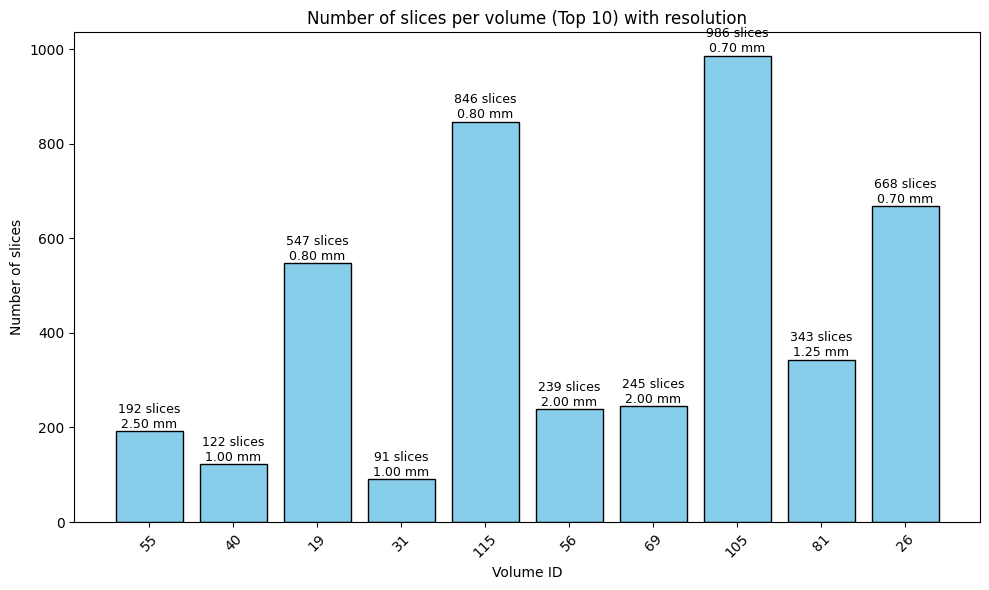

In [11]:
import matplotlib.pyplot as plt
import nibabel as nib

# Limiter aux 10 premiers volumes
data10 = slice_stats_df.sample(frac=1, random_state=42).head(10).copy()

# Calculer la résolution de slicing (épaisseur des coupes en mm) pour chaque volume
resolutions = []
for _, row in data10.iterrows():
    volume_id = row['volume_id']
    seg_path = df[df['volume_id'] == volume_id]['segmentation_path'].iloc[0]
    seg_nii = nib.load(seg_path)
    header = seg_nii.header
    slice_thickness = header.get_zooms()[2]  # résolution le long de l’axe z en mm
    resolutions.append(slice_thickness)

data10['slice_resolution_mm'] = resolutions

# Créer le bar chart
fig, ax = plt.subplots(figsize=(10,6))
bars = ax.bar(data10['volume_id'].astype(str), data10['slices_total'],
              color='skyblue', edgecolor='black')

# Annoter chaque barre avec nb slices et résolution
for bar, slices, res in zip(bars, data10['slices_total'], data10['slice_resolution_mm']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{slices} slices\n{res:.2f} mm",
            ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Volume ID')
ax.set_ylabel('Number of slices')
ax.set_title('Number of slices per volume (Top 10) with resolution')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Visualisation d'un Échantillon (Image + Masques)

In [12]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 07:50:45


Echantillon volume_id: 0
Slice analysee: 58 (slice avec le plus de pixels tumeur)
Valeurs uniques masque brut: [0. 1. 2.]
Valeurs uniques liver_mask: [0 1]
Valeurs uniques tumor_mask: [0 1]
Nb pixels liver: 27172
Nb pixels tumor: 538


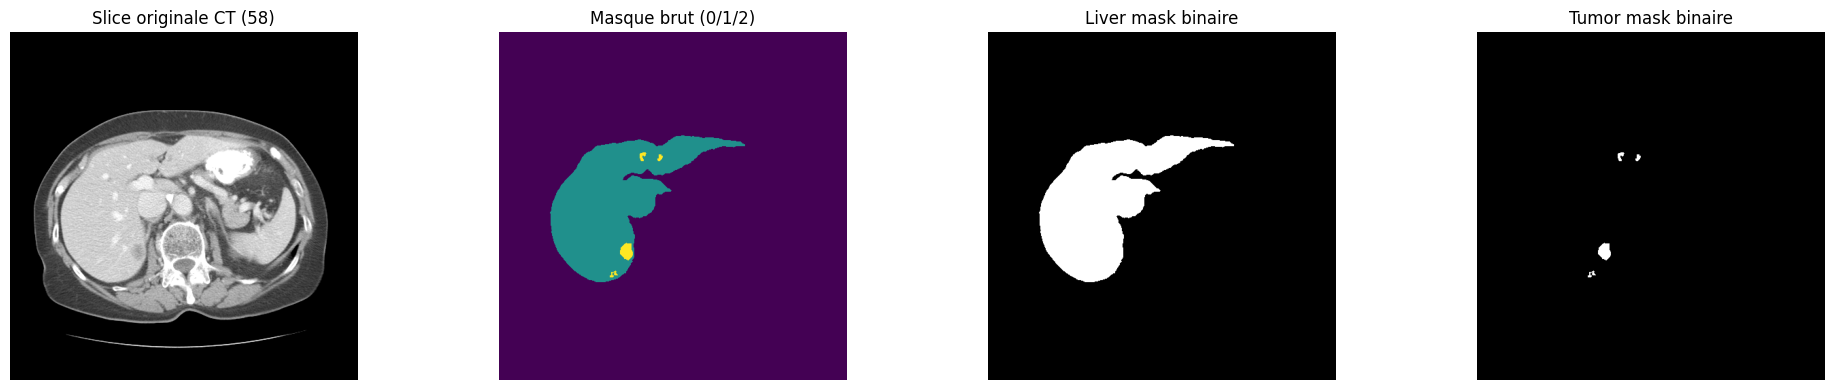

In [13]:

# Valeurs de pixels d'un echantillon de masque (au debut)

sample_idx = 0  # changer l'index si besoin
row = df.iloc[sample_idx]

seg_nii = nib.load(row['segmentation_path'])
seg_data = seg_nii.get_fdata()

# Comptage par slice pour eviter de tomber sur une slice vide
num_slices = seg_data.shape[2]
liver_counts = np.zeros(num_slices, dtype=np.int64)
tumor_counts = np.zeros(num_slices, dtype=np.int64)

for z in range(num_slices):
    s = seg_data[:, :, z]
    liver_counts[z] = np.count_nonzero(s >= 1)
    tumor_counts[z] = np.count_nonzero(s == 2)

# Choix automatique: priorite a une slice avec tumeur, sinon foie, sinon centre
if tumor_counts.max() > 0:
    slice_idx = int(np.argmax(tumor_counts))
    selected_reason = "slice avec le plus de pixels tumeur"
elif liver_counts.max() > 0:
    slice_idx = int(np.argmax(liver_counts))
    selected_reason = "slice avec le plus de pixels foie"
else:
    slice_idx = num_slices // 2
    selected_reason = "aucun label trouve, fallback centre"

mask_slice = seg_data[:, :, slice_idx]

# Charger le volume CT et extraire la meme slice
vol_nii = nib.load(row['volume_path'])
vol_data = vol_nii.get_fdata()
vol_slice = np.clip(vol_data[:, :, slice_idx], -200, 200)
vol_slice = (vol_slice - (-200)) / (200 - (-200))  # normalise [0,1]

# Masques binaires
liver_mask = (mask_slice >= 1).astype(np.uint8)
tumor_mask = (mask_slice == 2).astype(np.uint8)

print(f"Echantillon volume_id: {row['volume_id']}")
print(f"Slice analysee: {slice_idx} ({selected_reason})")
print("Valeurs uniques masque brut:", np.unique(mask_slice))
print("Valeurs uniques liver_mask:", np.unique(liver_mask))
print("Valeurs uniques tumor_mask:", np.unique(tumor_mask))
print("Nb pixels liver:", int(liver_mask.sum()))
print("Nb pixels tumor:", int(tumor_mask.sum()))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))

axes[0].imshow(vol_slice.T, cmap='gray', origin='lower')
axes[0].set_title(f'Slice originale CT ({slice_idx})')
axes[0].axis('off')

axes[1].imshow(mask_slice.T, cmap='viridis', origin='lower')
axes[1].set_title('Masque brut (0/1/2)')
axes[1].axis('off')

axes[2].imshow(liver_mask.T, cmap='gray', origin='lower')
axes[2].set_title('Liver mask binaire')
axes[2].axis('off')

axes[3].imshow(tumor_mask.T, cmap='gray', origin='lower')
axes[3].set_title('Tumor mask binaire')
axes[3].axis('off')

plt.tight_layout()
plt.show()


## 5. Préparation des Données 2-Stage

Helpers d'extraction des masques, puis datasets dédiés foie et tumeur.

In [14]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 07:50:46


In [15]:

# ========== 🧩 1. EXTRACTION DES MASQUES (FOIE / TUMEUR) ==========

def extract_liver_mask(mask_data):
    """
    Extrait le masque du foie à partir du masque multi-classe LiTS.
    Label 0: background
    Label 1: foie
    Label 2: tumeur (incluse dans foie)
    
    Retour: masque binaire foie (0/1)
    """
    liver = np.where((mask_data == 1) | (mask_data == 2), 1, 0)
    return liver.astype(np.uint8)

def extract_tumor_mask(mask_data):
    """
    Extrait le masque de la tumeur à partir du masque multi-classe LiTS.
    Retour: masque binaire tumeur (0/1)
    """
    tumor = np.where(mask_data == 2, 1, 0)
    return tumor.astype(np.uint8)

# ========== 🧩 CALCUL DE LA BOUNDING BOX DU MASQUE ==========
def get_bounding_box(mask):
    """
    Récupère la bounding box d'un masque binaire.
    Args:
        mask: array 2D (H, W)
    Returns:
        tuple: (y_min, y_max, x_min, x_max)
    """
    coords = np.argwhere(mask > 0)
    if len(coords) == 0:
        return 0, mask.shape[0], 0, mask.shape[1]  # image complète si vide
    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)
    return int(y_min), int(y_max), int(x_min), int(x_max)

In [16]:
# ========== 1. CLASSE DE BASE ==========
class BaseSegmentationDataset(Dataset):
    """
    Classe de base pour les datasets de segmentation.
    Gère l'initialisation commune, le lazy loading et le prétraitement.
    """
    def __init__(self, df, mode='train', num_crops=3, crop_size=(480,480)):
        self.df = df
        self.mode = mode
        self.num_crops = num_crops if mode == 'train' else 1
        self.crop_size = crop_size
        self._shape_cache = {}
        self._nii_cache = {}
        self.slice_index = self._create_slice_index()

    def load_slice(self, slice_info):
        """Charge une slice depuis disque (volume + segmentation)."""
        volume_nii = self._load_nii(slice_info['volume_path'])
        seg_nii = self._load_nii(slice_info['seg_path'])
        slice_idx = slice_info['slice_idx']
        volume_25d = self.create_25d_slice(volume_nii, slice_idx)
        mask_2d = np.asarray(seg_nii.dataobj[:, :, slice_idx], dtype=np.int64)
        return volume_25d, mask_2d
    
    def _load_nii(self, path): 
        if path not in self._nii_cache:
            self._nii_cache[path] = nib.load(path)
        return self._nii_cache[path]

    def _get_num_slices(self, volume_path):
        if volume_path not in self._shape_cache:
            self._shape_cache[volume_path] = self._load_nii(volume_path).shape[2]
        return self._shape_cache[volume_path]
    
    def _create_slice_index(self):
        """Cree un index de toutes les slices 2.5D possibles"""
        slice_list = []
        
        for idx in tqdm(range(len(self.df)), desc="Indexing LIVER"):
            row = self.df.iloc[idx]
            num_slices = self._get_num_slices(row['volume_path'])
            # 1, num_slices-1? pour eviter les slices extremites qui n'ont pas de voisin precedent/suivant pour creer une slice 2.5D (3 canaux: precedent, courant, suivant).
            for slice_idx in range(1, num_slices - 1):
                for crop_idx in range(self.num_crops):
                    slice_list.append({
                        'volume_path': row['volume_path'],
                        'seg_path': row['segmentation_path'],
                        'volume_id': row['volume_id'],
                        'slice_idx': slice_idx,
                        'crop_idx': crop_idx
                    })
        return slice_list
    
    def __len__(self):
        return len(self.slice_index)
    
    @staticmethod #static method: cette methode n'utilise pas l'instance de la classe (self) et peut etre appelee directement sur la classe sans creer une instance : LiverDataset._normalize.
    #ici, _normalize_slice est une fonction utilitaire qui normalise une slice 2D en utilisant une fenetre de valeurs (windowing) pour les images CT, et elle n'a pas besoin d'accéder aux attributs de l'instance.
    def _normalize_slice(slice_2d, window_min=-200, window_max=200):
        slice_clip = np.clip(slice_2d, window_min, window_max)
        slice_norm = (slice_clip - window_min) / (window_max - window_min)
        return slice_norm.astype(np.float32)
    
    @staticmethod
    def build_25d_slice(volume_data, slice_idx, window_min=-200, window_max=200):
        """Construit une slice 2.5D normalisée à partir d'un volume 3D ou d'un dataobj nibabel."""
        slice_prev = BaseSegmentationDataset._normalize_slice(np.asarray(volume_data[:, :, slice_idx - 1], dtype=np.float32), window_min, window_max)
        slice_curr = BaseSegmentationDataset._normalize_slice(np.asarray(volume_data[:, :, slice_idx], dtype=np.float32), window_min, window_max)
        slice_next = BaseSegmentationDataset._normalize_slice(np.asarray(volume_data[:, :, slice_idx + 1], dtype=np.float32), window_min, window_max)
        return np.stack([slice_prev, slice_curr, slice_next], axis=0)
    
    @staticmethod
    def center_crop_or_pad_25d(volume_25d, crop_size=(480, 480)):
        """Centre-crop une slice 2.5D et pad si nécessaire pour garder une taille fixe."""
        _, height, width = volume_25d.shape
        crop_h, crop_w = crop_size
        top = max(0, (height - crop_h) // 2)
        left = max(0, (width - crop_w) // 2)
        cropped = volume_25d[:, top:top + crop_h, left:left + crop_w]
        pad_h = max(0, crop_h - cropped.shape[1])
        pad_w = max(0, crop_w - cropped.shape[2])
        if pad_h > 0 or pad_w > 0:
            pad_top = pad_h // 2
            pad_bottom = pad_h - pad_top
            pad_left = pad_w // 2
            pad_right = pad_w - pad_left
            cropped = np.pad(
                cropped,
                ((0, 0), (pad_top, pad_bottom), (pad_left, pad_right)),
                mode='constant',
                constant_values=0,
            )
        return cropped[:, :crop_h, :crop_w], top, left
    
    def create_25d_slice(self, volume_nii, slice_idx):
        """Cree une entree 2.5D (3 slices consecutives) sans charger tout le volume"""
        return BaseSegmentationDataset.build_25d_slice(volume_nii.dataobj, slice_idx)

    def crop(self, volume_25d, mask):
        """Random crop en train, center crop en val/test"""
        _, H, W = volume_25d.shape
        crop_h, crop_w = self.crop_size
        
        if self.mode == 'train':
            top = np.random.randint(0, max(1, H - crop_h + 1))
            left = np.random.randint(0, max(1, W - crop_w + 1))
        else:
            top = max(0, (H - crop_h) // 2)
            left = max(0, (W - crop_w) // 2)
        
        volume_cropped = volume_25d[:, top:top+crop_h, left:left+crop_w]
        mask_cropped = mask[top:top+crop_h, left:left+crop_w]
        
        # Si la slice est plus petite que crop_size, on pad de facon centree pour garder une taille fixe
        pad_h = max(0, crop_h - volume_cropped.shape[1])
        pad_w = max(0, crop_w - volume_cropped.shape[2])
        if pad_h > 0 or pad_w > 0:
            pad_top = pad_h // 2
            pad_bottom = pad_h - pad_top
            pad_left = pad_w // 2
            pad_right = pad_w - pad_left

            volume_cropped = np.pad(
                volume_cropped,
                ((0, 0), (pad_top, pad_bottom), (pad_left, pad_right)),
                mode='constant',
                constant_values=0,
            )
            mask_cropped = np.pad(
                mask_cropped,
                ((pad_top, pad_bottom), (pad_left, pad_right)),
                mode='constant',
                constant_values=0,
            )
        
        return volume_cropped[:, :crop_h, :crop_w], mask_cropped[:crop_h, :crop_w]
    
    def augment(self, volume, mask):
        """Augmentations geometriques aleatoires"""
        if self.mode != 'train':
            return volume, mask
        
        if np.random.rand() > 0.5:
            volume = np.flip(volume, axis=2).copy()
            mask = np.flip(mask, axis=1).copy()
        
        if np.random.rand() > 0.5:
            volume = np.flip(volume, axis=1).copy()
            mask = np.flip(mask, axis=0).copy()
        
        return volume, mask

In [17]:
# =========== 2. DATASET POUR LE FOIE UNIQUEMENT ==========

class LiverDataset(BaseSegmentationDataset):
    """
    Dataset pour segmentation du FOIE uniquement.
    Chargement lazy: seules les slices utiles sont lues depuis disque.
    """
   
    def __getitem__(self, idx):
        """Charge et traite une slice a la volee (FOIE UNIQUEMENT)"""
        slice_info = self.slice_index[idx]
        slice_idx = slice_info['slice_idx']

        volume_nii = self._load_nii(slice_info['volume_path'])
        seg_nii = self._load_nii(slice_info['seg_path'])
        
        volume_25d = self.create_25d_slice(volume_nii, slice_idx)
        mask_2d = np.asarray(seg_nii.dataobj[:, :, slice_idx], dtype=np.int64)
        
        liver_mask = extract_liver_mask(mask_2d).astype(np.float32)
        volume_cropped, mask_cropped = self.crop(volume_25d, liver_mask)
        volume_aug, mask_aug = self.augment(volume_cropped, mask_cropped)
        
        return {
            'image': torch.from_numpy(volume_aug).float(),
            'liver_mask': torch.from_numpy(mask_aug).unsqueeze(0).float(),
            'seg_path': slice_info['seg_path'],
            'slice_idx': slice_idx,
            'volume_id': int(slice_info['volume_id']),
        }

In [18]:
 # ========== 3. DATASET POUR LA TUMEUR (DANS ROI FOIE) ==========

class TumorDataset(BaseSegmentationDataset):
    """
    Dataset pour segmentation de la TUMEUR dans la ROI du foie.
    Chargement lazy: seules les slices utiles sont lues depuis disque.
    """
    
    def __init__(self, df, mode='train', num_crops=3, crop_size=(480,480), margin=20, neg_pos_ratio=1.0):
        self.neg_pos_ratio = float(neg_pos_ratio)
        super().__init__(df, mode, num_crops, crop_size)
        self.margin = margin
  
    def _create_slice_index(self):
        """
        Index tumeur:
        - train: toutes les slices positives + sous-échantillonnage des négatives
        - val/test: toutes les slices
        """
        slice_list = []
        pos_slices = []
        neg_slices = []
        
        for idx in tqdm(range(len(self.df)), desc="Indexing TUMOR"):
            row = self.df.iloc[idx]
            num_slices = self._get_num_slices(row['volume_path'])
            seg_nii = self._load_nii(row['segmentation_path'])
            seg_obj = seg_nii.dataobj

            for slice_idx in range(1, num_slices - 1):
                mask_2d = np.asarray(seg_obj[:, :, slice_idx], dtype=np.int64)
                has_tumor = bool((mask_2d == 2).any())

                for crop_idx in range(self.num_crops):
                    item = {
                        'volume_path': row['volume_path'],
                        'seg_path': row['segmentation_path'],
                        'volume_id': row['volume_id'],
                        'slice_idx': slice_idx,
                        'crop_idx': crop_idx
                    }
                    if has_tumor:
                        pos_slices.append(item)
                    else:
                        neg_slices.append(item)

        if self.mode == 'train':
            if len(pos_slices) == 0:
                slice_list = neg_slices
            else:
                rng = np.random.default_rng(42)
                max_neg = int(len(pos_slices) * self.neg_pos_ratio)
                max_neg = min(max_neg, len(neg_slices))
                if max_neg > 0:
                    neg_idx = rng.choice(len(neg_slices), size=max_neg, replace=False)
                    sampled_neg = [neg_slices[i] for i in neg_idx]
                else:
                    sampled_neg = []
                slice_list = pos_slices + sampled_neg
                rng.shuffle(slice_list)

            print(f"Tumor train index: pos={len(pos_slices)} | neg_kept={len(slice_list)-len(pos_slices)}")
        else:
            slice_list = pos_slices + neg_slices
            print(f"Tumor {self.mode} index: pos={len(pos_slices)} | neg={len(neg_slices)}")

        return slice_list
  
    def crop_roi_around_liver(self, volume_25d, liver_mask):
        """
        Crop une ROI autour du foie detecte.
        Returns:
            volume_roi: tensor croppe
            roi_coords: dict avec y_min, y_max, x_min, x_max
        """
        y_min, y_max, x_min, x_max = get_bounding_box(liver_mask)
        
        y_min = max(0, y_min - self.margin)
        y_max = min(volume_25d.shape[1], y_max + self.margin)
        x_min = max(0, x_min - self.margin)
        x_max = min(volume_25d.shape[2], x_max + self.margin)
        
        volume_roi = volume_25d[:, y_min:y_max, x_min:x_max]
        roi_coords = {
            'y_min': y_min, 'y_max': y_max,
            'x_min': x_min, 'x_max': x_max
        }
        
        return volume_roi, roi_coords
    
    def __getitem__(self, idx):
        """Charge et traite une slice a la volee (TUMEUR DANS ROI FOIE)"""
        slice_info = self.slice_index[idx]
        slice_idx = slice_info['slice_idx']
        
        volume_nii = self._load_nii(slice_info['volume_path'])
        seg_nii = self._load_nii(slice_info['seg_path'])
        
        volume_25d = self.create_25d_slice(volume_nii, slice_idx)
        mask_2d = np.asarray(seg_nii.dataobj[:, :, slice_idx], dtype=np.int64)
        
        liver_mask = extract_liver_mask(mask_2d).astype(np.float32)
        tumor_mask = extract_tumor_mask(mask_2d).astype(np.float32)
        
        volume_roi, roi_coords = self.crop_roi_around_liver(volume_25d, liver_mask)
        tumor_roi = tumor_mask[roi_coords['y_min']:roi_coords['y_max'],
                               roi_coords['x_min']:roi_coords['x_max']]
        
        volume_cropped, tumor_cropped = self.crop(volume_roi, tumor_roi)
        volume_aug, tumor_aug = self.augment(volume_cropped, tumor_cropped)
        
        return {
            'image': torch.from_numpy(volume_aug).float(),
            'tumor_mask': torch.from_numpy(tumor_aug).unsqueeze(0).float(),
        }

## 6. Modèle UNet

Définition de l'architecture utilisée pour les deux stages (foie et tumeur).

In [19]:
# ========== MODELE UNet (UTILISE PAR LES 2 STAGES) ==========

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, dropout_p=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        ]
        if dropout_p > 0:
            layers.append(nn.Dropout2d(p=dropout_p))
        self.double_conv = nn.Sequential(*layers)

    def forward(self, x):
        return self.double_conv(x)


class AttentionGate(nn.Module):
    def __init__(self, gate_channels, skip_channels, inter_channels):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(gate_channels, inter_channels, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(inter_channels),
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(skip_channels, inter_channels, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(inter_channels),
        )
        self.relu = nn.ReLU(inplace=True)
        self.psi = nn.Sequential(
            nn.Conv2d(inter_channels, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid(),
        )

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi


class Down(nn.Module):
    def __init__(self, in_channels, out_channels, dropout_p=0.0):
        super().__init__()
        self.down = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels, dropout_p=dropout_p),
        )

    def forward(self, x):
        return self.down(x)

class Up(nn.Module):
    def __init__(self, in_channels, out_channels, dropout_p=0.0, use_attention=False):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
        self.use_attention = bool(use_attention)
        if self.use_attention:
            self.attention = AttentionGate(
                gate_channels=in_channels // 2,
                skip_channels=in_channels // 2,
                inter_channels=max(1, (in_channels // 2) // 2),
            )
        self.conv = DoubleConv(in_channels, out_channels, dropout_p=dropout_p)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        diff_y = x2.size()[2] - x1.size()[2]
        diff_x = x2.size()[3] - x1.size()[3]
        x1 = F.pad(x1, [diff_x // 2, diff_x - diff_x // 2, diff_y // 2, diff_y - diff_y // 2])
        if self.use_attention:
            x2 = self.attention(x1, x2)
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, n_channels, n_classes, base_channels=64, dropout_p=0.0, use_attention=False):
        super().__init__()
        c1 = base_channels
        c2 = c1 * 2
        c3 = c2 * 2
        c4 = c3 * 2
        c5 = c4 * 2

        self.in_conv = DoubleConv(n_channels, c1, dropout_p=dropout_p)
        self.down1 = Down(c1, c2, dropout_p=dropout_p)
        self.down2 = Down(c2, c3, dropout_p=dropout_p)
        self.down3 = Down(c3, c4, dropout_p=dropout_p)
        self.down4 = Down(c4, c5, dropout_p=dropout_p)
        self.up1 = Up(c5, c4, dropout_p=dropout_p, use_attention=use_attention)
        self.up2 = Up(c4, c3, dropout_p=dropout_p, use_attention=use_attention)
        self.up3 = Up(c3, c2, dropout_p=dropout_p, use_attention=use_attention)
        self.up4 = Up(c2, c1, dropout_p=dropout_p, use_attention=use_attention)
        self.out_conv = nn.Conv2d(c1, n_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.in_conv(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.out_conv(x)


UNET_EXPERIMENTS = {
    "baseline": {"dropout_p": 0.0, "use_attention": False},
    "dropout": {"dropout_p": 0.20, "use_attention": False},
    "dropout_attention": {"dropout_p": 0.20, "use_attention": True},
    "attention": {"dropout_p": 0.00, "use_attention": True},

}

# Choix actif: baseline | dropout | dropout_attention
UNET_EXPERIMENT = "attention"

if UNET_EXPERIMENT not in UNET_EXPERIMENTS:
    raise ValueError(f"UNET_EXPERIMENT invalide: {UNET_EXPERIMENT}")


def build_unet_from_experiment(n_channels=3, n_classes=1):
    cfg = UNET_EXPERIMENTS[UNET_EXPERIMENT]
    return UNet(
        n_channels=n_channels,
        n_classes=n_classes,
        dropout_p=cfg["dropout_p"],
        use_attention=cfg["use_attention"],
    )


print(f"UNET_EXPERIMENT = {UNET_EXPERIMENT} | cfg={UNET_EXPERIMENTS[UNET_EXPERIMENT]}")

UNET_EXPERIMENT = attention | cfg={'dropout_p': 0.0, 'use_attention': True}


## 7. Entraînement 2-Stage (Split 70/15/15)

### Générer les deux datasets (Foie et Tumeur)

In [20]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 07:50:46


In [21]:
# ========== 4. GENERER LES 2 DATASETS (FOIE + TUMEUR) ==========
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
torch.cuda.empty_cache()

train_ratio = 0.70
val_ratio   = 0.15
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
train_size  = int(train_ratio * len(df_shuffled))
val_size    = int(val_ratio   * len(df_shuffled))
train_df    = df_shuffled.iloc[:train_size].reset_index(drop=True)
val_df      = df_shuffled.iloc[train_size:train_size + val_size].reset_index(drop=True)
test_df     = df_shuffled.iloc[train_size + val_size:].reset_index(drop=True)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)} volumes")

TRAIN_SPEED_PROFILE = "fast"
if TRAIN_SPEED_PROFILE == "fast":
    liver_num_crops = 1
    tumor_num_crops = 1
elif TRAIN_SPEED_PROFILE == "balanced":
    liver_num_crops = 2
    tumor_num_crops = 2
else:
    liver_num_crops = 3
    tumor_num_crops = 3
print(f"Profil: {TRAIN_SPEED_PROFILE} | liver_num_crops={liver_num_crops}, tumor_num_crops={tumor_num_crops}")

num_workers = 0
pin_memory  = torch.cuda.is_available()
BATCH_SIZE  = 16  # 16GB GPU, ~4.5GB used -> 16 est safe et optimal

print("\n=== DATASET FOIE ===")
liver_train_dataset = LiverDataset(train_df, mode='train', num_crops=liver_num_crops)
liver_val_dataset   = LiverDataset(val_df,   mode='val')
liver_test_dataset  = LiverDataset(test_df,  mode='val')
liver_train_loader  = DataLoader(liver_train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=num_workers, pin_memory=pin_memory)
liver_val_loader    = DataLoader(liver_val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)
liver_test_loader   = DataLoader(liver_test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)
print(f"Train batches: {len(liver_train_loader)} | Val batches: {len(liver_val_loader)} | Test batches: {len(liver_test_loader)}")
BATCH_SIZE_TUMOR = 4  # 16GB GPU, ~4.5GB used -> 16 est safe et optimal

print("\n=== DATASET TUMEUR (ROI FOIE) ===")
tumor_train_dataset = TumorDataset(train_df, mode='train', num_crops=tumor_num_crops)
tumor_val_dataset   = TumorDataset(val_df,   mode='val')
tumor_test_dataset  = TumorDataset(test_df,  mode='val')
tumor_train_loader  = DataLoader(tumor_train_dataset, batch_size=BATCH_SIZE_TUMOR, shuffle=True,  num_workers=num_workers, pin_memory=pin_memory)
tumor_val_loader    = DataLoader(tumor_val_dataset,   batch_size=BATCH_SIZE_TUMOR, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)
tumor_test_loader   = DataLoader(tumor_test_dataset,  batch_size=BATCH_SIZE_TUMOR, shuffle=False, num_workers=num_workers, pin_memory=pin_memory)
print(f"Train batches: {len(tumor_train_loader)} | Val batches: {len(tumor_val_loader)} | Test batches: {len(tumor_test_loader)}")

Train: 91 | Val: 19 | Test: 21 volumes
Profil: fast | liver_num_crops=1, tumor_num_crops=1

=== DATASET FOIE ===


Indexing LIVER: 100%|██████████| 21/21 [00:00<00:00, 340.81it/s]


Train batches: 2464 | Val batches: 482 | Test batches: 704

=== DATASET TUMEUR (ROI FOIE) ===


Indexing TUMOR: 100%|██████████| 91/91 [00:11<00:00,  7.83it/s]


Tumor train index: pos=5212 | neg_kept=5212


Indexing TUMOR: 100%|██████████| 19/19 [00:02<00:00,  8.84it/s]


Tumor val index: pos=1040 | neg=6666


Indexing TUMOR: 100%|██████████| 21/21 [00:03<00:00,  6.23it/s]

Tumor val index: pos=938 | neg=10323
Train batches: 2606 | Val batches: 1927 | Test batches: 2816


### 7.1 Stage 1: Entraîner le modèle FOIE

In [22]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 07:51:03


In [23]:
# # ========== STAGE 1: ENTRAINER LE MODELE FOIE ==========
# from pathlib import Path
# import gc

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print(f"Device: {device}\\n")

# model_liver     = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)
# criterion_liver = nn.BCEWithLogitsLoss()
# optimizer_liver = torch.optim.Adam(model_liver.parameters(), lr=1e-4)
# scaler          = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

# output_dir = Path("outputs")
# output_dir.mkdir(parents=True, exist_ok=True)
# experiment_suffix     = "" if UNET_EXPERIMENT == "baseline" else f"_{UNET_EXPERIMENT}"
# LIVER_MODEL_PATH      = str(output_dir / f"model_liver{experiment_suffix}.pth")
# LIVER_BEST_MODEL_PATH = str(output_dir / f"best_model_liver{experiment_suffix}.pth")

# # Dossier dedie pour TOUS les checkpoints FOIE
# LIVER_CKPT_DIR        = output_dir / "checkpoints_liver_dropout_attention"
# LIVER_CKPT_DIR.mkdir(parents=True, exist_ok=True)
# LIVER_CKPT_LATEST_PATH = LIVER_CKPT_DIR / f"latest_liver{experiment_suffix}.pth"
# print(f"Experiment stage FOIE: {UNET_EXPERIMENT}")
# print(f"Dossier checkpoints FOIE: {LIVER_CKPT_DIR}")

# num_epochs_liver     = 8
# CKPT_EVERY_N_BATCHES = 50

# start_epoch_liver = 0
# start_batch_liver = 0
# best_val_dice     = float("-inf")

# def save_liver_checkpoint(epoch, batch_idx, is_interrupt=False):
#     payload = {
#         "epoch": int(epoch),
#         "batch_idx": int(batch_idx),
#         "model_state_dict": model_liver.state_dict(),
#         "optimizer_state_dict": optimizer_liver.state_dict(),
#         "best_val_dice": float(best_val_dice),
#         "interrupted": bool(is_interrupt),
#     }
#     if batch_idx >= 0:
#         ckpt_name = f"checkpoint_liver{experiment_suffix}_e{epoch:03d}_b{batch_idx:05d}.pth"
#     else:
#         ckpt_name = f"checkpoint_liver{experiment_suffix}_e{epoch:03d}_end.pth"
#     ckpt_path = LIVER_CKPT_DIR / ckpt_name
#     torch.save(payload, ckpt_path)
#     torch.save(payload, LIVER_CKPT_LATEST_PATH)
#     return ckpt_path

# latest_liver_ckpt = None
# if LIVER_CKPT_LATEST_PATH.exists():
#     latest_liver_ckpt = LIVER_CKPT_LATEST_PATH
# else:
#     liver_ckpt_candidates = sorted(LIVER_CKPT_DIR.glob(f"checkpoint_liver{experiment_suffix}_*.pth"), key=lambda p: p.stat().st_mtime)
#     if liver_ckpt_candidates:
#         latest_liver_ckpt = liver_ckpt_candidates[-1]

# if latest_liver_ckpt is not None:
#     print(f"Checkpoint FOIE trouve: {latest_liver_ckpt}")
#     ckpt = torch.load(latest_liver_ckpt, map_location=device)
#     model_liver.load_state_dict(ckpt["model_state_dict"])
#     optimizer_liver.load_state_dict(ckpt["optimizer_state_dict"])
#     best_val_dice = float(ckpt.get("best_val_dice", float("-inf")))
#     ckpt_epoch    = int(ckpt.get("epoch", -1))
#     ckpt_batch    = int(ckpt.get("batch_idx", -1))
#     if ckpt_batch >= 0:
#         start_epoch_liver = ckpt_epoch
#         start_batch_liver = ckpt_batch + 1
#     else:
#         start_epoch_liver = ckpt_epoch + 1
#         start_batch_liver = 0
#     print(f"Reprise FOIE: epoch={start_epoch_liver}/{num_epochs_liver}, batch={start_batch_liver}, best_val_dice={best_val_dice:.4f}")
# else:
#     print("Aucun checkpoint FOIE trouve dans le dossier dedie, entrainement depuis zero.")

# if start_epoch_liver >= num_epochs_liver:
#     print("Entrainement FOIE deja termine pour ce num_epochs.")
# else:
#     print("=" * 60)
#     print("ENTRAINEMENT DU MODELE FOIE")
#     print("=" * 60)

#     current_epoch = start_epoch_liver
#     current_batch = max(-1, start_batch_liver - 1)

#     try:
#         for epoch in range(start_epoch_liver, num_epochs_liver):
#             model_liver.train()
#             train_loss        = 0.0
#             processed_batches = 0
#             epoch_start_batch = start_batch_liver if epoch == start_epoch_liver else 0

#             for batch_idx, batch in enumerate(tqdm(liver_train_loader, desc=f"LIVER Train {epoch+1}/{num_epochs_liver}")):
#                 if batch_idx < epoch_start_batch:
#                     continue

#                 images      = batch['image'].to(device)
#                 liver_masks = batch['liver_mask'].to(device)

#                 optimizer_liver.zero_grad()
#                 with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
#                     outputs = model_liver(images)
#                     loss    = criterion_liver(outputs, liver_masks)
#                 scaler.scale(loss).backward()
#                 scaler.step(optimizer_liver)
#                 scaler.update()

#                 train_loss        += loss.item()
#                 processed_batches += 1
#                 current_epoch      = epoch
#                 current_batch      = batch_idx

#             if processed_batches == 0:
#                 print(f"Aucun batch entraine pour epoch {epoch}.")
#                 continue

#             avg_train_loss = train_loss / max(1, processed_batches)

#             # Validation
#             model_liver.eval()
#             val_dice, val_batches = 0.0, 0
#             with torch.no_grad():
#                 for batch in tqdm(liver_val_loader, desc=f"LIVER Val {epoch+1}/{num_epochs_liver}", leave=False):
#                     images      = batch['image'].to(device)
#                     liver_masks = batch['liver_mask'].to(device)
#                     with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
#                         outputs = model_liver(images)
#                     probs = torch.sigmoid(outputs)
#                     pred  = (probs > 0.5).float()
#                     tp    = (pred * liver_masks).sum()
#                     fp    = pred.sum() - tp
#                     fn    = liver_masks.sum() - tp
#                     dice  = (2.0 * tp + 1.0) / (2.0 * tp + fp + fn + 1.0)
#                     val_dice    += dice.item()
#                     val_batches += 1

#             avg_val_dice = val_dice / max(1, val_batches)
#             print(f"Epoch {epoch+1}/{num_epochs_liver} | Train Loss: {avg_train_loss:.4f} | Val Dice: {avg_val_dice:.4f}")

#             if avg_val_dice > best_val_dice:
#                 best_val_dice = avg_val_dice
#                 torch.save(model_liver.state_dict(), LIVER_BEST_MODEL_PATH)
#                 print(f"Nouveau best FOIE sauvegarde (val_dice={best_val_dice:.4f}): {LIVER_BEST_MODEL_PATH}")

#             ckpt_path = save_liver_checkpoint(epoch, -1, is_interrupt=False)
#             print(f"Checkpoint FOIE fin d'epoch sauvegarde: {ckpt_path}")
#             start_batch_liver = 0

#     except KeyboardInterrupt:
#         print("\\nInterruption detectee. Sauvegarde de securite en cours...")
#         ckpt_path = save_liver_checkpoint(current_epoch, current_batch, is_interrupt=True)
#         print(f"Checkpoint FOIE securise: {ckpt_path} (epoch={current_epoch}, batch={current_batch}, best={best_val_dice:.4f})")

# # Export final: sauvegarder uniquement le meilleur modele
# if Path(LIVER_BEST_MODEL_PATH).exists():
#     model_liver.load_state_dict(torch.load(LIVER_BEST_MODEL_PATH, map_location=device))
#     torch.save(model_liver.state_dict(), LIVER_MODEL_PATH)
#     print(f"\\nModele FOIE final (best) exporte vers: {LIVER_MODEL_PATH}")
# else:
#     print("\\nAucun best model FOIE disponible: export final ignore pour respecter la regle 'best only'.")

# print(f"Best FOIE: {LIVER_BEST_MODEL_PATH}")
# print(f"Dernier checkpoint FOIE: {LIVER_CKPT_LATEST_PATH}\\n")

In [24]:
# ========== STAGE 1: ENTRAINER LE MODELE FOIE ==========
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}\n")

model_liver     = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)
criterion_liver = nn.BCEWithLogitsLoss()
optimizer_liver = torch.optim.Adam(model_liver.parameters(), lr=1e-4)
scaler          = torch.amp.GradScaler('cuda')

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)
experiment_suffix     = "" if UNET_EXPERIMENT == "baseline" else f"_{UNET_EXPERIMENT}"
LIVER_MODEL_PATH      = str(output_dir / f"model_liver{experiment_suffix}.pth")
LIVER_CKPT_DIR        = output_dir / f"checkpoints_liver_{UNET_EXPERIMENT}"
LIVER_CKPT_DIR.mkdir(parents=True, exist_ok=True)
LIVER_CKPT_PATH       = str(LIVER_CKPT_DIR / "latest.pth")
LIVER_BEST_MODEL_PATH = str(output_dir / f"best_model_liver{experiment_suffix}.pth")
print(f"Experiment stage FOIE: {UNET_EXPERIMENT}")

num_epochs_liver     = 8

start_epoch_liver = 0
start_batch_liver = 0
best_val_dice     = float("-inf")

if Path(LIVER_BEST_MODEL_PATH).exists():
    print(f"Best model FOIE trouve: {LIVER_BEST_MODEL_PATH}")
    model_liver.load_state_dict(torch.load(LIVER_BEST_MODEL_PATH, map_location=device))
    start_epoch_liver = num_epochs_liver
    print("Chargement BEST prioritaire. Entrainement considere termine pour ce num_epochs.")
elif Path(LIVER_CKPT_PATH).exists():
    ckpt = torch.load(LIVER_CKPT_PATH, map_location=device)
    model_liver.load_state_dict(ckpt["model_state_dict"])
    optimizer_liver.load_state_dict(ckpt["optimizer_state_dict"])
    best_val_dice = float(ckpt.get("best_val_dice", float("-inf")))
    ckpt_epoch    = int(ckpt.get("epoch", -1))
    ckpt_batch    = int(ckpt.get("batch_idx", -1))
    if ckpt_batch >= 0:
        start_epoch_liver = ckpt_epoch
        start_batch_liver = ckpt_batch + 1
    else:
        start_epoch_liver = ckpt_epoch + 1
        start_batch_liver = 0
    print(f"Reprise FOIE: epoch={start_epoch_liver}/{num_epochs_liver}, batch={start_batch_liver}, best_val_dice={best_val_dice:.4f}")
else:
    print("Aucun best_model ni checkpoint FOIE trouve, entrainement depuis zero.")

if start_epoch_liver >= num_epochs_liver:
    print("Entrainement FOIE deja termine pour ce num_epochs.")
else:
    print("=" * 60)
    print("ENTRAINEMENT DU MODELE FOIE")
    print("=" * 60)

    current_epoch = start_epoch_liver
    current_batch = max(-1, start_batch_liver - 1)

    try:
        for epoch in range(start_epoch_liver, num_epochs_liver):
            model_liver.train()
            train_loss        = 0.0
            processed_batches = 0
            epoch_start_batch = start_batch_liver if epoch == start_epoch_liver else 0

            for batch_idx, batch in enumerate(tqdm(liver_train_loader, desc=f"LIVER Train {epoch+1}/{num_epochs_liver}")):
                if batch_idx < epoch_start_batch:
                    continue

                images      = batch['image'].to(device)
                liver_masks = batch['liver_mask'].to(device)

                optimizer_liver.zero_grad()
                with torch.amp.autocast('cuda'):
                    outputs = model_liver(images)
                    loss    = criterion_liver(outputs, liver_masks)
                scaler.scale(loss).backward()
                scaler.step(optimizer_liver)
                scaler.update()

                train_loss        += loss.item()
                processed_batches += 1
                current_epoch      = epoch
                current_batch      = batch_idx

                # Pas de checkpoint par batch: on sauvegarde seulement un checkpoint complet

            if processed_batches == 0:
                print(f"Aucun batch entraine pour epoch {epoch}.")
                continue

            avg_train_loss = train_loss / max(1, processed_batches)

            # Validation
            model_liver.eval()
            val_dice, val_batches = 0.0, 0
            with torch.no_grad():
                for batch in tqdm(liver_val_loader, desc=f"LIVER Val {epoch+1}/{num_epochs_liver}", leave=False):
                    images      = batch['image'].to(device)
                    liver_masks = batch['liver_mask'].to(device)
                    with torch.amp.autocast('cuda'):
                        outputs = model_liver(images)
                    probs = torch.sigmoid(outputs)
                    pred  = (probs > 0.5).float()
                    tp    = (pred * liver_masks).sum()
                    fp    = pred.sum() - tp
                    fn    = liver_masks.sum() - tp
                    dice  = (2.0 * tp + 1.0) / (2.0 * tp + fp + fn + 1.0)
                    val_dice    += dice.item()
                    val_batches += 1

            avg_val_dice = val_dice / max(1, val_batches)
            print(f"Epoch {epoch+1}/{num_epochs_liver} | Train Loss: {avg_train_loss:.4f} | Val Dice: {avg_val_dice:.4f}")

            if avg_val_dice > best_val_dice:
                best_val_dice = avg_val_dice
                torch.save(model_liver.state_dict(), LIVER_BEST_MODEL_PATH)
                print(f"Nouveau best FOIE sauvegarde (val_dice={best_val_dice:.4f}): {LIVER_BEST_MODEL_PATH}")

            torch.save({
                "epoch": epoch, "batch_idx": -1,
                "model_state_dict": model_liver.state_dict(),
                "optimizer_state_dict": optimizer_liver.state_dict(),
                "best_val_dice": best_val_dice,
            }, LIVER_CKPT_PATH)
            torch.save({
                "epoch": epoch, "batch_idx": -1,
                "model_state_dict": model_liver.state_dict(),
                "optimizer_state_dict": optimizer_liver.state_dict(),
                "best_val_dice": best_val_dice,
            }, str(LIVER_CKPT_DIR / f"checkpoint_epoch_{epoch:03d}.pth"))

            start_batch_liver = 0

    except KeyboardInterrupt:
        print("\nInterruption detectee. Sauvegarde de securite en cours...")
    finally:
        torch.save({
            "epoch": current_epoch, "batch_idx": current_batch,
            "model_state_dict": model_liver.state_dict(),
            "optimizer_state_dict": optimizer_liver.state_dict(),
            "best_val_dice": best_val_dice,
        }, LIVER_CKPT_PATH)
        print(f"Checkpoint FOIE securise: {LIVER_CKPT_PATH} (epoch={current_epoch}, batch={current_batch}, best={best_val_dice:.4f})")

if Path(LIVER_BEST_MODEL_PATH).exists():
    model_liver.load_state_dict(torch.load(LIVER_BEST_MODEL_PATH, map_location=device))
    torch.save(model_liver.state_dict(), LIVER_MODEL_PATH)
    print(f"\nModele FOIE (best) exporte vers: {LIVER_MODEL_PATH}")
else:
    torch.save(model_liver.state_dict(), LIVER_MODEL_PATH)
    print(f"\nModele FOIE (courant) sauvegarde: {LIVER_MODEL_PATH}")

print(f"Best FOIE: {LIVER_BEST_MODEL_PATH}")
print(f"Checkpoint FOIE (latest): {LIVER_CKPT_PATH}\n")

Device: cuda

Experiment stage FOIE: attention
Aucun best_model ni checkpoint FOIE trouve, entrainement depuis zero.
ENTRAINEMENT DU MODELE FOIE


LIVER Train 1/8: 100%|██████████| 2464/2464 [42:49<00:00,  1.04s/it]
                                                                

Epoch 1/8 | Train Loss: 0.1079 | Val Dice: 0.7549
Nouveau best FOIE sauvegarde (val_dice=0.7549): outputs/best_model_liver_attention.pth


LIVER Train 2/8: 100%|██████████| 2464/2464 [42:26<00:00,  1.03s/it]
                                                                

Epoch 2/8 | Train Loss: 0.0155 | Val Dice: 0.8353
Nouveau best FOIE sauvegarde (val_dice=0.8353): outputs/best_model_liver_attention.pth


...

Epoch 6/8 | Train Loss: 0.0043 | Val Dice: 0.7457


LIVER Train 7/8: 100%|██████████| 2464/2464 [41:17<00:00,  1.01s/it]
                                                                

Epoch 7/8 | Train Loss: 0.0039 | Val Dice: 0.8996
Nouveau best FOIE sauvegarde (val_dice=0.8996): outputs/best_model_liver_attention.pth


LIVER Train 8/8: 100%|██████████| 2464/2464 [41:48<00:00,  1.02s/it]
                                                                

Epoch 8/8 | Train Loss: 0.0038 | Val Dice: 0.7783
Checkpoint FOIE securise: outputs/checkpoints_liver_attention/latest.pth (epoch=7, batch=2463, best=0.8996)

Modele FOIE (best) exporte vers: outputs/model_liver_attention.pth
Best FOIE: outputs/best_model_liver_attention.pth
Checkpoint FOIE (latest): outputs/checkpoints_liver_attention/latest.pth



In [25]:
# # ========== STAGE 1: ENTRAINER LE MODELE FOIE ==========
# from pathlib import Path

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print(f"Device: {device}\n")

# model_liver     = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)
# criterion_liver = nn.BCEWithLogitsLoss()
# optimizer_liver = torch.optim.Adam(model_liver.parameters(), lr=1e-4)
# scaler          = torch.amp.GradScaler('cuda')

# output_dir = Path("outputs")
# output_dir.mkdir(parents=True, exist_ok=True)
# experiment_suffix     = "" if UNET_EXPERIMENT == "baseline" else f"_{UNET_EXPERIMENT}"
# LIVER_MODEL_PATH      = str(output_dir / f"model_liver{experiment_suffix}.pth")
# LIVER_CKPT_PATH       = str(output_dir / f"checkpoint_liver{experiment_suffix}.pth")
# LIVER_BEST_MODEL_PATH = str(output_dir / f"best_model_liver{experiment_suffix}.pth")
# print(f"Experiment stage FOIE: {UNET_EXPERIMENT}")

# num_epochs_liver     = 8
# CKPT_EVERY_N_BATCHES = 50

# start_epoch_liver = 0
# start_batch_liver = 0
# best_val_dice     = float("-inf")

# if Path(LIVER_BEST_MODEL_PATH).exists():
#     print(f"Best model FOIE trouve: {LIVER_BEST_MODEL_PATH}")
#     model_liver.load_state_dict(torch.load(LIVER_BEST_MODEL_PATH, map_location=device))
#     start_epoch_liver = num_epochs_liver
#     print("Chargement BEST prioritaire. Entrainement considere termine pour ce num_epochs.")
# elif Path(LIVER_CKPT_PATH).exists():
#     ckpt = torch.load(LIVER_CKPT_PATH, map_location=device)
#     model_liver.load_state_dict(ckpt["model_state_dict"])
#     optimizer_liver.load_state_dict(ckpt["optimizer_state_dict"])
#     best_val_dice = float(ckpt.get("best_val_dice", float("-inf")))
#     ckpt_epoch    = int(ckpt.get("epoch", -1))
#     ckpt_batch    = int(ckpt.get("batch_idx", -1))
#     if ckpt_batch >= 0:
#         start_epoch_liver = ckpt_epoch
#         start_batch_liver = ckpt_batch + 1
#     else:
#         start_epoch_liver = ckpt_epoch + 1
#         start_batch_liver = 0
#     print(f"Reprise FOIE: epoch={start_epoch_liver}/{num_epochs_liver}, batch={start_batch_liver}, best_val_dice={best_val_dice:.4f}")
# else:
#     print("Aucun best_model ni checkpoint FOIE trouve, entrainement depuis zero.")

# if start_epoch_liver >= num_epochs_liver:
#     print("Entrainement FOIE deja termine pour ce num_epochs.")
# else:
#     print("=" * 60)
#     print("ENTRAINEMENT DU MODELE FOIE")
#     print("=" * 60)

#     current_epoch = start_epoch_liver
#     current_batch = max(-1, start_batch_liver - 1)

#     try:
#         for epoch in range(start_epoch_liver, num_epochs_liver):
#             model_liver.train()
#             train_loss        = 0.0
#             processed_batches = 0
#             epoch_start_batch = start_batch_liver if epoch == start_epoch_liver else 0

#             for batch_idx, batch in enumerate(tqdm(liver_train_loader, desc=f"LIVER Train {epoch+1}/{num_epochs_liver}")):
#                 if batch_idx < epoch_start_batch:
#                     continue

#                 images      = batch['image'].to(device)
#                 liver_masks = batch['liver_mask'].to(device)

#                 optimizer_liver.zero_grad()
#                 with torch.amp.autocast('cuda'):
#                     outputs = model_liver(images)
#                     loss    = criterion_liver(outputs, liver_masks)
#                 scaler.scale(loss).backward()
#                 scaler.step(optimizer_liver)
#                 scaler.update()

#                 train_loss        += loss.item()
#                 processed_batches += 1
#                 current_epoch      = epoch
#                 current_batch      = batch_idx

#                 if ((batch_idx + 1) % CKPT_EVERY_N_BATCHES) == 0:
#                     torch.save({
#                         "epoch": epoch, "batch_idx": batch_idx,
#                         "model_state_dict": model_liver.state_dict(),
#                         "optimizer_state_dict": optimizer_liver.state_dict(),
#                         "best_val_dice": best_val_dice,
#                     }, LIVER_CKPT_PATH)

#             if processed_batches == 0:
#                 print(f"Aucun batch entraine pour epoch {epoch}.")
#                 continue

#             avg_train_loss = train_loss / max(1, processed_batches)

#             # Validation
#             model_liver.eval()
#             val_dice, val_batches = 0.0, 0
#             with torch.no_grad():
#                 for batch in tqdm(liver_val_loader, desc=f"LIVER Val {epoch+1}/{num_epochs_liver}", leave=False):
#                     images      = batch['image'].to(device)
#                     liver_masks = batch['liver_mask'].to(device)
#                     with torch.amp.autocast('cuda'):
#                         outputs = model_liver(images)
#                     probs = torch.sigmoid(outputs)
#                     pred  = (probs > 0.5).float()
#                     tp    = (pred * liver_masks).sum()
#                     fp    = pred.sum() - tp
#                     fn    = liver_masks.sum() - tp
#                     dice  = (2.0 * tp + 1.0) / (2.0 * tp + fp + fn + 1.0)
#                     val_dice    += dice.item()
#                     val_batches += 1

#             avg_val_dice = val_dice / max(1, val_batches)
#             print(f"Epoch {epoch+1}/{num_epochs_liver} | Train Loss: {avg_train_loss:.4f} | Val Dice: {avg_val_dice:.4f}")

#             if avg_val_dice > best_val_dice:
#                 best_val_dice = avg_val_dice
#                 torch.save(model_liver.state_dict(), LIVER_BEST_MODEL_PATH)
#                 print(f"Nouveau best FOIE sauvegarde (val_dice={best_val_dice:.4f}): {LIVER_BEST_MODEL_PATH}")

#             torch.save({
#                 "epoch": epoch, "batch_idx": -1,
#                 "model_state_dict": model_liver.state_dict(),
#                 "optimizer_state_dict": optimizer_liver.state_dict(),
#                 "best_val_dice": best_val_dice,
#             }, LIVER_CKPT_PATH)

#             start_batch_liver = 0

#     except KeyboardInterrupt:
#         print("\nInterruption detectee. Sauvegarde de securite en cours...")
#     finally:
#         torch.save({
#             "epoch": current_epoch, "batch_idx": current_batch,
#             "model_state_dict": model_liver.state_dict(),
#             "optimizer_state_dict": optimizer_liver.state_dict(),
#             "best_val_dice": best_val_dice,
#         }, LIVER_CKPT_PATH)
#         print(f"Checkpoint FOIE securise: {LIVER_CKPT_PATH} (epoch={current_epoch}, batch={current_batch}, best={best_val_dice:.4f})")

# if Path(LIVER_BEST_MODEL_PATH).exists():
#     model_liver.load_state_dict(torch.load(LIVER_BEST_MODEL_PATH, map_location=device))
#     torch.save(model_liver.state_dict(), LIVER_MODEL_PATH)
#     print(f"\nModele FOIE (best) exporte vers: {LIVER_MODEL_PATH}")
# else:
#     torch.save(model_liver.state_dict(), LIVER_MODEL_PATH)
#     print(f"\nModele FOIE (courant) sauvegarde: {LIVER_MODEL_PATH}")

# print(f"Best FOIE: {LIVER_BEST_MODEL_PATH}")
# print(f"Checkpoint FOIE: {LIVER_CKPT_PATH}\n")

### 7.2 Stage 2: Entraîner le modèle TUMEUR

In [26]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 13:53:32


In [62]:
# ========== STAGE 2: ENTRAINER LE MODELE TUMEUR ==========
from pathlib import Path
import gc

# Configuration memoire CUDA (anti-fragmentation)
if torch.cuda.is_available():
    # Liberer la memoire GPU du modele foie si present
    if "model_liver" in globals():
        try:
            model_liver = model_liver.cpu()
        except Exception:
            pass
    gc.collect()
    torch.cuda.empty_cache()

model_tumor = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)

TUMOR_POS_WEIGHT = 6.0
criterion_tumor  = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([TUMOR_POS_WEIGHT], dtype=torch.float32, device=device)
)
optimizer_tumor = torch.optim.Adam(model_tumor.parameters(), lr=1e-4)
scaler_tumor    = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

# Micro-batch pour limiter le pic de memoire GPU
TUMOR_MICRO_BATCH_SIZE = 2

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)
experiment_suffix     = "" if UNET_EXPERIMENT == "baseline" else f"_{UNET_EXPERIMENT}"
LIVER_MODEL_PATH      = str(output_dir / f"model_liver{experiment_suffix}.pth")
TUMOR_MODEL_PATH      = str(output_dir / f"model_tumor{experiment_suffix}.pth")
TUMOR_CKPT_PATH       = str(output_dir / f"checkpoint_tumor{experiment_suffix}.pth")
TUMOR_BEST_MODEL_PATH = str(output_dir / f"best_model_tumor{experiment_suffix}.pth")
TUMOR_EPOCH_CKPT_DIR  = output_dir / f"checkpoints_tumor{experiment_suffix}"
TUMOR_EPOCH_CKPT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Experiment stage TUMEUR: {UNET_EXPERIMENT}")
print(f"Checkpoints epoch TUMEUR: {TUMOR_EPOCH_CKPT_DIR}")

num_epochs_tumor     = 20

start_epoch_tumor   = 0
start_batch_tumor   = 0
best_val_dice_tumor = float("-inf")

def extract_epoch_num(p: Path) -> int:
    try:
        return int(p.stem.split("_")[1])
    except Exception:
        return -1

print(f"Dossier reprise TUMEUR: {TUMOR_EPOCH_CKPT_DIR} | existe={TUMOR_EPOCH_CKPT_DIR.exists()}")
if TUMOR_EPOCH_CKPT_DIR.exists():
    epoch_files = sorted(
        [p for p in TUMOR_EPOCH_CKPT_DIR.glob("epoch_*.pth") if extract_epoch_num(p) >= 0],
        key=extract_epoch_num
    )
else:
    epoch_files = []

if epoch_files:
    last_epoch_file = epoch_files[-1]
    last_epoch_num = extract_epoch_num(last_epoch_file)
    print(f"Epochs TUMEUR trouves: {len(epoch_files)} | Dernier: {last_epoch_file.name}")

    ckpt = torch.load(last_epoch_file, map_location=device)
    model_tumor.load_state_dict(ckpt["model_state_dict"])
    optimizer_tumor.load_state_dict(ckpt["optimizer_state_dict"])
    if "scaler_state_dict" in ckpt:
        scaler_tumor.load_state_dict(ckpt["scaler_state_dict"])
    best_val_dice_tumor = float(ckpt.get("best_val_dice", float("-inf")))

    start_epoch_tumor = max(0, last_epoch_num)
    start_batch_tumor = 0
    print(f"Reprise TUMEUR OK -> start_epoch_tumor={start_epoch_tumor} (premier epoch affiche={start_epoch_tumor + 1})")
    print(f"Best val_dice TUMEUR: {best_val_dice_tumor:.4f}")

elif Path(TUMOR_CKPT_PATH).exists():
    print(f"Checkpoint TUMEUR trouve (fallback): {TUMOR_CKPT_PATH}")
    ckpt = torch.load(TUMOR_CKPT_PATH, map_location=device)
    model_tumor.load_state_dict(ckpt["model_state_dict"])
    optimizer_tumor.load_state_dict(ckpt["optimizer_state_dict"])
    if "scaler_state_dict" in ckpt:
        scaler_tumor.load_state_dict(ckpt["scaler_state_dict"])
    best_val_dice_tumor = float(ckpt.get("best_val_dice", float("-inf")))
    ckpt_epoch = int(ckpt.get("epoch", -1))
    ckpt_batch = int(ckpt.get("batch_idx", -1))
    if ckpt_batch >= 0:
        start_epoch_tumor = ckpt_epoch
        start_batch_tumor = ckpt_batch + 1
    else:
        start_epoch_tumor = ckpt_epoch + 1
        start_batch_tumor = 0
    print(f"Reprise fallback checkpoint global: epoch={start_epoch_tumor}, batch={start_batch_tumor}, best_val_dice={best_val_dice_tumor:.4f}")

elif Path(TUMOR_BEST_MODEL_PATH).exists():
    print(f"Best model TUMEUR trouve: {TUMOR_BEST_MODEL_PATH}")
    model_tumor.load_state_dict(torch.load(TUMOR_BEST_MODEL_PATH, map_location=device))
    print("Best model charge, pas de checkpoint epoch trouve.")

else:
    print("Aucun checkpoint TUMEUR trouve, entrainement depuis zero.")

if start_epoch_tumor >= num_epochs_tumor:
    print("Entrainement TUMEUR deja termine pour ce num_epochs_tumor.")
else:
    print("=" * 60)
    print("ENTRAINEMENT DU MODELE TUMEUR")
    print("=" * 60)
    print(f"pos_weight BCE tumeur = {TUMOR_POS_WEIGHT}")

    current_epoch_tumor = start_epoch_tumor
    current_batch_tumor = max(-1, start_batch_tumor - 1)

    try:
        for epoch in range(start_epoch_tumor, num_epochs_tumor):
            model_tumor.train()
            train_loss        = 0.0
            processed_batches = 0
            epoch_start_batch = start_batch_tumor if epoch == start_epoch_tumor else 0

            for batch_idx, batch in enumerate(tqdm(tumor_train_loader, desc=f"TUMOR Train {epoch+1}/{num_epochs_tumor}")):
                if batch_idx < epoch_start_batch:
                    continue

                images      = batch['image'].to(device)
                tumor_masks = batch['tumor_mask'].to(device)

                optimizer_tumor.zero_grad()
                with torch.amp.autocast('cuda'):
                    outputs = model_tumor(images)
                    loss    = criterion_tumor(outputs, tumor_masks)
                scaler_tumor.scale(loss).backward()
                scaler_tumor.step(optimizer_tumor)
                scaler_tumor.update()

                train_loss        += loss.item()
                processed_batches += 1
                current_epoch_tumor = epoch
                current_batch_tumor = batch_idx

                # Pas de checkpoint par batch: checkpoint entier par epoch uniquement

            if processed_batches == 0:
                print(f"Aucun batch entraine pour epoch {epoch}.")
                continue

            avg_train_loss = train_loss / max(1, processed_batches)

            # Validation
            model_tumor.eval()
            val_dice, val_batches = 0.0, 0
            with torch.no_grad():
                for batch in tqdm(tumor_val_loader, desc=f"TUMOR Val {epoch+1}/{num_epochs_tumor}", leave=False):
                    images      = batch['image'].to(device)
                    tumor_masks = batch['tumor_mask'].to(device)
                    with torch.amp.autocast('cuda'):
                        outputs = model_tumor(images)
                    probs = torch.sigmoid(outputs)
                    pred  = (probs > 0.5).float()
                    tp    = (pred * tumor_masks).sum()
                    fp    = pred.sum() - tp
                    fn    = tumor_masks.sum() - tp
                    dice  = (2.0 * tp + 1.0) / (2.0 * tp + fp + fn + 1.0)
                    val_dice    += dice.item()
                    val_batches += 1

            avg_val_dice = val_dice / max(1, val_batches)
            print(f"Epoch {epoch+1}/{num_epochs_tumor} | Train Loss: {avg_train_loss:.4f} | Val Dice: {avg_val_dice:.4f}")

            if avg_val_dice > best_val_dice_tumor:
                best_val_dice_tumor = avg_val_dice
                torch.save(model_tumor.state_dict(), TUMOR_BEST_MODEL_PATH)
                print(f"Nouveau best TUMEUR sauvegarde (val_dice={best_val_dice_tumor:.4f}): {TUMOR_BEST_MODEL_PATH}")

            epoch_ckpt_path = TUMOR_EPOCH_CKPT_DIR / f"epoch_{epoch + 1:03d}.pth"
            full_ckpt = {
                "epoch": epoch,
                "epoch_1_based": epoch + 1,
                "batch_idx": -1,
                "model_state_dict": model_tumor.state_dict(),
                "optimizer_state_dict": optimizer_tumor.state_dict(),
                "scaler_state_dict": scaler_tumor.state_dict(),
                "best_val_dice": best_val_dice_tumor,
                "avg_train_loss": float(avg_train_loss),
                "avg_val_dice": float(avg_val_dice),
                "stage": "tumor",
                "experiment": UNET_EXPERIMENT,
            }
            torch.save(full_ckpt, epoch_ckpt_path)
            torch.save(full_ckpt, TUMOR_CKPT_PATH)
            print(f"Checkpoint epoch TUMEUR sauvegarde: {epoch_ckpt_path}")

            start_batch_tumor = 0

    except KeyboardInterrupt:
        print("\nInterruption detectee pendant le stage TUMEUR. Sauvegarde de securite en cours...")
    finally:
        torch.save({
            "epoch": current_epoch_tumor, "batch_idx": current_batch_tumor,
            "model_state_dict": model_tumor.state_dict(),
            "optimizer_state_dict": optimizer_tumor.state_dict(),
            "scaler_state_dict": scaler_tumor.state_dict(),
            "best_val_dice": best_val_dice_tumor,
        }, TUMOR_CKPT_PATH)
        print(f"Checkpoint TUMEUR securise: {TUMOR_CKPT_PATH} (epoch={current_epoch_tumor}, batch={current_batch_tumor}, best={best_val_dice_tumor:.4f})")

if Path(TUMOR_BEST_MODEL_PATH).exists():
    model_tumor.load_state_dict(torch.load(TUMOR_BEST_MODEL_PATH, map_location=device))
    torch.save(model_tumor.state_dict(), TUMOR_MODEL_PATH)
    print(f"\nModele TUMEUR (best) exporte vers: {TUMOR_MODEL_PATH}")
else:
    torch.save(model_tumor.state_dict(), TUMOR_MODEL_PATH)
    print(f"\nModele TUMEUR (courant) sauvegarde: {TUMOR_MODEL_PATH}")

print(f"Best TUMEUR: {TUMOR_BEST_MODEL_PATH}")
print(f"Checkpoint TUMEUR (global): {TUMOR_CKPT_PATH}")
print(f"Checkpoints par epoch TUMEUR: {TUMOR_EPOCH_CKPT_DIR}\n")

Experiment stage TUMEUR: attention
Checkpoints epoch TUMEUR: outputs/checkpoints_tumor_attention
Dossier reprise TUMEUR: outputs/checkpoints_tumor_attention | existe=True


NameError: name 're' is not defined

In [28]:
# # ========== STAGE 2: ENTRAINER LE MODELE TUMEUR ==========
# from pathlib import Path
# import gc

# # Configuration memoire CUDA (anti-fragmentation)
# if torch.cuda.is_available():
#     # Liberer la memoire GPU du modele foie si present
#     if "model_liver" in globals():
#         try:
#             model_liver = model_liver.cpu()
#         except Exception:
#             pass
#     gc.collect()
#     torch.cuda.empty_cache()

# model_tumor = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)

# TUMOR_POS_WEIGHT = 6.0
# criterion_tumor  = nn.BCEWithLogitsLoss(
#     pos_weight=torch.tensor([TUMOR_POS_WEIGHT], dtype=torch.float32, device=device)
# )
# optimizer_tumor = torch.optim.Adam(model_tumor.parameters(), lr=1e-4)
# scaler_tumor    = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

# # Micro-batch pour limiter le pic de memoire GPU
# TUMOR_MICRO_BATCH_SIZE = 2

# output_dir = Path("outputs")
# output_dir.mkdir(parents=True, exist_ok=True)
# experiment_suffix     = "" if UNET_EXPERIMENT == "baseline" else f"_{UNET_EXPERIMENT}"
# LIVER_MODEL_PATH      = str(output_dir / f"model_liver{experiment_suffix}.pth")
# TUMOR_MODEL_PATH      = str(output_dir / f"model_tumor{experiment_suffix}.pth")
# TUMOR_CKPT_PATH       = str(output_dir / f"checkpoint_tumor{experiment_suffix}.pth")
# TUMOR_BEST_MODEL_PATH = str(output_dir / f"best_model_tumor{experiment_suffix}.pth")
# print(f"Experiment stage TUMEUR: {UNET_EXPERIMENT}")

# num_epochs_tumor     = 20
# CKPT_EVERY_N_BATCHES = 50

# start_epoch_tumor   = 0
# start_batch_tumor   = 0
# best_val_dice_tumor = float("-inf")

# if Path(TUMOR_BEST_MODEL_PATH).exists():
#     print(f"Best model TUMEUR trouve: {TUMOR_BEST_MODEL_PATH}")
#     model_tumor.load_state_dict(torch.load(TUMOR_BEST_MODEL_PATH, map_location=device))
#     start_epoch_tumor = num_epochs_tumor
#     print("Chargement BEST prioritaire. Entrainement considere termine pour ce num_epochs_tumor.")
# elif Path(TUMOR_CKPT_PATH).exists():
#     print(f"Checkpoint TUMEUR trouve: {TUMOR_CKPT_PATH}")
#     ckpt = torch.load(TUMOR_CKPT_PATH, map_location=device)
#     model_tumor.load_state_dict(ckpt["model_state_dict"])
#     optimizer_tumor.load_state_dict(ckpt["optimizer_state_dict"])
#     best_val_dice_tumor = float(ckpt.get("best_val_dice", float("-inf")))
#     ckpt_epoch          = int(ckpt.get("epoch", -1))
#     ckpt_batch          = int(ckpt.get("batch_idx", -1))
#     if ckpt_batch >= 0:
#         start_epoch_tumor = ckpt_epoch
#         start_batch_tumor = ckpt_batch + 1
#     else:
#         start_epoch_tumor = ckpt_epoch + 1
#         start_batch_tumor = 0
#     print(f"Reprise TUMEUR: epoch={start_epoch_tumor}/{num_epochs_tumor}, batch={start_batch_tumor}, best_val_dice={best_val_dice_tumor:.4f}")
# else:
#     print("Aucun best_model ni checkpoint TUMEUR trouve, entrainement depuis zero.")

# if start_epoch_tumor >= num_epochs_tumor:
#     print("Entrainement TUMEUR deja termine pour ce num_epochs_tumor.")
# else:
#     print("=" * 60)
#     print("ENTRAINEMENT DU MODELE TUMEUR")
#     print("=" * 60)
#     print(f"pos_weight BCE tumeur = {TUMOR_POS_WEIGHT}")

#     current_epoch_tumor = start_epoch_tumor
#     current_batch_tumor = max(-1, start_batch_tumor - 1)

#     try:
#         for epoch in range(start_epoch_tumor, num_epochs_tumor):
#             model_tumor.train()
#             train_loss        = 0.0
#             processed_batches = 0
#             epoch_start_batch = start_batch_tumor if epoch == start_epoch_tumor else 0

#             for batch_idx, batch in enumerate(tqdm(tumor_train_loader, desc=f"TUMOR Train {epoch+1}/{num_epochs_tumor}")):
#                 if batch_idx < epoch_start_batch:
#                     continue

#                 images      = batch['image'].to(device)
#                 tumor_masks = batch['tumor_mask'].to(device)

#                 optimizer_tumor.zero_grad()
#                 with torch.amp.autocast('cuda'):
#                     outputs = model_tumor(images)
#                     loss    = criterion_tumor(outputs, tumor_masks)
#                 scaler_tumor.scale(loss).backward()
#                 scaler_tumor.step(optimizer_tumor)
#                 scaler_tumor.update()

#                 train_loss        += loss.item()
#                 processed_batches += 1
#                 current_epoch_tumor = epoch
#                 current_batch_tumor = batch_idx

#                 if ((batch_idx + 1) % CKPT_EVERY_N_BATCHES) == 0:
#                     torch.save({
#                         "epoch": epoch, "batch_idx": batch_idx,
#                         "model_state_dict": model_tumor.state_dict(),
#                         "optimizer_state_dict": optimizer_tumor.state_dict(),
#                         "best_val_dice": best_val_dice_tumor,
#                     }, TUMOR_CKPT_PATH)

#             if processed_batches == 0:
#                 print(f"Aucun batch entraine pour epoch {epoch}.")
#                 continue

#             avg_train_loss = train_loss / max(1, processed_batches)

#             # Validation
#             model_tumor.eval()
#             val_dice, val_batches = 0.0, 0
#             with torch.no_grad():
#                 for batch in tqdm(tumor_val_loader, desc=f"TUMOR Val {epoch+1}/{num_epochs_tumor}", leave=False):
#                     images      = batch['image'].to(device)
#                     tumor_masks = batch['tumor_mask'].to(device)
#                     with torch.amp.autocast('cuda'):
#                         outputs = model_tumor(images)
#                     probs = torch.sigmoid(outputs)
#                     pred  = (probs > 0.5).float()
#                     tp    = (pred * tumor_masks).sum()
#                     fp    = pred.sum() - tp
#                     fn    = tumor_masks.sum() - tp
#                     dice  = (2.0 * tp + 1.0) / (2.0 * tp + fp + fn + 1.0)
#                     val_dice    += dice.item()
#                     val_batches += 1

#             avg_val_dice = val_dice / max(1, val_batches)
#             print(f"Epoch {epoch+1}/{num_epochs_tumor} | Train Loss: {avg_train_loss:.4f} | Val Dice: {avg_val_dice:.4f}")

#             if avg_val_dice > best_val_dice_tumor:
#                 best_val_dice_tumor = avg_val_dice
#                 torch.save(model_tumor.state_dict(), TUMOR_BEST_MODEL_PATH)
#                 print(f"Nouveau best TUMEUR sauvegarde (val_dice={best_val_dice_tumor:.4f}): {TUMOR_BEST_MODEL_PATH}")

#             torch.save({
#                 "epoch": epoch, "batch_idx": -1,
#                 "model_state_dict": model_tumor.state_dict(),
#                 "optimizer_state_dict": optimizer_tumor.state_dict(),
#                 "best_val_dice": best_val_dice_tumor,
#             }, TUMOR_CKPT_PATH)

#             start_batch_tumor = 0

#     except KeyboardInterrupt:
#         print("\nInterruption detectee pendant le stage TUMEUR. Sauvegarde de securite en cours...")
#     finally:
#         torch.save({
#             "epoch": current_epoch_tumor, "batch_idx": current_batch_tumor,
#             "model_state_dict": model_tumor.state_dict(),
#             "optimizer_state_dict": optimizer_tumor.state_dict(),
#             "best_val_dice": best_val_dice_tumor,
#         }, TUMOR_CKPT_PATH)
#         print(f"Checkpoint TUMEUR securise: {TUMOR_CKPT_PATH} (epoch={current_epoch_tumor}, batch={current_batch_tumor}, best={best_val_dice_tumor:.4f})")

# if Path(TUMOR_BEST_MODEL_PATH).exists():
#     model_tumor.load_state_dict(torch.load(TUMOR_BEST_MODEL_PATH, map_location=device))
#     torch.save(model_tumor.state_dict(), TUMOR_MODEL_PATH)
#     print(f"\nModele TUMEUR (best) exporte vers: {TUMOR_MODEL_PATH}")
# else:
#     torch.save(model_tumor.state_dict(), TUMOR_MODEL_PATH)
#     print(f"\nModele TUMEUR (courant) sauvegarde: {TUMOR_MODEL_PATH}")

# print(f"Best TUMEUR: {TUMOR_BEST_MODEL_PATH}")
# print(f"Checkpoint TUMEUR: {TUMOR_CKPT_PATH}\n")

## 8. Inférence 2-Stage

In [32]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 18:42:08


In [33]:

import gc

# ========== 🧩 5. PIPELINE 2-STAGE POUR L'INFÉRENCE ==========

class TwoStagePipeline:
    """
    Pipeline d'inférence 2-stage:
    1) Segmenter le foie
    2) Crop autour du foie
    3) Segmenter la tumeur dans la ROI
    4) Reconstruire dans l'image complète
    5) Appliquer constraint: tumor ⊂ liver
    """
    
    def __init__(self, model_liver, model_tumor, device, margin=20, tumor_threshold=0.3):
        self.model_liver = model_liver
        self.model_tumor = model_tumor
        self.device = device
        self.margin = margin
        self.tumor_threshold = float(tumor_threshold)
    
    def forward(self, image_25d, return_probs=False):
        """
        Args:
            image_25d: tensor (3, H, W) ou (B, 3, H, W)
            return_probs: si True, retourne aussi probs_tumor_full
        
        Returns:
            pred_liver: tensor binaire (H, W)
            pred_tumor: tensor binaire (H, W)
            probs_tumor_full (optionnel): tensor probabilites (H, W)
        """
        if image_25d.dim() == 3:
            image_25d = image_25d.unsqueeze(0)  # (1, 3, H, W)
        
        image_25d = image_25d.to(self.device, non_blocking=True)
        _, _, H, W = image_25d.shape
        
        # STAGE 1: FOIE
        self.model_liver.eval()
        with torch.no_grad():
            outputs_liver = self.model_liver(image_25d)
            probs_liver = torch.sigmoid(outputs_liver)
            pred_liver = (probs_liver > 0.5).float().squeeze(0).squeeze(0)
        
        # STAGE 2: TUMEUR
        self.model_tumor.eval()
        pred_tumor_full = torch.zeros((H, W), device=self.device)
        probs_tumor_full = torch.zeros((H, W), device=self.device)
        
        with torch.no_grad():
            y_min, y_max, x_min, x_max = get_bounding_box(pred_liver.detach().cpu().numpy())
            y_min = max(0, y_min - self.margin)
            y_max = min(H, y_max + self.margin)
            x_min = max(0, x_min - self.margin)
            x_max = min(W, x_max + self.margin)
            
            image_roi = image_25d[:, :, y_min:y_max, x_min:x_max]
            outputs_tumor = self.model_tumor(image_roi)
            probs_tumor = torch.sigmoid(outputs_tumor).squeeze(0).squeeze(0)
            pred_tumor_roi = (probs_tumor > self.tumor_threshold).float()
            
            probs_tumor_full[y_min:y_max, x_min:x_max] = probs_tumor
            pred_tumor_full[y_min:y_max, x_min:x_max] = pred_tumor_roi
        
        # Contrainte anatomique
        pred_tumor_full = pred_tumor_full * pred_liver
        probs_tumor_full = probs_tumor_full * pred_liver
        
        if return_probs:
            return pred_liver, pred_tumor_full, probs_tumor_full
        return pred_liver, pred_tumor_full


# ========== INFÉRENCE SUR LE SET TEST ==========

print("=" * 60)
print("INFÉRENCE 2-STAGE SUR TEST SET")
print("=" * 60)

# Synchroniser explicitement les modèles sur le bon device après le stage 2
if torch.cuda.is_available():
    gc.collect()
    torch.cuda.empty_cache()

model_liver = model_liver.to(device)
model_tumor = model_tumor.to(device)

# Charger les modèles (map_location=device pour éviter CPU/GPU mismatch)
model_liver.load_state_dict(torch.load(LIVER_MODEL_PATH, map_location=device))
model_tumor.load_state_dict(torch.load(TUMOR_MODEL_PATH, map_location=device))
model_liver.eval()
model_tumor.eval()

TUMOR_THRESHOLD = 0.30
print(f"Seuil binaire tumeur utilise: {TUMOR_THRESHOLD:.2f}")

# Pipeline
pipeline = TwoStagePipeline(model_liver, model_tumor, device, tumor_threshold=TUMOR_THRESHOLD)

# Métriques test
test_liver_dice = []
test_tumor_dice = []
test_tumor_recall = []

with torch.no_grad():
    for batch_idx, batch in enumerate(tqdm(liver_test_loader, desc="TEST")):
        images = batch['image'].to(device, non_blocking=True)
        B = images.shape[0]
        
        for b in range(B):
            image_single = images[b]
            pred_liver, pred_tumor = pipeline.forward(image_single)
print(f"\n✅ Inférence 2-stage complétée\n")


INFÉRENCE 2-STAGE SUR TEST SET
Seuil binaire tumeur utilise: 0.30


TEST: 100%|██████████| 704/704 [12:33<00:00,  1.07s/it]


✅ Inférence 2-stage complétée



## 9. Évaluation complète : Métriques Foie + Tumeur

In [34]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 18:54:46


In [35]:

# ========== 🧩 6. ÉVALUATION COMPLÈTE 2-STAGE ==========

def compute_metrics(pred, target, smooth=1.0):
    """Calcule Dice, IoU, Precision, Recall, F1"""
    pred = pred.float()
    target = target.float()
    
    tp = (pred * target).sum()
    fp = (pred * (1 - target)).sum()
    fn = ((1 - pred) * target).sum()
    
    dice = (2.0 * tp + smooth) / (2.0 * tp + fp + fn + smooth)
    iou = (tp + smooth) / (tp + fp + fn + smooth)
    precision = (tp + smooth) / (tp + fp + smooth)
    recall = (tp + smooth) / (tp + fn + smooth)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-8)
    
    return {
        'dice': dice.item(),
        'iou': iou.item(),
        'precision': precision.item(),
        'recall': recall.item(),
        'f1': f1.item()
    }


def center_crop_2d(mask_2d, out_h, out_w):
    """Center crop deterministic pour aligner la GT avec les images val/test."""
    h, w = mask_2d.shape
    top = max(0, (h - out_h) // 2)
    left = max(0, (w - out_w) // 2)
    return mask_2d[top:top+out_h, left:left+out_w]


print("=" * 70)
print("TEST COMPLET: FOIE + TUMEUR (2-STAGE PIPELINE)")
print("=" * 70)

metrics_liver_list = []
metrics_tumor_list = []

# Charger les models sauvegardés
model_liver_test = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)
model_tumor_test = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)
model_liver_test.load_state_dict(torch.load(LIVER_MODEL_PATH))
model_tumor_test.load_state_dict(torch.load(TUMOR_MODEL_PATH))

pipeline = TwoStagePipeline(model_liver_test, model_tumor_test, device)

# Test sur le dataset foie uniquement (source de vérité pour l'alignement image/GT)
test_count = 0

with torch.no_grad():
    for batch_liver in tqdm(liver_test_loader, total=len(liver_test_loader), desc="TEST EVALUATION"):
        B = batch_liver['image'].shape[0]
        images_test = batch_liver['image'].to(device)
        
        for b in range(B):
            image_single = images_test[b]  # (3, H, W)
            
            # GT foie déjà alignée au crop de l'image
            liver_gt = batch_liver['liver_mask'][b].squeeze(0).to(device)
            
            # GT tumeur reconstruite depuis la segmentation brute puis center-crop
            seg_path = batch_liver['seg_path'][b]
            slice_idx = int(batch_liver['slice_idx'][b].item())
            seg_slice = np.asarray(nib.load(seg_path).dataobj[:, :, slice_idx], dtype=np.int64)
            tumor_full = extract_tumor_mask(seg_slice).astype(np.float32)
            tumor_crop = center_crop_2d(tumor_full, liver_gt.shape[0], liver_gt.shape[1])
            tumor_gt = torch.from_numpy(tumor_crop).to(device)

            # Prediction
            pred_liver, pred_tumor = pipeline.forward(image_single)

            # Metrics
            metrics_liver_list.append(compute_metrics(pred_liver, liver_gt))
            metrics_tumor_list.append(compute_metrics(pred_tumor, tumor_gt))

            test_count += 1

# Moyennes
avg_liver_metrics = {
    key: np.mean([m[key] for m in metrics_liver_list])
    for key in metrics_liver_list[0].keys()
}
avg_tumor_metrics = {
    key: np.mean([m[key] for m in metrics_tumor_list])
    for key in metrics_tumor_list[0].keys()
}

print("\n" + "=" * 70)
print(f"TEST RESULTS (n={test_count} slices)")

print("=" * 70)
print("\n📊 FOIE (Stage 1)")
print(f"  Dice:      {avg_liver_metrics['dice']:.4f}")
print(f"  IoU:       {avg_liver_metrics['iou']:.4f}")
print(f"  Precision: {avg_liver_metrics['precision']:.4f}")
print(f"  Recall:    {avg_liver_metrics['recall']:.4f}")
print(f"  F1:        {avg_liver_metrics['f1']:.4f}")

print("\n📊 TUMEUR (Stage 2)")
print(f"  Dice:      {avg_tumor_metrics['dice']:.4f}")
print(f"  IoU:       {avg_tumor_metrics['iou']:.4f}")
print(f"  Precision: {avg_tumor_metrics['precision']:.4f}")
print(f"  Recall:    {avg_tumor_metrics['recall']:.4f}")
print(f"  F1:        {avg_tumor_metrics['f1']:.4f}")

print("\n✅ Évaluation complète 2-stage terminée!\n")


TEST COMPLET: FOIE + TUMEUR (2-STAGE PIPELINE)


TEST EVALUATION: 100%|██████████| 704/704 [13:32<00:00,  1.15s/it]


TEST RESULTS (n=11261 slices)

📊 FOIE (Stage 1)
  Dice:      0.9548
  IoU:       0.9436
  Precision: 0.9670
  Recall:    0.9746
  F1:        0.9555

📊 TUMEUR (Stage 2)
  Dice:      0.9074
  IoU:       0.9022
  Precision: 0.9445
  Recall:    0.9434
  F1:        0.9097

✅ Évaluation complète 2-stage terminée!



In [47]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 19:44:33


In [48]:
# ========== 🧩 6. ÉVALUATION COMPLÈTE 2-STAGE (DICE VOLUMIQUE) ==========

def compute_metrics(tp, fp, fn, smooth=1.0):
    """Calcule Dice (VOLUMIQUE), IoU, Precision, Recall, F1 depuis TP/FP/FN"""
    
    # Dice VOLUMIQUE (formula standardisée)
    dice = (2.0 * tp + smooth) / (2.0 * tp + fp + fn + smooth)
    
    # Autres métriques
    iou = (tp + smooth) / (tp + fp + fn + smooth)
    precision = (tp + smooth) / (tp + fp + smooth)
    recall = (tp + smooth) / (tp + fn + smooth)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-8)
    
    return {
        'dice': float(dice),
        'iou': float(iou),
        'precision': float(precision),
        'recall': float(recall),
        'f1': float(f1)
    }

def center_crop_2d(mask_2d, out_h, out_w):
    """Center crop deterministic pour aligner la GT avec les images val/test."""
    h, w = mask_2d.shape
    top = max(0, (h - out_h) // 2)
    left = max(0, (w - out_w) // 2)
    return mask_2d[top:top+out_h, left:left+out_w]

def counts_tp_fp_fn(pred, target):
    """Accumule TP, FP, FN"""
    pred = pred.float()
    target = target.float()
    tp = float((pred * target).sum().item())
    fp = float((pred * (1 - target)).sum().item())
    fn = float(((1 - pred) * target).sum().item())
    return tp, fp, fn

print("=" * 70)
print("TEST COMPLET: FOIE + TUMEUR (2-STAGE PIPELINE - DICE VOLUMIQUE)")
print("=" * 70)

metrics_liver_list = []
metrics_tumor_list = []

# Charger les models sauvegardés
model_liver_test = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)
model_tumor_test = build_unet_from_experiment(n_channels=3, n_classes=1).to(device)
model_liver_test.load_state_dict(torch.load(LIVER_MODEL_PATH))
model_tumor_test.load_state_dict(torch.load(TUMOR_MODEL_PATH))

pipeline = TwoStagePipeline(model_liver_test, model_tumor_test, device)

# Accumulateurs volumiques
volume_test_stats = {}

test_count = 0

with torch.no_grad():
    for batch_liver in tqdm(liver_test_loader, total=len(liver_test_loader), desc="TEST EVALUATION"):
        B = batch_liver['image'].shape[0]
        images_test = batch_liver['image'].to(device)
        
        for b in range(B):
            image_single = images_test[b]

            liver_gt = batch_liver['liver_mask'][b].squeeze(0).to(device)
            
            seg_path = batch_liver['seg_path'][b]
            slice_idx = int(batch_liver['slice_idx'][b].item())
            volume_id = int(batch_liver['volume_id'][b].item())
            
            seg_slice = np.asarray(nib.load(seg_path).dataobj[:, :, slice_idx], dtype=np.int64)
            tumor_full = extract_tumor_mask(seg_slice).astype(np.float32)
            tumor_crop = center_crop_2d(tumor_full, liver_gt.shape[0], liver_gt.shape[1])
            tumor_gt = torch.from_numpy(tumor_crop).to(device)

            # Prediction
            pred_liver, pred_tumor = pipeline.forward(image_single)

            # Accumule dans volume_test_stats
            if volume_id not in volume_test_stats:
                volume_test_stats[volume_id] = {
                    "liver_tp": 0.0, "liver_fp": 0.0, "liver_fn": 0.0,
                    "tumor_tp": 0.0, "tumor_fp": 0.0, "tumor_fn": 0.0,
                }

            ltp, lfp, lfn = counts_tp_fp_fn(pred_liver, liver_gt)
            ttp, tfp, tfn = counts_tp_fp_fn(pred_tumor, tumor_gt)
            
            volume_test_stats[volume_id]["liver_tp"] += ltp
            volume_test_stats[volume_id]["liver_fp"] += lfp
            volume_test_stats[volume_id]["liver_fn"] += lfn
            volume_test_stats[volume_id]["tumor_tp"] += ttp
            volume_test_stats[volume_id]["tumor_fp"] += tfp
            volume_test_stats[volume_id]["tumor_fn"] += tfn

            test_count += 1

# Calcul des métriques volumiques finaux
for vid in sorted(volume_test_stats.keys()):
    s = volume_test_stats[vid]
    
    metrics_liver_list.append(compute_metrics(
        s["liver_tp"], s["liver_fp"], s["liver_fn"]
    ))
    metrics_tumor_list.append(compute_metrics(
        s["tumor_tp"], s["tumor_fp"], s["tumor_fn"]
    ))

# Moyennes
avg_liver_metrics = {
    key: np.mean([m[key] for m in metrics_liver_list])
    for key in metrics_liver_list[0].keys()
}
avg_tumor_metrics = {
    key: np.mean([m[key] for m in metrics_tumor_list])
    for key in metrics_tumor_list[0].keys()
}

print("\n" + "=" * 70)
print(f"TEST RESULTS (n={test_count} slices, {len(volume_test_stats)} volumes)")
print("=" * 70)
print("\n📊 FOIE (Stage 1) - Métriques volumiques")
print(f"  Dice:      {avg_liver_metrics['dice']:.4f}")
print(f"  IoU:       {avg_liver_metrics['iou']:.4f}")
print(f"  Precision: {avg_liver_metrics['precision']:.4f}")
print(f"  Recall:    {avg_liver_metrics['recall']:.4f}")
print(f"  F1:        {avg_liver_metrics['f1']:.4f}")

print("\n📊 TUMEUR (Stage 2) - Métriques volumiques")
print(f"  Dice:      {avg_tumor_metrics['dice']:.4f}")
print(f"  IoU:       {avg_tumor_metrics['iou']:.4f}")
print(f"  Precision: {avg_tumor_metrics['precision']:.4f}")
print(f"  Recall:    {avg_tumor_metrics['recall']:.4f}")
print(f"  F1:        {avg_tumor_metrics['f1']:.4f}")

print("\n✅ Évaluation complète 2-stage terminée!\n")

TEST COMPLET: FOIE + TUMEUR (2-STAGE PIPELINE - DICE VOLUMIQUE)


TEST EVALUATION: 100%|██████████| 704/704 [12:59<00:00,  1.11s/it]


TEST RESULTS (n=11261 slices, 21 volumes)

📊 FOIE (Stage 1) - Métriques volumiques
  Dice:      0.9548
  IoU:       0.9151
  Precision: 0.9484
  Recall:    0.9630
  F1:        0.9548

📊 TUMEUR (Stage 2) - Métriques volumiques
  Dice:      0.3630
  IoU:       0.2717
  Precision: 0.4354
  Recall:    0.5176
  F1:        0.3633

✅ Évaluation complète 2-stage terminée!



In [49]:
# Evaluation unifiee: metriques globales + courbes interpretables + analyses cliniques
if "liver_test_loader" not in globals():
    raise RuntimeError("Execute d'abord la cellule de creation des datasets/loaders.")
if "pipeline" not in globals():
    raise RuntimeError("Execute d'abord la cellule d'inference 2-stage pour creer 'pipeline'.")

MAX_EVAL_SLICES = None  # mettre None pour evaluer toutes les slices
thresholds = np.arange(0.05, 0.96, 0.05)

def dice(pred, target, smooth=1.0):
    pred = pred.float()
    target = target.float()
    tp = (pred * target).sum()
    fp = (pred * (1 - target)).sum()
    fn = ((1 - pred) * target).sum()
    return float(((2.0 * tp + smooth) / (2.0 * tp + fp + fn + smooth)).item())

def precision_recall(pred, target, smooth=1.0):
    pred = pred.float()
    target = target.float()
    tp = (pred * target).sum()
    fp = (pred * (1 - target)).sum()
    fn = ((1 - pred) * target).sum()
    precision = float(((tp + smooth)/ (tp + fp + smooth)).item())
    recall = float(((tp + smooth)/ (tp + fn + smooth)).item())
    return precision, recall

def counts_tp_fp_fn(pred, target):
    pred = pred.float()
    target = target.float()
    tp = float((pred * target).sum().item())
    fp = float((pred * (1 - target)).sum().item())
    fn = float(((1 - pred) * target).sum().item())
    return tp, fp, fn

def dice_from_counts(tp, fp, fn, smooth=1.0):
    return float((2.0 * tp + smooth) / (2.0 * tp + fp + fn + smooth))

def center_crop_like(mask_2d, h, w):
    top = max(0, (mask_2d.shape[0] - h) // 2)
    left = max(0, (mask_2d.shape[1] - w) // 2)
    return mask_2d[top:top+h, left:left+w]

liver_dice_list = []
liver_dice_pos_list = []
tumor_dice_all_list = []
tumor_dice_pos_list = []
tumor_gt_pos_flags = []
tumor_probs_list = []
tumor_gt_list = []

# Accumulateurs pour Dice volumique par patient (sur les slices evaluees)
volume_stats = {}

seen = 0
with torch.no_grad():
    for batch in tqdm(liver_test_loader, desc="EVAL CLAIRE", total=len(liver_test_loader)):
        image = batch["image"][0].to(device)
        liver_gt = batch["liver_mask"][0].squeeze(0).to(device)

        seg_path = batch["seg_path"][0]
        slice_idx = int(batch["slice_idx"][0].item())
        volume_id = int(batch["volume_id"][0].item())

        seg_slice = np.asarray(nib.load(seg_path).dataobj[:, :, slice_idx], dtype=np.int64)
        tumor_full = extract_tumor_mask(seg_slice).astype(np.float32)
        tumor_crop = center_crop_like(tumor_full, liver_gt.shape[0], liver_gt.shape[1])
        tumor_gt = torch.from_numpy(tumor_crop).to(device)

        pred_liver, pred_tumor, probs_tumor = pipeline.forward(image, return_probs=True)

        liver_dice = dice(pred_liver, liver_gt)
        tumor_dice = dice(pred_tumor, tumor_gt)

        liver_dice_list.append(liver_dice)
        tumor_dice_all_list.append(tumor_dice)

        liver_is_pos = bool(liver_gt.sum().item() > 0)
        if liver_is_pos:
            liver_dice_pos_list.append(liver_dice)

        tumor_is_pos = bool(tumor_gt.sum().item() > 0)
        tumor_gt_pos_flags.append(tumor_is_pos)
        if tumor_is_pos:
            tumor_dice_pos_list.append(tumor_dice)
            tumor_probs_list.append(probs_tumor.detach().cpu())
            tumor_gt_list.append(tumor_gt.detach().cpu())

        if volume_id not in volume_stats:
            volume_stats[volume_id] = {
                "liver_tp": 0.0, "liver_fp": 0.0, "liver_fn": 0.0,
                "tumor_tp": 0.0, "tumor_fp": 0.0, "tumor_fn": 0.0,
                "tumor_gt_voxels": 0.0,
            }

        ltp, lfp, lfn = counts_tp_fp_fn(pred_liver, liver_gt)
        ttp, tfp, tfn = counts_tp_fp_fn(pred_tumor, tumor_gt)
        volume_stats[volume_id]["liver_tp"] += ltp
        volume_stats[volume_id]["liver_fp"] += lfp
        volume_stats[volume_id]["liver_fn"] += lfn
        volume_stats[volume_id]["tumor_tp"] += ttp
        volume_stats[volume_id]["tumor_fp"] += tfp
        volume_stats[volume_id]["tumor_fn"] += tfn
        volume_stats[volume_id]["tumor_gt_voxels"] += float(tumor_gt.sum().item())

        seen += 1
        if MAX_EVAL_SLICES is not None and seen >= MAX_EVAL_SLICES:
            break

n_eval = len(liver_dice_list)
n_pos = int(sum(tumor_gt_pos_flags))

print("=" * 72)
print("RESUME EVALUATION (CLAIR)")
print("=" * 72)
print(f"Slices evaluees: {n_eval}")
print(f"Slices tumeur positives: {n_pos} ({(100.0 * n_pos / max(1, n_eval)):.2f}%)")
print(f"Foie  Dice moyen (toutes slices): {np.mean(liver_dice_list):.4f} | median: {np.median(liver_dice_list):.4f}")
if len(liver_dice_pos_list) > 0:
    print(f"Foie  Dice moyen (slices GT+): {np.mean(liver_dice_pos_list):.4f} | median: {np.median(liver_dice_pos_list):.4f}")
else:
    print("Foie  Dice moyen (slices GT+): N/A")

print(f"Tumeur Dice moyen (toutes slices): {np.mean(tumor_dice_all_list):.4f} | median: {np.median(tumor_dice_all_list):.4f}")
if len(tumor_dice_pos_list) > 0:
    print(f"Tumeur Dice moyen (slices GT+): {np.mean(tumor_dice_pos_list):.4f} | median: {np.median(tumor_dice_pos_list):.4f}")
else:
    print("Tumeur Dice moyen (slices GT+): N/A")

# Dice volumique par patient
liver_dice_per_patient = []
tumor_dice_per_patient = []
tumor_dice_per_patient_gtpos = []
for vid in sorted(volume_stats.keys()):
    s = volume_stats[vid]
    d_l = dice_from_counts(s["liver_tp"], s["liver_fp"], s["liver_fn"])
    d_t = dice_from_counts(s["tumor_tp"], s["tumor_fp"], s["tumor_fn"])
    liver_dice_per_patient.append(d_l)
    tumor_dice_per_patient.append(d_t)
    if s["tumor_gt_voxels"] > 0:
        tumor_dice_per_patient_gtpos.append(d_t)

print("-" * 72)

# Créer patient_df pour le meilleur volume
patient_rows = []
for vid in sorted(volume_stats.keys()):
    s = volume_stats[vid]
    d_l = dice_from_counts(s["liver_tp"], s["liver_fp"], s["liver_fn"])
    d_t = dice_from_counts(s["tumor_tp"], s["tumor_fp"], s["tumor_fn"])
    patient_rows.append({
        "volume_id": int(vid),
        "liver_dice": d_l,
        "tumor_dice": d_t,
        "tumor_gt_voxels": float(s["tumor_gt_voxels"]),
    })

patient_df = pd.DataFrame(patient_rows).sort_values("volume_id").reset_index(drop=True)

print("\n" + "-" * 72)
print("Meilleur volume selon Dice tumeur:")
best_idx = patient_df["tumor_dice"].idxmax()
best_volume_id = int(patient_df.loc[best_idx, "volume_id"])
best_tumor_dice = float(patient_df.loc[best_idx, "tumor_dice"])
best_liver_dice = float(patient_df.loc[best_idx, "liver_dice"])
print(f"Volume {best_volume_id}: Liver Dice={best_liver_dice:.4f}, Tumor Dice={best_tumor_dice:.4f}")

EVAL CLAIRE: 100%|██████████| 704/704 [01:45<00:00,  6.68it/s]

RESUME EVALUATION (CLAIR)
Slices evaluees: 704
Slices tumeur positives: 60 (8.52%)
Foie  Dice moyen (toutes slices): 0.9581 | median: 1.0000
Foie  Dice moyen (slices GT+): 0.9269 | median: 0.9730
Tumeur Dice moyen (toutes slices): 0.9047 | median: 1.0000
Tumeur Dice moyen (slices GT+): 0.3246 | median: 0.2359
------------------------------------------------------------------------

------------------------------------------------------------------------
Meilleur volume selon Dice tumeur:
Volume 87: Liver Dice=0.9760, Tumor Dice=1.0000


In [50]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 19:59:19


In [51]:
# ========== 🎯 UTILISATION COMPLÈTE DU PIPELINE ==========

def predict_on_volume(volume_path, model_liver, model_tumor, device, pipeline):
    """
    Exemple complet: prédiction sur un volume entier (3D)
    """
    print(f"\nCharging volume: {volume_path}")
    
    # Charger seulement la structure du volume, pas tout le tableau en mémoire
    volume_nii = nib.load(volume_path)
    volume_data = volume_nii.dataobj
    
    H, W, D = volume_nii.shape
    print(f"Volume shape: {H} x {W} x {D}")
    crop_h, crop_w = 480, 480
    
    # Prédictions
    pred_liver_volume = np.zeros((H, W, D), dtype=np.uint8)
    pred_tumor_volume = np.zeros((H, W, D), dtype=np.uint8)
    
    print(f"Running 2-stage pipeline on {D} slices...")
    
    for z in tqdm(range(1, D-1)):
        # Reutiliser exactement le meme preprocessing que le dataset
        slice_25d = BaseSegmentationDataset.build_25d_slice(volume_data, z)
        slice_25d, top, left = BaseSegmentationDataset.center_crop_or_pad_25d(slice_25d, (crop_h, crop_w))
        
        # Convertir en tensor
        image_tensor = torch.from_numpy(slice_25d).float().to(device)
        
        # Inférence 2-stage
        pred_liver, pred_tumor = pipeline.forward(image_tensor)
        
        # Sauvegarder résultats
        pred_liver_np = pred_liver.cpu().numpy().astype(np.uint8)
        pred_tumor_np = pred_tumor.cpu().numpy().astype(np.uint8)
        pred_liver_volume[top:top + pred_liver_np.shape[0], left:left + pred_liver_np.shape[1], z] = pred_liver_np
        pred_tumor_volume[top:top + pred_tumor_np.shape[0], left:left + pred_tumor_np.shape[1], z] = pred_tumor_np
    
    return pred_liver_volume, pred_tumor_volume


# # ========== EXEMPLE D'UTILISATION ==========

# print("\n" + "=" * 70)
# print("EXEMPLE: Utiliser le pipeline 2-stage sur une image test")
# print("=" * 70)

# # Charger une image de test (exemple)
# try:
#     sample_volume_path = df_shuffled.iloc[120]['volume_path']
#     sample_seg_path = df_shuffled.iloc[120]['segmentation_path']
    
#     print(f"\nTest sur: {sample_volume_path}")
    
#     # Prédictions 2-stage
#     pred_liver_vol, pred_tumor_vol = predict_on_volume(
#         sample_volume_path,
#         model_liver_test,
#         model_tumor_test,
#         device,
#         pipeline
#     )
    
#     # Charger ground truth
#     seg_gt = nib.load(sample_seg_path).dataobj
#     liver_gt = np.zeros_like(pred_liver_vol, dtype=np.uint8)
#     tumor_gt = np.zeros_like(pred_tumor_vol, dtype=np.uint8)
#     for z in range(1, pred_liver_vol.shape[2] - 1):
#         seg_slice = np.asarray(seg_gt[:, :, z], dtype=np.int64)
#         seg_slice_crop = seg_slice[16:16 + 480, 16:16 + 480]
#         liver_gt[16:16 + 480, 16:16 + 480, z] = extract_liver_mask(seg_slice_crop)
#         tumor_gt[16:16 + 480, 16:16 + 480, z] = extract_tumor_mask(seg_slice_crop)
    
#     # Calculer Dice global
#     dice_liver = 2 * (pred_liver_vol * liver_gt).sum() / (pred_liver_vol.sum() + liver_gt.sum() + 1e-6)
#     dice_tumor = 2 * (pred_tumor_vol * tumor_gt).sum() / (pred_tumor_vol.sum() + tumor_gt.sum() + 1e-6)
    
#     print(f"\n✅ RÉSULTATS")
#     print(f"  Foie  - Dice: {dice_liver:.4f}")
#     print(f"  Tumeur - Dice: {dice_tumor:.4f}")
    
#     # Sauvegarder prédictions (optionnel)
#     # nib.save(nib.Nifti1Image(pred_liver_vol, np.eye(4)), "/kaggle/working/pred_liver.nii.gz")
#     # nib.save(nib.Nifti1Image(pred_tumor_vol, np.eye(4)), "/kaggle/working/pred_tumor.nii.gz")
    
# except Exception as e:
#     print(f"⚠️  Erreur lors du test: {e}")
#     print("(C'est normal si le volume de test est trop petit pour ce test rapide)")

# print("\n" + "=" * 70)
# print("✅ PIPELINE 2-STAGE COMPLÈTEMENT CONFIGURÉ ET TESTÉ!")
# print("=" * 70)


## 7. Infrastructure d'Inférence 🔧

#### Fonctions Utilitaires pour Prédiction sur Volumes Complets

In [52]:
# Top 5 meilleurs volumes a tester (selon Dice tumeur)
if "patient_df" not in globals():
    if "volume_stats" not in globals():
        raise RuntimeError(
            "patient_df introuvable. Execute d'abord la cellule d'evaluation qui calcule patient_df/volume_stats."
        )

    def _dice_from_counts(tp, fp, fn, smooth=1.0):
        return float((2.0 * tp + smooth) / (2.0 * tp + fp + fn + smooth))

    rows = []
    for vid in sorted(volume_stats.keys()):
        s = volume_stats[vid]
        rows.append({
            "volume_id": int(vid),
            "liver_dice": _dice_from_counts(s["liver_tp"], s["liver_fp"], s["liver_fn"]),
            "tumor_dice": _dice_from_counts(s["tumor_tp"], s["tumor_fp"], s["tumor_fn"]),
            "tumor_gt_voxels": float(s.get("tumor_gt_voxels", 0.0)),
        })
    patient_df = pd.DataFrame(rows)

if patient_df.empty:
    raise RuntimeError("patient_df est vide. Impossible de selectionner les meilleurs volumes.")

# Option recommandee: filtrer les volumes avec tumeur GT presente
# (pour eviter de privilegier artificiellement des volumes sans tumeur)
patient_df_pos = patient_df[patient_df["tumor_gt_voxels"] > 0].copy()
candidate_df = patient_df_pos if not patient_df_pos.empty else patient_df.copy()

# Tri principal: Dice tumeur, puis Dice foie, puis volume_id
top3_df = (
    candidate_df
    .sort_values(["tumor_dice", "liver_dice", "volume_id"], ascending=[False, False, True])
    .head(3)
    .reset_index(drop=True)
    .copy()
)

# Ajouter les chemins volume/segmentation depuis df
paths_df = df[["volume_id", "volume_path", "segmentation_path"]].drop_duplicates("volume_id")
top3_df = top3_df.merge(paths_df, on="volume_id", how="left")

top3_volume_ids = top3_df["volume_id"].astype(int).tolist()

print("=" * 80)
print("TOP 3 VOLUMES A TESTER")
print("=" * 80)
print(f"Candidats utilises: {'volumes GT+ tumeur' if not patient_df_pos.empty else 'tous volumes'}")
display(top3_df[[
    "volume_id", "tumor_dice", "liver_dice", "tumor_gt_voxels"
]].round(4))

print("\nIDs top 3:", top3_volume_ids)


TOP 3 VOLUMES A TESTER
Candidats utilises: volumes GT+ tumeur


,volume_id,tumor_dice,liver_dice,tumor_gt_voxels
0,60,0.9041,0.9470,1123.0
1,82,0.8692,0.9561,9185.0
2,52,0.8400,0.9509,1477.0



IDs top 3: [60, 82, 52]


In [53]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

START: 19:59:19


## 8. Évaluation Complète & Sélection des Meilleurs Cas 📊

In [54]:
# ========== INFERENCE SUR LE MEILLEUR VOLUME ========== 

print("\n" + "=" * 70)
print("INFERENCE 2-STAGE SUR LE MEILLEUR VOLUME")
print("=" * 70)

# Recuperer le meilleur volume selon Dice tumeur
if "patient_df" not in globals():
    raise RuntimeError("Execute d'abord la cellule d'evaluation pour avoir 'patient_df'.")

# Utiliser le même filtre que la cellule précédente: volumes GT+ tumeur uniquement
patient_df_pos = patient_df[patient_df["tumor_gt_voxels"] > 0].copy()
candidate_df = patient_df_pos if not patient_df_pos.empty else patient_df.copy()

best_idx = candidate_df["tumor_dice"].idxmax()
best_volume_id = int(candidate_df.loc[best_idx, "volume_id"])
best_tumor_dice = float(candidate_df.loc[best_idx, "tumor_dice"])
best_liver_dice = float(candidate_df.loc[best_idx, "liver_dice"])

print(f"\nMeilleur volume: {best_volume_id}")
print(f"  Dice foie: {best_liver_dice:.4f}")
print(f"  Dice tumeur: {best_tumor_dice:.4f}")

# Chercher ce volume dans le dataframe
row = df[df['volume_id'] == best_volume_id].iloc[0]
sample_volume_path = row['volume_path']
sample_seg_path = row['segmentation_path']

print(f"Chemin: {sample_volume_path}")

# Predictions 2-stage (entree forcee 480x480)
try:
    pred_liver_vol, pred_tumor_vol = predict_on_volume(
        sample_volume_path,
        model_liver_test,
        model_tumor_test,
        device,
        pipeline,
    )

    # Charger ground truth
    seg_gt = nib.load(sample_seg_path).get_fdata()
    liver_gt = extract_liver_mask(seg_gt)
    tumor_gt = extract_tumor_mask(seg_gt)

    # Calculer Dice global du volume
    dice_liver_vol = dice(pred_liver_vol, liver_gt, smooth=1.0)
    dice_tumor_vol = dice(pred_tumor_vol, tumor_gt, smooth=1.0)

    print(f"\nDice volumique (tout le volume 3D):")
    print(f"  Foie  - Dice: {dice_liver_vol:.4f}")
    print(f"  Tumeur - Dice: {dice_tumor_vol:.4f}")

except Exception as e:
    print(f"Erreur lors du test: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "=" * 70)
print("INFERENCE COMPLETEE - PRET POUR VISUALISATION")
print("=" * 70)


INFERENCE 2-STAGE SUR LE MEILLEUR VOLUME

Meilleur volume: 60
  Dice foie: 0.9470
  Dice tumeur: 0.9041
Chemin: /dataset/dataset/volume_pt6/volume-60.nii

Charging volume: /dataset/dataset/volume_pt6/volume-60.nii
Volume shape: 512 x 512 x 244
Running 2-stage pipeline on 244 slices...


100%|██████████| 242/242 [00:16<00:00, 14.53it/s]


Erreur lors du test: 'numpy.ndarray' object has no attribute 'float'

INFERENCE COMPLETEE - PRET POUR VISUALISATION


Traceback (most recent call last):
  File "/tmp/ipykernel_57419/470268304.py", line 47, in <module>
    dice_liver_vol = dice(pred_liver_vol, liver_gt, smooth=1.0)
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_57419/2499298818.py", line 11, in dice
    pred = pred.float()
           ^^^^^^^^^^
AttributeError: 'numpy.ndarray' object has no attribute 'float'. Did you mean: 'flat'?


## 9. Analyse Détaillée du Meilleur Cas 🎯

#### Inférence Complète & Validation Volumique


Volume: 60
Slice visualisee: 192 (celle avec le plus de tumeur predite)
Pixels foie predicts: 35134
Pixels tumeur predicts: 1067
Pixels foie GT: 40520
Pixels tumeur GT: 1074


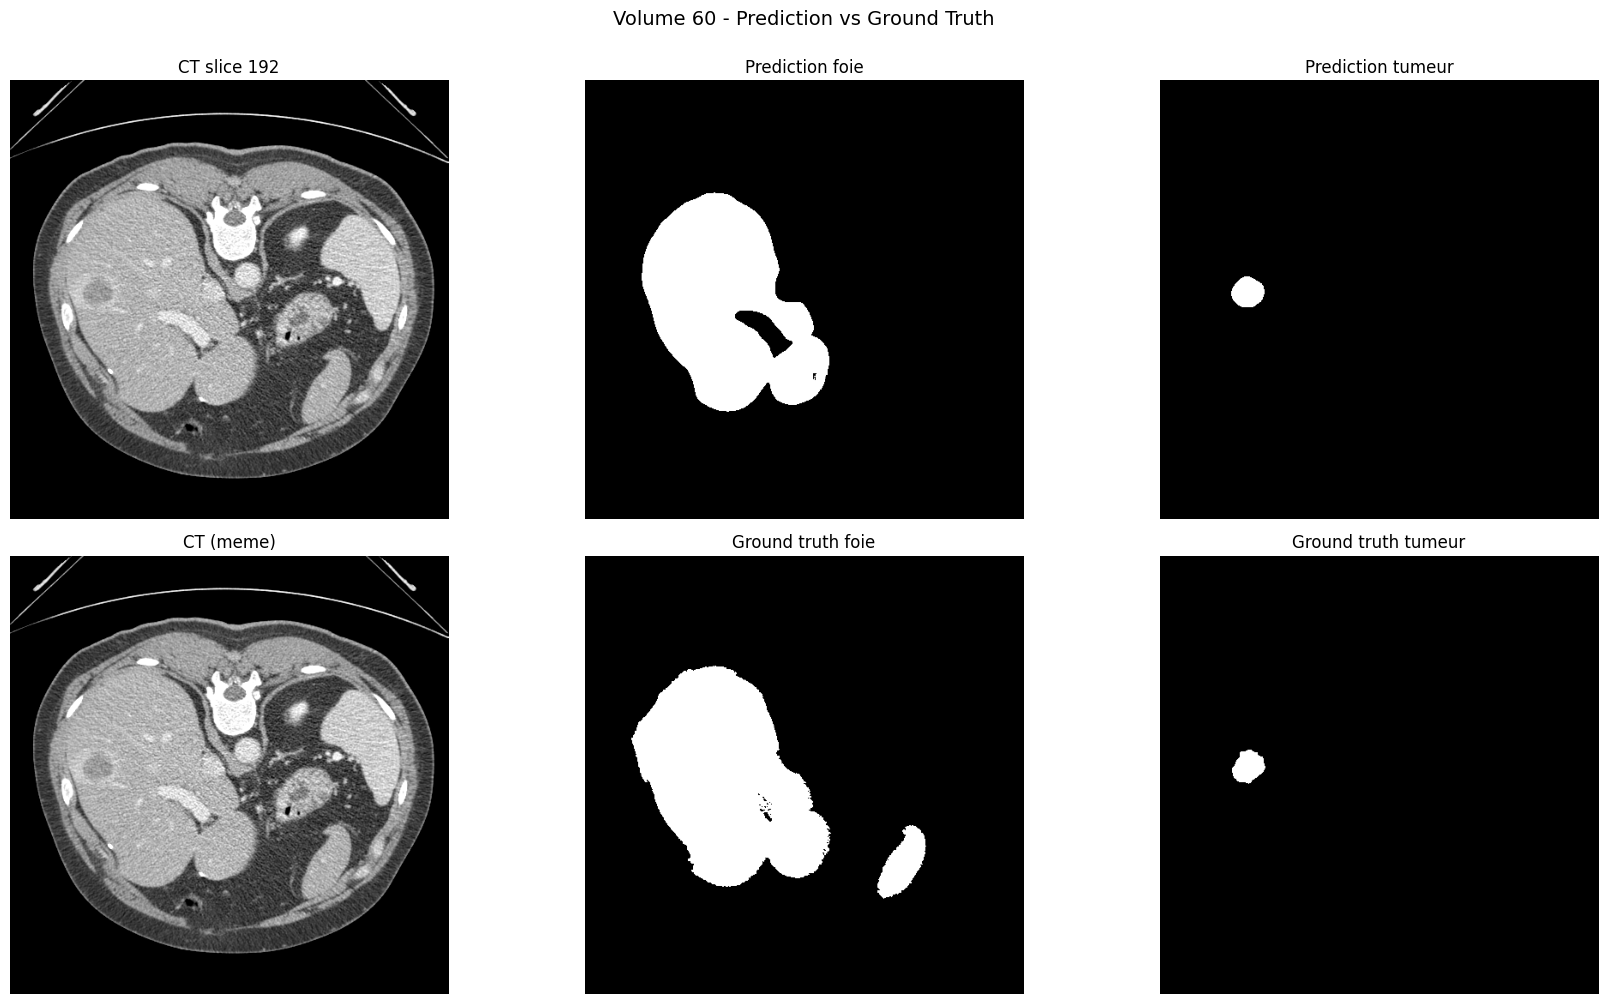

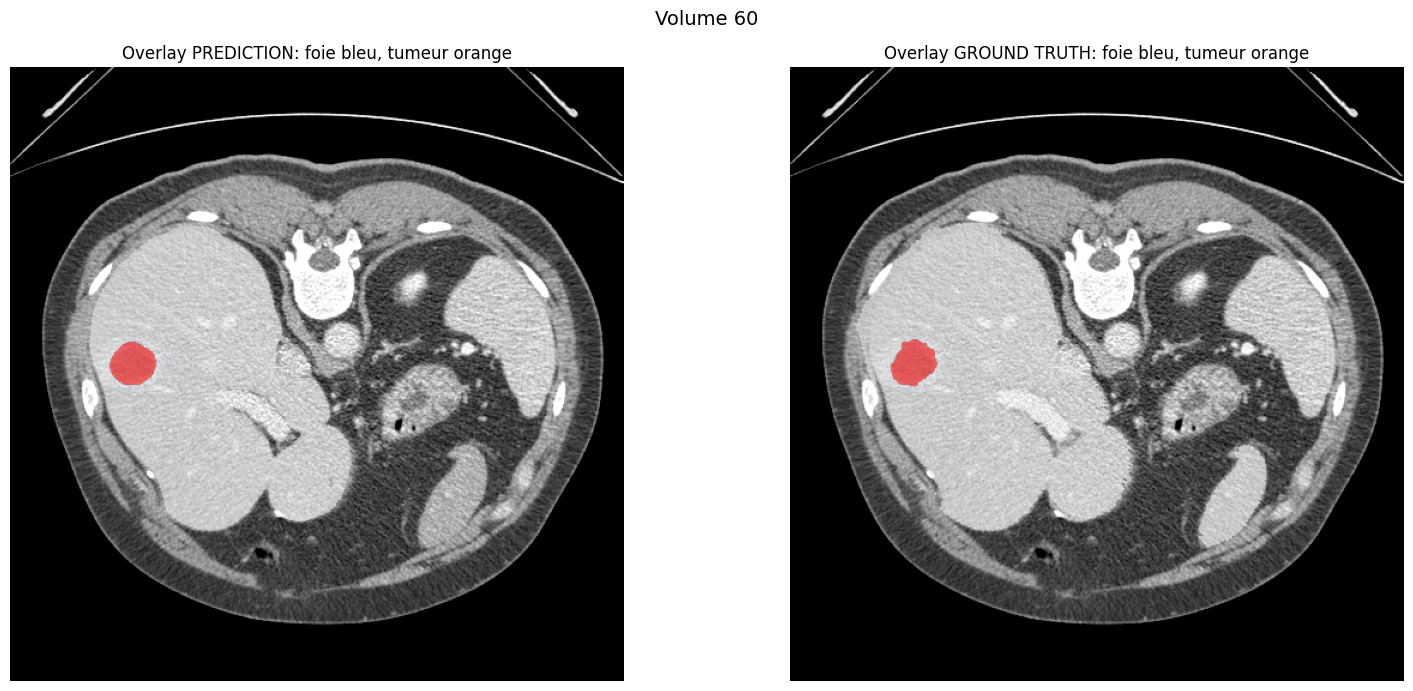

In [55]:
# ========== VISUALISATION DES MASQUES PREDITS POUR LE MEILLEUR VOLUME ==========

if "pred_liver_vol" not in globals() or "pred_tumor_vol" not in globals():
    raise RuntimeError("Execute d'abord la cellule d'inference sur le meilleur volume.")

if "sample_volume_path" not in globals():
    raise RuntimeError("La variable sample_volume_path est introuvable.")

# Recuperer le volume_id depuis le dataframe en utilisant sample_volume_path
volume_row = df[df['volume_path'] == sample_volume_path]
if volume_row.empty:
    best_volume_id = "UNKNOWN"
else:
    best_volume_id = int(volume_row.iloc[0]['volume_id'])

volume_nii = nib.load(sample_volume_path)
volume_data = volume_nii.get_fdata()
seg_data = nib.load(sample_seg_path).get_fdata()
H, W, D = volume_data.shape

# Preprocessing identique pour afficher CT
window_min, window_max = -200, 200
volume_clipped = np.clip(volume_data, window_min, window_max)
volume_normalized = (volume_clipped - window_min) / (window_max - window_min)
volume_normalized = volume_normalized.astype(np.float32)

# Trouver la meilleure slice (celle avec le plus de pixels tumeur predits)
tumor_counts = np.array([np.count_nonzero(pred_tumor_vol[:, :, zi]) for zi in range(D)])
best_z = int(np.argmax(tumor_counts)) if tumor_counts.max() > 0 else D // 2

# Extraire les slices
ct_slice = volume_normalized[:, :, best_z]
liver_pred_slice = pred_liver_vol[:, :, best_z]
tumor_pred_slice = pred_tumor_vol[:, :, best_z]
seg_slice = seg_data[:, :, best_z]
liver_gt_slice = extract_liver_mask(seg_slice).astype(np.uint8)
tumor_gt_slice = extract_tumor_mask(seg_slice).astype(np.uint8)

print(f"\nVolume: {best_volume_id}")
print(f"Slice visualisee: {best_z} (celle avec le plus de tumeur predite)")
print(f"Pixels foie predicts: {int(liver_pred_slice.sum())}")
print(f"Pixels tumeur predicts: {int(tumor_pred_slice.sum())}")
print(f"Pixels foie GT: {int(liver_gt_slice.sum())}")
print(f"Pixels tumeur GT: {int(tumor_gt_slice.sum())}")

# Figure : comparaison prediction vs ground truth
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Ligne 1 : CT + prediction foie + prediction tumeur
axes[0, 0].imshow(ct_slice.T, cmap='gray', origin='lower')
axes[0, 0].set_title(f'CT slice {best_z}')
axes[0, 0].axis('off')

axes[0, 1].imshow(liver_pred_slice.T, cmap='gray', origin='lower', vmin=0, vmax=1)
axes[0, 1].set_title('Prediction foie')
axes[0, 1].axis('off')

axes[0, 2].imshow(tumor_pred_slice.T, cmap='gray', origin='lower', vmin=0, vmax=1)
axes[0, 2].set_title('Prediction tumeur')
axes[0, 2].axis('off')

# Ligne 2 : CT + GT foie + GT tumeur
axes[1, 0].imshow(ct_slice.T, cmap='gray', origin='lower')
axes[1, 0].set_title('CT (meme)')
axes[1, 0].axis('off')

axes[1, 1].imshow(liver_gt_slice.T, cmap='gray', origin='lower', vmin=0, vmax=1)
axes[1, 1].set_title('Ground truth foie')
axes[1, 1].axis('off')

axes[1, 2].imshow(tumor_gt_slice.T, cmap='gray', origin='lower', vmin=0, vmax=1)
axes[1, 2].set_title('Ground truth tumeur')
axes[1, 2].axis('off')

plt.suptitle(f'Volume {best_volume_id} - Prediction vs Ground Truth', fontsize=14, y=1.00)
plt.tight_layout()
plt.show()

# Figure : overlays
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Overlay prediction
axes[0].imshow(ct_slice.T, cmap='gray', origin='lower')
axes[0].imshow(np.ma.masked_where(liver_pred_slice.T == 0, liver_pred_slice.T), cmap='Blues', alpha=0.35, origin='lower')
axes[0].imshow(np.ma.masked_where(tumor_pred_slice.T == 0, tumor_pred_slice.T), cmap='autumn', alpha=0.55, origin='lower')
axes[0].set_title('Overlay PREDICTION: foie bleu, tumeur orange')
axes[0].axis('off')

# Overlay GT
axes[1].imshow(ct_slice.T, cmap='gray', origin='lower')
axes[1].imshow(np.ma.masked_where(liver_gt_slice.T == 0, liver_gt_slice.T), cmap='Blues', alpha=0.35, origin='lower')
axes[1].imshow(np.ma.masked_where(tumor_gt_slice.T == 0, tumor_gt_slice.T), cmap='autumn', alpha=0.55, origin='lower')
axes[1].set_title('Overlay GROUND TRUTH: foie bleu, tumeur orange')
axes[1].axis('off')

plt.suptitle(f'Volume {best_volume_id}', fontsize=14)
plt.tight_layout()
plt.show()

START: 19:59:39
Volume cible: 60
Slice demandee: 192
Chemin volume: /dataset/dataset/volume_pt6/volume-60.nii
Reutilisation des predictions deja disponibles pour le volume 60.
Dimensions volume: 512x512x244
Pixels foie predicts: 35134
Pixels tumeur predicts: 1067
Pixels foie GT: 40520
Pixels tumeur GT: 1074


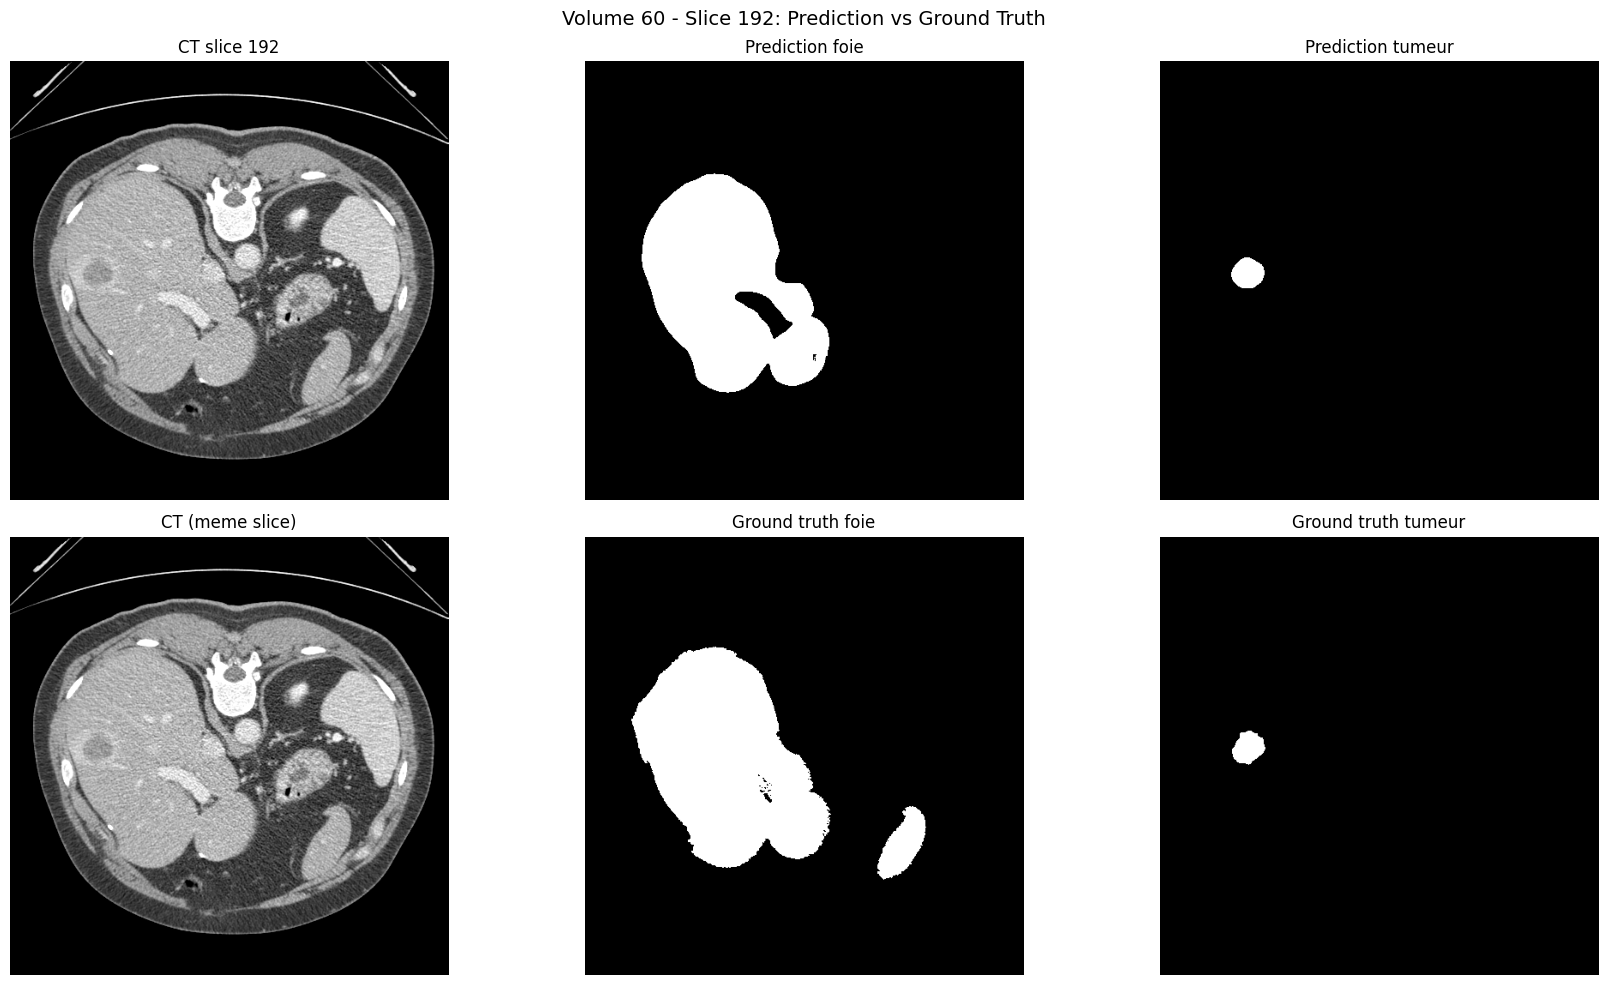

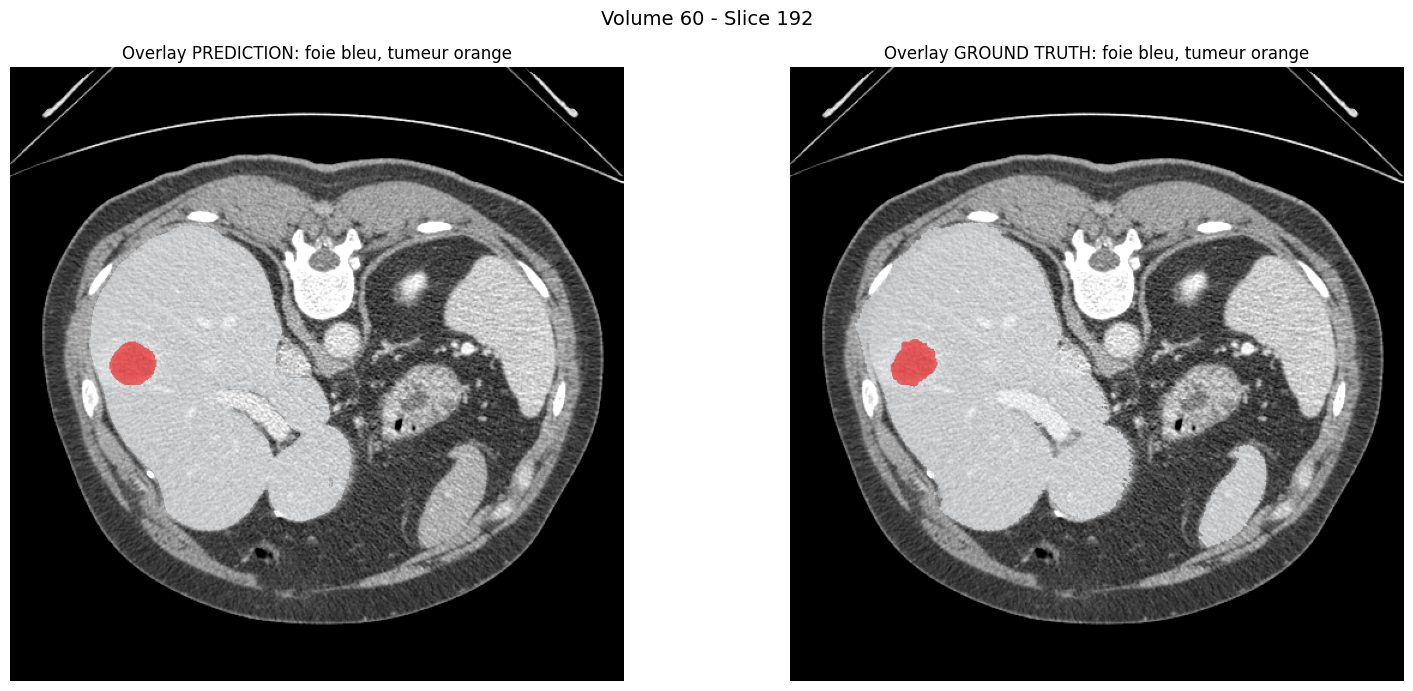

END: 19:59:40


In [56]:
now = datetime.now()
print(now.strftime("START: %H:%M:%S"))

# ========== VISUALISATION CIBLEE: VOLUME 60 / SLICE 192 ==========
target_volume_id = 60
target_slice = 192

if "df" not in globals():
    raise RuntimeError("Le dataframe df est introuvable. Execute les cellules de preparation/evaluation.")

required_symbols = ["predict_on_volume", "model_liver_test", "model_tumor_test", "device", "pipeline"]
for symbol in required_symbols:
    if symbol not in globals():
        raise RuntimeError(f"Symbole manquant: {symbol}. Execute les cellules d'inference/modeles.")

row_match = df[df["volume_id"] == target_volume_id]
if row_match.empty:
    raise RuntimeError(f"volume_id={target_volume_id} introuvable dans df.")

row = row_match.iloc[0]
target_volume_path = row["volume_path"]
target_seg_path = row["segmentation_path"]

print(f"Volume cible: {target_volume_id}")
print(f"Slice demandee: {target_slice}")
print(f"Chemin volume: {target_volume_path}")

# Reutiliser les predictions existantes seulement si elles correspondent deja au volume cible.
can_reuse_preds = (
    "pred_liver_vol" in globals() and
    "pred_tumor_vol" in globals() and
    "sample_volume_path" in globals() and
    sample_volume_path == target_volume_path
)

if not can_reuse_preds:
    print("Predictions absentes ou sur un autre volume -> inference sur volume 60...")
    pred_liver_vol_target, pred_tumor_vol_target = predict_on_volume(
        target_volume_path,
        model_liver_test,
        model_tumor_test,
        device,
        pipeline,
    )
else:
    print("Reutilisation des predictions deja disponibles pour le volume 60.")
    pred_liver_vol_target, pred_tumor_vol_target = pred_liver_vol, pred_tumor_vol

# Lecture slice par slice (evite de charger tout le volume en RAM).
volume_nii = nib.load(target_volume_path)
seg_nii = nib.load(target_seg_path)
H, W, D = volume_nii.shape

if target_slice < 0 or target_slice >= D:
    raise ValueError(f"Slice demandee {target_slice} hors bornes [0, {D-1}].")

ct_slice_raw = np.asarray(volume_nii.dataobj[:, :, target_slice], dtype=np.float32)
seg_slice = np.asarray(seg_nii.dataobj[:, :, target_slice])

window_min, window_max = -200, 200
ct_slice = np.clip(ct_slice_raw, window_min, window_max)
ct_slice = (ct_slice - window_min) / (window_max - window_min)

liver_pred_slice = pred_liver_vol_target[:, :, target_slice]
tumor_pred_slice = pred_tumor_vol_target[:, :, target_slice]
liver_gt_slice = extract_liver_mask(seg_slice).astype(np.uint8)
tumor_gt_slice = extract_tumor_mask(seg_slice).astype(np.uint8)

print(f"Dimensions volume: {H}x{W}x{D}")
print(f"Pixels foie predicts: {int(liver_pred_slice.sum())}")
print(f"Pixels tumeur predicts: {int(tumor_pred_slice.sum())}")
print(f"Pixels foie GT: {int(liver_gt_slice.sum())}")
print(f"Pixels tumeur GT: {int(tumor_gt_slice.sum())}")

# Figure 1: CT + masques prediction/GT
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes[0, 0].imshow(ct_slice.T, cmap="gray", origin="lower")
axes[0, 0].set_title(f"CT slice {target_slice}")
axes[0, 0].axis("off")

axes[0, 1].imshow(liver_pred_slice.T, cmap="gray", origin="lower", vmin=0, vmax=1)
axes[0, 1].set_title("Prediction foie")
axes[0, 1].axis("off")

axes[0, 2].imshow(tumor_pred_slice.T, cmap="gray", origin="lower", vmin=0, vmax=1)
axes[0, 2].set_title("Prediction tumeur")
axes[0, 2].axis("off")

axes[1, 0].imshow(ct_slice.T, cmap="gray", origin="lower")
axes[1, 0].set_title("CT (meme slice)")
axes[1, 0].axis("off")

axes[1, 1].imshow(liver_gt_slice.T, cmap="gray", origin="lower", vmin=0, vmax=1)
axes[1, 1].set_title("Ground truth foie")
axes[1, 1].axis("off")

axes[1, 2].imshow(tumor_gt_slice.T, cmap="gray", origin="lower", vmin=0, vmax=1)
axes[1, 2].set_title("Ground truth tumeur")
axes[1, 2].axis("off")

plt.suptitle(f"Volume {target_volume_id} - Slice {target_slice}: Prediction vs Ground Truth", fontsize=14)
plt.tight_layout()
plt.show()

# Figure 2: overlays
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(ct_slice.T, cmap="gray", origin="lower")
axes[0].imshow(
    np.ma.masked_where(liver_pred_slice.T == 0, liver_pred_slice.T),
    cmap="Blues", alpha=0.35, origin="lower"
 )
axes[0].imshow(
    np.ma.masked_where(tumor_pred_slice.T == 0, tumor_pred_slice.T),
    cmap="autumn", alpha=0.55, origin="lower"
 )
axes[0].set_title("Overlay PREDICTION: foie bleu, tumeur orange")
axes[0].axis("off")

axes[1].imshow(ct_slice.T, cmap="gray", origin="lower")
axes[1].imshow(
    np.ma.masked_where(liver_gt_slice.T == 0, liver_gt_slice.T),
    cmap="Blues", alpha=0.35, origin="lower"
 )
axes[1].imshow(
    np.ma.masked_where(tumor_gt_slice.T == 0, tumor_gt_slice.T),
    cmap="autumn", alpha=0.55, origin="lower"
 )
axes[1].set_title("Overlay GROUND TRUTH: foie bleu, tumeur orange")
axes[1].axis("off")

plt.suptitle(f"Volume {target_volume_id} - Slice {target_slice}", fontsize=14)
plt.tight_layout()
plt.show()

now = datetime.now()
print(now.strftime("END: %H:%M:%S"))

## 10. Visualisation des Résultats 📈

#### Comparaison Prédictions vs Ground Truth

START: 20:23:12
Loading LIVER checkpoints...
  -> 8 epochs found
Loading TUMOR checkpoints...
  -> 20 epochs found

  LIVER — BEST RESULTS
  Best Val Dice        : nan  (epoch 0)
  Best Val Dice (track): 0.8996  (epoch 6)
  Best Train Loss      : nan (epoch 0)
  Final Train Loss     : nan (epoch 7)
  Final Val Dice       : nan  (epoch 7)

  TUMOR — BEST RESULTS
  Best Val Dice        : 0.8740  (epoch 17)
  Best Val Dice (track): 0.8740  (epoch 17)
  Best Train Loss      : 0.00738 (epoch 20)
  Final Train Loss     : 0.00738 (epoch 20)
  Final Val Dice       : 0.8427  (epoch 20)


ValueError: min() iterable argument is empty

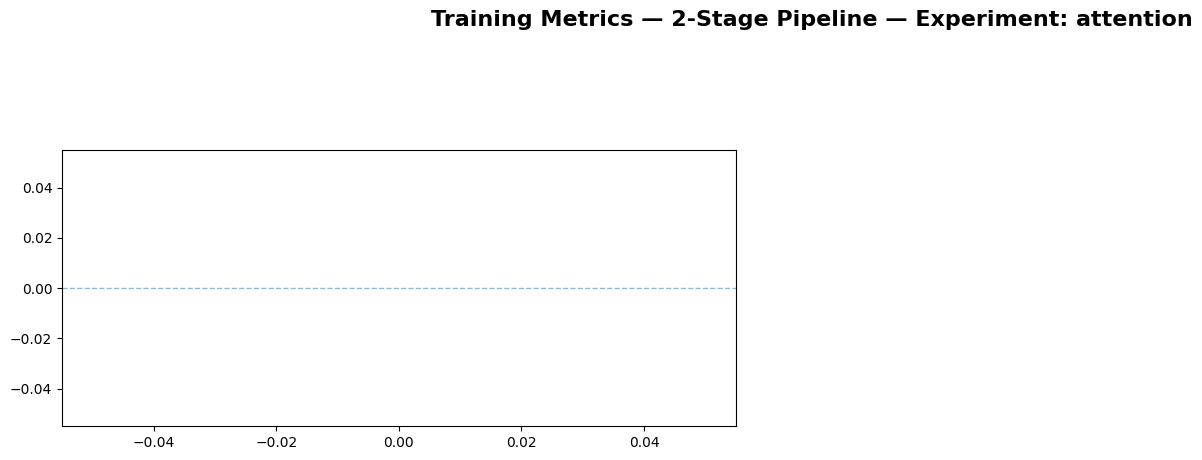

In [63]:
# now = datetime.now()
# print(now.strftime("START: %H:%M:%S"))

# import matplotlib.pyplot as plt
# import matplotlib.gridspec as gridspec
# import matplotlib.patches as mpatches
# import numpy as np
# from pathlib import Path

# # ===== COLORS =====
# COLOR_LIVER  = "#2196F3"
# COLOR_TUMOR  = "#FF5722"
# COLOR_BEST   = "#4CAF50"
# COLOR_MARKER = "#9C27B0"
# COLOR_WARN   = "#FFC107"

# # ===== LOAD CHECKPOINTS =====
# LIVER_CKPT_DIR = Path("/no_finetuning/outputs/checkpoints_liver_attention")
# TUMOR_CKPT_DIR = Path("/no_finetuning/outputs/checkpoints_tumor_attention")

# import re

# def extract_epoch_num(p: Path) -> int:
#     m = re.search(r"(\d+)", p.stem)   # cherche le premier groupe de chiffres
#     return int(m.group(1)) if m else -1

# def load_epoch_checkpoints(ckpt_dir: Path):
#     """Load all epoch_*.pth checkpoints from a directory."""
#     files = list(ckpt_dir.glob("epoch_*.pth")) + list(ckpt_dir.glob("checkpoint_epoch_*.pth"))
#     # Trier par numéro d'époque
#     files = sorted(files, key=extract_epoch_num)
#     data = []
#     for f in files:
#         try:
#             ckpt = torch.load(f, map_location="cpu")
#             data.append({
#                 "epoch":          extract_epoch_num(f),
#                 "avg_train_loss": float(ckpt.get("avg_train_loss", float("nan"))),
#                 "avg_val_dice":   float(ckpt.get("avg_val_dice",   float("nan"))),
#                 "best_val_dice":  float(ckpt.get("best_val_dice",  float("nan"))),
#                 "file":           f.name,
#             })
#         except Exception as e:
#             print(f"  [WARN] Could not load {f.name}: {e}")
#     return data

# print("Loading LIVER checkpoints...")
# liver_data = load_epoch_checkpoints(LIVER_CKPT_DIR)
# print(f"  -> {len(liver_data)} epochs found")

# print("Loading TUMOR checkpoints...")
# tumor_data = load_epoch_checkpoints(TUMOR_CKPT_DIR)
# print(f"  -> {len(tumor_data)} epochs found")

# # ===== EXTRACT SERIES =====
# def extract_series(data, key):
#     epochs = [d["epoch"] for d in data if not np.isnan(d[key])]
#     values = [d[key]     for d in data if not np.isnan(d[key])]
#     return epochs, values

# liver_epochs_loss, liver_train_loss = extract_series(liver_data, "avg_train_loss")
# liver_epochs_dice, liver_val_dice   = extract_series(liver_data, "avg_val_dice")
# liver_epochs_best, liver_best_dice  = extract_series(liver_data, "best_val_dice")

# tumor_epochs_loss, tumor_train_loss = extract_series(tumor_data, "avg_train_loss")
# tumor_epochs_dice, tumor_val_dice   = extract_series(tumor_data, "avg_val_dice")
# tumor_epochs_best, tumor_best_dice  = extract_series(tumor_data, "best_val_dice")

# # ===== BEST VALUES SUMMARY =====
# def best_info(data, stage):
#     if not data:
#         return None, None, None
#     best_dice_row  = max(data, key=lambda d: d.get("avg_val_dice",   float("-inf")))
#     best_loss_row  = min(data, key=lambda d: d.get("avg_train_loss", float("inf")))
#     overall_best   = max(data, key=lambda d: d.get("best_val_dice",  float("-inf")))

#     print(f"\n{'='*55}")
#     print(f"  {stage.upper()} — BEST RESULTS")
#     print(f"{'='*55}")
#     print(f"  Best Val Dice        : {best_dice_row['avg_val_dice']:.4f}  (epoch {best_dice_row['epoch']})")
#     print(f"  Best Val Dice (track): {overall_best['best_val_dice']:.4f}  (epoch {overall_best['epoch']})")
#     print(f"  Best Train Loss      : {best_loss_row['avg_train_loss']:.5f} (epoch {best_loss_row['epoch']})")
#     print(f"  Final Train Loss     : {data[-1]['avg_train_loss']:.5f} (epoch {data[-1]['epoch']})")
#     print(f"  Final Val Dice       : {data[-1]['avg_val_dice']:.4f}  (epoch {data[-1]['epoch']})")
#     return best_dice_row, best_loss_row, overall_best

# liver_best_dice_row, liver_best_loss_row, liver_overall = best_info(liver_data, "LIVER")
# tumor_best_dice_row, tumor_best_loss_row, tumor_overall = best_info(tumor_data, "TUMOR")

# # ===== VIS 1 : MAIN SUMMARY (Loss + Dice per stage) =====
# fig = plt.figure(figsize=(20, 14))
# fig.suptitle(
#     f"Training Metrics — 2-Stage Pipeline — Experiment: {UNET_EXPERIMENT}",
#     fontsize=16, fontweight="bold", y=0.98
# )

# gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.30)

# # -- Liver Loss --
# ax_ll = fig.add_subplot(gs[0, 0])
# ax_ll.plot(liver_epochs_loss, liver_train_loss, "o-", color=COLOR_LIVER, lw=2, ms=5, label="Train Loss")
# ax_ll.axhline(min(liver_train_loss) if liver_train_loss else 0,
#               color=COLOR_LIVER, ls="--", lw=1, alpha=0.6)
# if liver_best_loss_row:
#     ax_ll.annotate(
#         f"min={min(liver_train_loss):.4f}\n(ep {liver_best_loss_row['epoch']})",
#         xy=(liver_best_loss_row["epoch"], liver_best_loss_row["avg_train_loss"]),
#         xytext=(liver_best_loss_row["epoch"] + 0.3, liver_best_loss_row["avg_train_loss"] + 0.001),
#         fontsize=8, color=COLOR_LIVER,
#         arrowprops=dict(arrowstyle="->", color=COLOR_LIVER, lw=1),
#     )
# ax_ll.set_title("LIVER — Train Loss", fontsize=12, pad=8)
# ax_ll.set_xlabel("Epoch")
# ax_ll.set_ylabel("BCE Loss")
# ax_ll.legend(fontsize=9)
# ax_ll.grid(True, alpha=0.3)
# ax_ll.set_xticks(liver_epochs_loss)

# # -- Liver Dice --
# ax_ld = fig.add_subplot(gs[0, 1])
# ax_ld.plot(liver_epochs_dice, liver_val_dice,  "s-",  color=COLOR_TUMOR, lw=2,   ms=5, label="Val Dice")
# ax_ld.plot(liver_epochs_best, liver_best_dice, "^--", color=COLOR_BEST,  lw=1.5, ms=5, label="Best Val Dice (cumulative)")
# if liver_best_dice_row:
#     ax_ld.scatter(
#         [liver_best_dice_row["epoch"]], [liver_best_dice_row["avg_val_dice"]],
#         color=COLOR_MARKER, zorder=5, s=100,
#         label=f"Best={liver_best_dice_row['avg_val_dice']:.4f}"
#     )
# ax_ld.set_title("LIVER — Val Dice", fontsize=12, pad=8)
# ax_ld.set_xlabel("Epoch")
# ax_ld.set_ylabel("Dice Score")
# ax_ld.set_ylim(0, 1.05)
# ax_ld.legend(fontsize=9)
# ax_ld.grid(True, alpha=0.3)
# ax_ld.set_xticks(liver_epochs_dice)

# # -- Tumor Loss --
# ax_tl = fig.add_subplot(gs[1, 0])
# ax_tl.plot(tumor_epochs_loss, tumor_train_loss, "o-", color=COLOR_LIVER, lw=2, ms=4, label="Train Loss")
# ax_tl.axhline(min(tumor_train_loss) if tumor_train_loss else 0,
#               color=COLOR_LIVER, ls="--", lw=1, alpha=0.6)
# if tumor_best_loss_row:
#     ax_tl.annotate(
#         f"min={min(tumor_train_loss):.4f}\n(ep {tumor_best_loss_row['epoch']})",
#         xy=(tumor_best_loss_row["epoch"], tumor_best_loss_row["avg_train_loss"]),
#         xytext=(tumor_best_loss_row["epoch"] + 1, tumor_best_loss_row["avg_train_loss"] + 0.001),
#         fontsize=8, color=COLOR_LIVER,
#         arrowprops=dict(arrowstyle="->", color=COLOR_LIVER, lw=1),
#     )
# ax_tl.set_title("TUMOR — Train Loss", fontsize=12, pad=8)
# ax_tl.set_xlabel("Epoch")
# ax_tl.set_ylabel("BCE Loss (weighted)")
# ax_tl.legend(fontsize=9)
# ax_tl.grid(True, alpha=0.3)

# # -- Tumor Dice --
# ax_td = fig.add_subplot(gs[1, 1])
# ax_td.plot(tumor_epochs_dice, tumor_val_dice,  "s-",  color=COLOR_TUMOR, lw=2,   ms=4, label="Val Dice")
# ax_td.plot(tumor_epochs_best, tumor_best_dice, "^--", color=COLOR_BEST,  lw=1.5, ms=4, label="Best Val Dice (cumulative)")
# if tumor_best_dice_row:
#     ax_td.scatter(
#         [tumor_best_dice_row["epoch"]], [tumor_best_dice_row["avg_val_dice"]],
#         color=COLOR_MARKER, zorder=5, s=100,
#         label=f"Best={tumor_best_dice_row['avg_val_dice']:.4f}"
#     )
# ax_td.set_title("TUMOR — Val Dice", fontsize=12, pad=8)
# ax_td.set_xlabel("Epoch")
# ax_td.set_ylabel("Dice Score")
# ax_td.set_ylim(0, 1.05)
# ax_td.legend(fontsize=9)
# ax_td.grid(True, alpha=0.3)

# # -- Summary Table --
# ax_tab = fig.add_subplot(gs[2, :])
# ax_tab.axis("off")

# col_labels = [
#     "Stage", "Epochs",
#     "Best Val Dice", "Epoch (Best)",
#     "Final Val Dice",
#     "Best Train Loss", "Epoch (Best Loss)"
# ]
# rows = []

# if liver_data and liver_best_dice_row and liver_best_loss_row:
#     rows.append([
#         "LIVER",
#         str(len(liver_data)),
#         f"{liver_best_dice_row['avg_val_dice']:.4f}",
#         str(liver_best_dice_row['epoch']),
#         f"{liver_data[-1]['avg_val_dice']:.4f}",
#         f"{liver_best_loss_row['avg_train_loss']:.5f}",
#         str(liver_best_loss_row['epoch']),
#     ])

# if tumor_data and tumor_best_dice_row and tumor_best_loss_row:
#     rows.append([
#         "TUMOR",
#         str(len(tumor_data)),
#         f"{tumor_best_dice_row['avg_val_dice']:.4f}",
#         str(tumor_best_dice_row['epoch']),
#         f"{tumor_data[-1]['avg_val_dice']:.4f}",
#         f"{tumor_best_loss_row['avg_train_loss']:.5f}",
#         str(tumor_best_loss_row['epoch']),
#     ])

# if rows:
#     table = ax_tab.table(
#         cellText=rows,
#         colLabels=col_labels,
#         loc="center",
#         cellLoc="center",
#     )
#     table.auto_set_font_size(False)
#     table.set_fontsize(11)
#     table.scale(1.0, 2.2)

#     for j in range(len(col_labels)):
#         table[0, j].set_facecolor("#263238")
#         table[0, j].set_text_props(color="white", fontweight="bold")

#     row_colors = ["#E3F2FD", "#FCE4EC"]
#     for i in range(len(rows)):
#         for j in range(len(col_labels)):
#             table[i+1, j].set_facecolor(row_colors[i % 2])

#     ax_tab.set_title("Summary Table", fontsize=12, pad=12)

# plt.savefig("outputs/vis_training_summary.png", dpi=130, bbox_inches="tight")
# plt.show()
# print("Saved: outputs/vis_training_summary.png")


# # ===== VIS 2 : LIVER vs TUMOR COMPARISON =====
# fig, axes = plt.subplots(1, 2, figsize=(18, 6))
# fig.suptitle("Liver vs Tumor — Side-by-Side Comparison", fontsize=14, fontweight="bold")

# ax = axes[0]
# if liver_train_loss:
#     ax.plot(liver_epochs_loss, liver_train_loss, "o-", color=COLOR_LIVER, lw=2, ms=5, label="LIVER — Train Loss")
# if tumor_train_loss:
#     ax.plot(tumor_epochs_loss, tumor_train_loss, "s-", color=COLOR_TUMOR, lw=2, ms=5, label="TUMOR — Train Loss")
# ax.set_title("Train Loss — Liver vs Tumor", fontsize=12)
# ax.set_xlabel("Epoch")
# ax.set_ylabel("Loss")
# ax.legend(fontsize=10)
# ax.grid(True, alpha=0.3)

# ax = axes[1]
# if liver_val_dice:
#     ax.plot(liver_epochs_dice, liver_val_dice, "o-", color=COLOR_LIVER, lw=2, ms=5, label="LIVER — Val Dice")
# if tumor_val_dice:
#     ax.plot(tumor_epochs_dice, tumor_val_dice, "s-", color=COLOR_TUMOR, lw=2, ms=5, label="TUMOR — Val Dice")
# ax.axhline(0.9, color="gray", ls="--", lw=1, alpha=0.5, label="Threshold 0.90")
# ax.axhline(0.8, color="gray", ls=":",  lw=1, alpha=0.5, label="Threshold 0.80")
# ax.set_title("Val Dice — Liver vs Tumor", fontsize=12)
# ax.set_xlabel("Epoch")
# ax.set_ylabel("Dice Score")
# ax.set_ylim(0, 1.05)
# ax.legend(fontsize=10)
# ax.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.savefig("outputs/vis_comparison_liver_tumor.png", dpi=120, bbox_inches="tight")
# plt.show()
# print("Saved: outputs/vis_comparison_liver_tumor.png")


# # ===== VIS 3 : EPOCH-BY-EPOCH IMPROVEMENT (Delta Dice) =====
# fig, axes = plt.subplots(1, 2, figsize=(18, 5))
# fig.suptitle("Epoch-by-Epoch Val Dice Improvement", fontsize=14, fontweight="bold")

# def compute_deltas(values):
#     return [values[i] - values[i-1] for i in range(1, len(values))]

# def compute_epochs_for_deltas(epochs):
#     return epochs[1:]

# for ax, epochs, values, label, color in [
#     (axes[0], liver_epochs_dice, liver_val_dice, "LIVER",  COLOR_LIVER),
#     (axes[1], tumor_epochs_dice, tumor_val_dice, "TUMOR",  COLOR_TUMOR),
# ]:
#     if len(values) < 2:
#         ax.text(0.5, 0.5, "Not enough data", ha="center", va="center", transform=ax.transAxes)
#         continue

#     deltas     = compute_deltas(values)
#     ep_d       = compute_epochs_for_deltas(epochs)
#     colors_bar = [COLOR_BEST if d >= 0 else "#F44336" for d in deltas]

#     bars = ax.bar(ep_d, deltas, color=colors_bar, edgecolor="white", linewidth=0.5)
#     ax.axhline(0, color="black", lw=1)

#     for bar, delta in zip(bars, deltas):
#         ax.text(
#             bar.get_x() + bar.get_width() / 2,
#             bar.get_height() + (0.001 if delta >= 0 else -0.003),
#             f"{delta:+.3f}",
#             ha="center",
#             va="bottom" if delta >= 0 else "top",
#             fontsize=8,
#             color="black"
#         )

#     ax.set_title(f"{label} — Δ Val Dice per Epoch", fontsize=12)
#     ax.set_xlabel("Epoch")
#     ax.set_ylabel("ΔDice")
#     ax.grid(True, alpha=0.3, axis="y")

#     pos_patch = mpatches.Patch(color=COLOR_BEST, label="Improvement")
#     neg_patch = mpatches.Patch(color="#F44336",  label="Regression")
#     ax.legend(handles=[pos_patch, neg_patch], fontsize=9)

# plt.tight_layout()
# plt.savefig("outputs/vis_delta_dice.png", dpi=120, bbox_inches="tight")
# plt.show()
# print("Saved: outputs/vis_delta_dice.png")


# # ===== VIS 4 : METRICS HEATMAP =====
# fig, axes = plt.subplots(1, 2, figsize=(18, 4))
# fig.suptitle("Metrics Heatmap per Epoch", fontsize=14, fontweight="bold")

# def make_heatmap(ax, data, title, color_map):
#     if not data:
#         return
#     epochs_list = [d["epoch"]          for d in data]
#     losses      = [d["avg_train_loss"] for d in data]
#     dices       = [d["avg_val_dice"]   for d in data]

#     matrix = np.array([losses, dices])
#     im = ax.imshow(matrix, aspect="auto", cmap=color_map, interpolation="nearest")

#     ax.set_yticks([0, 1])
#     ax.set_yticklabels(["Train Loss", "Val Dice"], fontsize=11)
#     ax.set_xticks(range(len(epochs_list)))
#     ax.set_xticklabels([str(e) for e in epochs_list], fontsize=9)
#     ax.set_xlabel("Epoch")
#     ax.set_title(title, fontsize=12)
#     plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

#     for i in range(matrix.shape[0]):
#         for j in range(matrix.shape[1]):
#             ax.text(
#                 j, i, f"{matrix[i, j]:.3f}",
#                 ha="center", va="center", fontsize=7.5,
#                 color="white" if matrix[i, j] < matrix[i].mean() else "black"
#             )

# make_heatmap(axes[0], liver_data, "LIVER — Metrics Heatmap", "Blues")
# make_heatmap(axes[1], tumor_data, "TUMOR — Metrics Heatmap", "Reds")

# plt.tight_layout()
# plt.savefig("outputs/vis_heatmap_metrics.png", dpi=120, bbox_inches="tight")
# plt.show()
# print("Saved: outputs/vis_heatmap_metrics.png")


# # ===== VIS 5 : CONVERGENCE SCATTER (Loss vs Dice) =====
# fig, axes = plt.subplots(1, 2, figsize=(14, 6))
# fig.suptitle("Convergence Path: Train Loss vs Val Dice", fontsize=14, fontweight="bold")

# for ax, data, label, color in [
#     (axes[0], liver_data, "LIVER",  COLOR_LIVER),
#     (axes[1], tumor_data, "TUMOR",  COLOR_TUMOR),
# ]:
#     if not data:
#         continue

#     losses = [d["avg_train_loss"] for d in data]
#     dices  = [d["avg_val_dice"]   for d in data]
#     epochs = [d["epoch"]          for d in data]

#     # Scatter colored by epoch number
#     sc = ax.scatter(losses, dices, c=epochs, cmap="viridis",
#                     s=80, zorder=3, edgecolors="white", lw=0.5)
#     ax.plot(losses, dices, "--", color=color, alpha=0.4, lw=1.5, zorder=2)

#     # Annotate first and last epoch
#     ax.annotate(f"ep {epochs[0]}",  (losses[0],  dices[0]),
#                 textcoords="offset points", xytext=(6,  4),  fontsize=8)
#     ax.annotate(f"ep {epochs[-1]}", (losses[-1], dices[-1]),
#                 textcoords="offset points", xytext=(6, -10), fontsize=8)

#     plt.colorbar(sc, ax=ax, label="Epoch")
#     ax.set_title(f"{label} — Loss vs Dice", fontsize=12)
#     ax.set_xlabel("Train Loss")
#     ax.set_ylabel("Val Dice")
#     ax.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.savefig("outputs/vis_convergence_scatter.png", dpi=120, bbox_inches="tight")
# plt.show()
# print("Saved: outputs/vis_convergence_scatter.png")


# # ===== VIS 6 : CUMULATIVE BEST DICE PROGRESSION =====
# fig, ax = plt.subplots(figsize=(14, 6))
# fig.suptitle("Cumulative Best Val Dice Progression", fontsize=14, fontweight="bold")

# if liver_epochs_best and liver_best_dice:
#     ax.step(liver_epochs_best, liver_best_dice, where="post",
#             color=COLOR_LIVER, lw=2.5, label="LIVER — Cumulative Best Dice")
#     ax.fill_between(liver_epochs_best, liver_best_dice,
#                     step="post", alpha=0.15, color=COLOR_LIVER)
#     ax.scatter([liver_epochs_best[-1]], [liver_best_dice[-1]],
#                color=COLOR_LIVER, s=120, zorder=5)
#     ax.annotate(
#         f"{liver_best_dice[-1]:.4f}",
#         (liver_epochs_best[-1], liver_best_dice[-1]),
#         textcoords="offset points", xytext=(5, 5),
#         fontsize=10, color=COLOR_LIVER, fontweight="bold"
#     )

# if tumor_epochs_best and tumor_best_dice:
#     ax.step(tumor_epochs_best, tumor_best_dice, where="post",
#             color=COLOR_TUMOR, lw=2.5, label="TUMOR — Cumulative Best Dice")
#     ax.fill_between(tumor_epochs_best, tumor_best_dice,
#                     step="post", alpha=0.15, color=COLOR_TUMOR)
#     ax.scatter([tumor_epochs_best[-1]], [tumor_best_dice[-1]],
#                color=COLOR_TUMOR, s=120, zorder=5)
#     ax.annotate(
#         f"{tumor_best_dice[-1]:.4f}",
#         (tumor_epochs_best[-1], tumor_best_dice[-1]),
#         textcoords="offset points", xytext=(5, -14),
#         fontsize=10, color=COLOR_TUMOR, fontweight="bold"
#     )

# ax.axhline(0.9, color="gray", ls="--", lw=1, alpha=0.5, label="Threshold 0.90")
# ax.axhline(0.8, color="gray", ls=":",  lw=1, alpha=0.4, label="Threshold 0.80")
# ax.set_xlabel("Epoch", fontsize=12)
# ax.set_ylabel("Best Val Dice", fontsize=12)
# ax.set_ylim(0, 1.05)
# ax.legend(fontsize=10)
# ax.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.savefig("outputs/vis_best_dice_progression.png", dpi=120, bbox_inches="tight")
# plt.show()
# print("Saved: outputs/vis_best_dice_progression.png")


# # ===== VIS 7 : RADAR CHART =====
# def radar_chart(ax, categories, values_liver, values_tumor, title):
#     N      = len(categories)
#     angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
#     angles += angles[:1]

#     values_liver = values_liver + values_liver[:1]
#     values_tumor = values_tumor + values_tumor[:1]

#     ax.set_theta_offset(np.pi / 2)
#     ax.set_theta_direction(-1)
#     ax.set_thetagrids(np.degrees(angles[:-1]), categories, fontsize=10)

#     ax.plot(angles, values_liver, "o-", lw=2, color=COLOR_LIVER, label="LIVER")
#     ax.fill(angles, values_liver, alpha=0.15, color=COLOR_LIVER)

#     ax.plot(angles, values_tumor, "s-", lw=2, color=COLOR_TUMOR, label="TUMOR")
#     ax.fill(angles, values_tumor, alpha=0.15, color=COLOR_TUMOR)

#     ax.set_ylim(0, 1)
#     ax.set_title(title, fontsize=12, pad=15)
#     ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=9)


# def normalize_loss(loss_list, worst=0.10):
#     """Convert loss to a [0,1] score — lower loss => higher score."""
#     if not loss_list:
#         return 0.0
#     best = min(loss_list)
#     return max(0.0, min(1.0, 1.0 - best / worst))


# # Build radar values for each stage
# liver_radar = [
#     max(liver_val_dice)  if liver_val_dice  else 0.0,
#     liver_val_dice[-1]   if liver_val_dice  else 0.0,
#     normalize_loss(liver_train_loss),
#     max(liver_best_dice) if liver_best_dice else 0.0,
#     (1.0 - abs(liver_val_dice[-1] - max(liver_val_dice))) if liver_val_dice else 0.0,
# ]

# tumor_radar = [
#     max(tumor_val_dice)  if tumor_val_dice  else 0.0,
#     tumor_val_dice[-1]   if tumor_val_dice  else 0.0,
#     normalize_loss(tumor_train_loss),
#     max(tumor_best_dice) if tumor_best_dice else 0.0,
#     (1.0 - abs(tumor_val_dice[-1] - max(tumor_val_dice))) if tumor_val_dice else 0.0,
# ]

# categories = [
#     "Best\nVal Dice",
#     "Final\nVal Dice",
#     "Train Loss\n(inverted)",
#     "Best\nDice (cumul)",
#     "Final\nStability"
# ]

# fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
# fig.suptitle("Radar Chart: Global Profile — Liver vs Tumor",
#              fontsize=14, fontweight="bold")
# radar_chart(ax, categories, liver_radar, tumor_radar, "")
# plt.tight_layout()
# plt.savefig("outputs/vis_radar_profile.png", dpi=120, bbox_inches="tight")
# plt.show()
# print("Saved: outputs/vis_radar_profile.png")


# # ===== VIS 8 : EPOCH-BY-EPOCH DETAILED TABLE =====
# print("\n" + "="*65)
# print("EPOCH-BY-EPOCH DETAIL — LIVER")
# print(f"{'Epoch':>6} | {'Train Loss':>12} | {'Val Dice':>10} | {'Best Dice':>10}")
# print("-"*50)
# for d in liver_data:
#     marker = " <-- BEST" if liver_best_dice_row and d["epoch"] == liver_best_dice_row["epoch"] else ""
#     print(f"{d['epoch']:>6} | {d['avg_train_loss']:>12.5f} | {d['avg_val_dice']:>10.4f} | {d['best_val_dice']:>10.4f}{marker}")

# print("\n" + "="*65)
# print("EPOCH-BY-EPOCH DETAIL — TUMOR")
# print(f"{'Epoch':>6} | {'Train Loss':>12} | {'Val Dice':>10} | {'Best Dice':>10}")
# print("-"*50)
# for d in tumor_data:
#     marker = " <-- BEST" if tumor_best_dice_row and d["epoch"] == tumor_best_dice_row["epoch"] else ""
#     print(f"{d['epoch']:>6} | {d['avg_train_loss']:>12.5f} | {d['avg_val_dice']:>10.4f} | {d['best_val_dice']:>10.4f}{marker}")


# # ===== FINAL REPORT =====
# print("\n" + "█"*65)
# print("█" + " "*22 + "FINAL REPORT" + " "*29 + "█")
# print("█"*65)

# for stage, data, best_dice_row, best_loss_row, val_dice_list, train_loss_list in [
#     ("LIVER", liver_data, liver_best_dice_row, liver_best_loss_row, liver_val_dice, liver_train_loss),
#     ("TUMOR", tumor_data, tumor_best_dice_row, tumor_best_loss_row, tumor_val_dice, tumor_train_loss),
# ]:
#     if not data:
#         continue

#     print(f"\n{'─'*55}")
#     print(f"  {stage}")
#     print(f"{'─'*55}")
#     print(f"  Epochs trained             : {len(data)}")
#     print(f"  Best Val Dice              : {max(val_dice_list):.4f}  (epoch {best_dice_row['epoch']})")
#     print(f"  Final Val Dice             : {val_dice_list[-1]:.4f}")
#     print(f"  Best → Final gap           : {val_dice_list[-1] - max(val_dice_list):+.4f}")
#     print(f"  Best Train Loss            : {min(train_loss_list):.5f} (epoch {best_loss_row['epoch']})")
#     print(f"  Final Train Loss           : {train_loss_list[-1]:.5f}")

#     n_improve = sum(1 for i in range(1, len(val_dice_list)) if val_dice_list[i] > val_dice_list[i-1])
#     n_regress = sum(1 for i in range(1, len(val_dice_list)) if val_dice_list[i] < val_dice_list[i-1])
#     print(f"  Epochs with improvement    : {n_improve}/{len(val_dice_list)-1}")
#     print(f"  Epochs with regression     : {n_regress}/{len(val_dice_list)-1}")

#     # Convergence check on last 3 epochs
#     last3    = val_dice_list[-3:] if len(val_dice_list) >= 3 else val_dice_list
#     variance = np.var(last3)
#     if variance < 0.001:
#         status = "Stable"
#     elif variance < 0.005:
#         status = "Variable"
#     else:
#         status = "Not converged"
#     print(f"  Convergence (last 3 ep)    : {status}  (var={variance:.5f})")

# # Saved files summary
# print(f"\n{'─'*55}")
# print("  Saved figures in outputs/")
# saved_files = [
#     "vis_training_summary.png",
#     "vis_comparison_liver_tumor.png",
#     "vis_delta_dice.png",
#     "vis_heatmap_metrics.png",
#     "vis_convergence_scatter.png",
#     "vis_best_dice_progression.png",
#     "vis_radar_profile.png",
# ]
# for f in saved_files:
#     exists = "OK" if Path(f"outputs/{f}").exists() else "MISSING"
#     print(f"  [{exists}] {f}")

# now = datetime.now()
# print(now.strftime("\nEND: %H:%M:%S"))

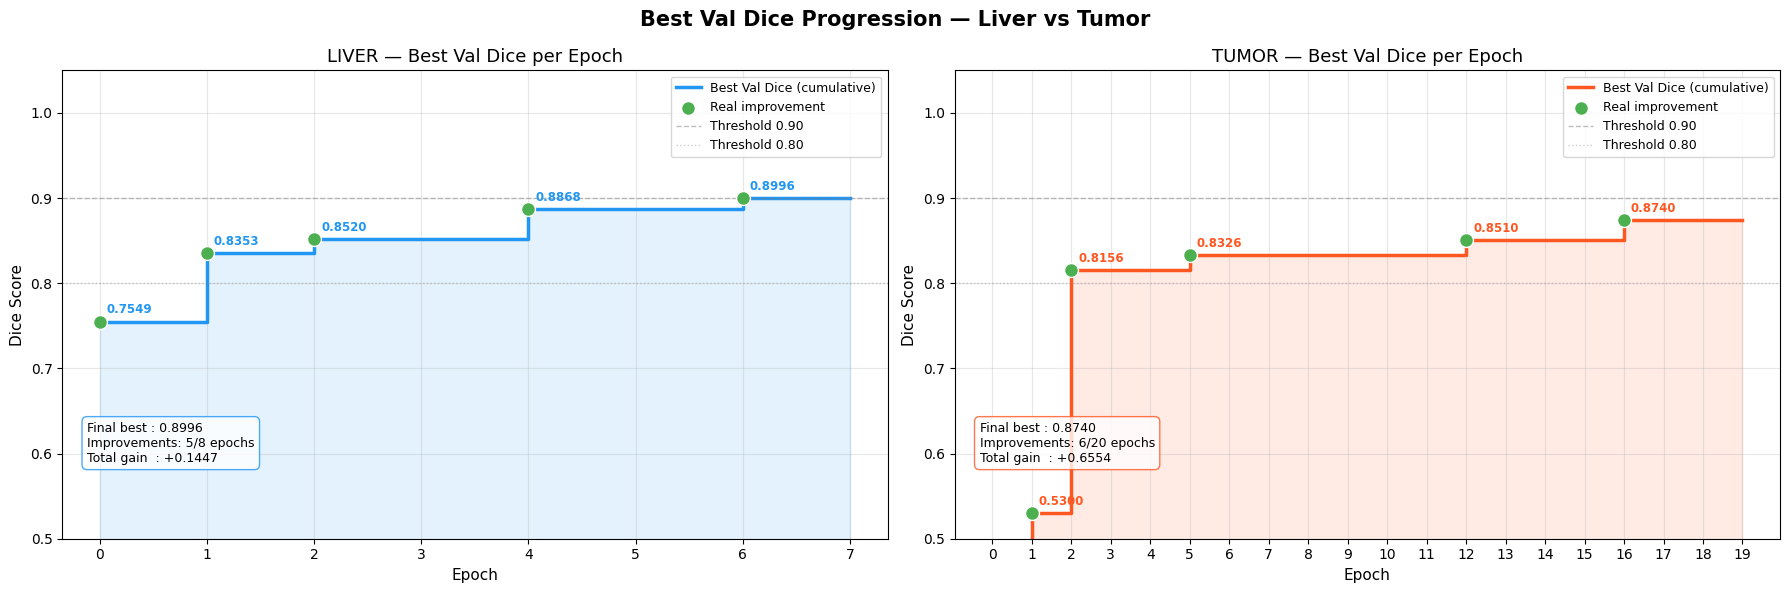

Saved: outputs/vis_best_dice_clean.png


In [70]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from pathlib import Path
import re

# ===== CONFIG =====
COLOR_LIVER = "#2196F3"
COLOR_TUMOR = "#FF5722"
COLOR_IMPROVEMENT = "#4CAF50"

def extract_epoch_num(p: Path) -> int:
    m = re.search(r"(\d+)", p.stem)
    return int(m.group(1)) if m else -1

def load_best_dice(ckpt_dir: Path):
    # Cherche les deux patterns
    files = list(ckpt_dir.glob("checkpoint_epoch_*.pth")) + list(ckpt_dir.glob("epoch_*.pth"))
    files = sorted(files, key=extract_epoch_num)
    epochs, best_dices = [], []
    for f in files:
        try:
            ckpt = torch.load(f, map_location="cpu")
            ep = ckpt.get("epoch", extract_epoch_num(f))
            bd = ckpt.get("best_val_dice", None)
            if bd is not None:
                epochs.append(ep)
                best_dices.append(float(bd))
        except Exception as e:
            print(f"[WARN] {f.name}: {e}")
    return epochs, best_dices
# ===== LOAD =====
LIVER_CKPT_DIR = Path("/no_finetuning/outputs/checkpoints_liver_attention")
TUMOR_CKPT_DIR = Path("/no_finetuning/outputs/checkpoints_tumor_attention")

liver_epochs, liver_best = load_best_dice(LIVER_CKPT_DIR)
tumor_epochs, tumor_best = load_best_dice(TUMOR_CKPT_DIR)

# ===== DETECT IMPROVEMENTS =====
def get_improvements(epochs, values):
    imp_ep, imp_val = [], []
    prev = -1
    for ep, val in zip(epochs, values):
        if val > prev:
            imp_ep.append(ep)
            imp_val.append(val)
            prev = val
    return imp_ep, imp_val

liver_imp_ep, liver_imp_val = get_improvements(liver_epochs, liver_best)
tumor_imp_ep, tumor_imp_val = get_improvements(tumor_epochs, tumor_best)

# ===== PLOT =====
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle("Best Val Dice Progression — Liver vs Tumor", fontsize=15, fontweight="bold")

for ax, epochs, values, imp_ep, imp_val, color, label in [
    (axes[0], liver_epochs, liver_best, liver_imp_ep, liver_imp_val, COLOR_LIVER, "LIVER"),
    (axes[1], tumor_epochs, tumor_best, tumor_imp_ep, tumor_imp_val, COLOR_TUMOR, "TUMOR"),
]:
    if not values:
        ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes)
        continue

    # Courbe cumulative
    ax.step(epochs, values, where="post", color=color, lw=2.5, label="Best Val Dice (cumulative)")
    ax.fill_between(epochs, values, step="post", alpha=0.12, color=color)

    # Points où il y a eu amélioration réelle
    ax.scatter(imp_ep, imp_val, color=COLOR_IMPROVEMENT, zorder=5, s=100,
               label="Real improvement", edgecolors="white", lw=1)

    # Annotations sur les améliorations
    for ep, val in zip(imp_ep, imp_val):
        ax.annotate(f"{val:.4f}", xy=(ep, val),
                    xytext=(5, 6), textcoords="offset points",
                    fontsize=8.5, color=color, fontweight="bold")

    # Seuils
    ax.axhline(0.90, color="gray", ls="--", lw=1, alpha=0.5, label="Threshold 0.90")
    ax.axhline(0.80, color="gray", ls=":",  lw=1, alpha=0.4, label="Threshold 0.80")

    ax.set_title(f"{label} — Best Val Dice per Epoch", fontsize=13)
    ax.set_xlabel("Epoch", fontsize=11)
    ax.set_ylabel("Dice Score", fontsize=11)
    ax.set_ylim(0.5, 1.05)
    ax.set_xticks(epochs)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # Stats box
    stats = (f"Final best : {values[-1]:.4f}\n"
             f"Improvements: {len(imp_ep)}/{len(epochs)} epochs\n"
             f"Total gain  : {values[-1] - values[0]:+.4f}")
    ax.text(0.03, 0.25, stats, transform=ax.transAxes,
            fontsize=9, verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.8, edgecolor=color))

plt.tight_layout()
plt.savefig("outputs/vis_best_dice_clean.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved: outputs/vis_best_dice_clean.png")

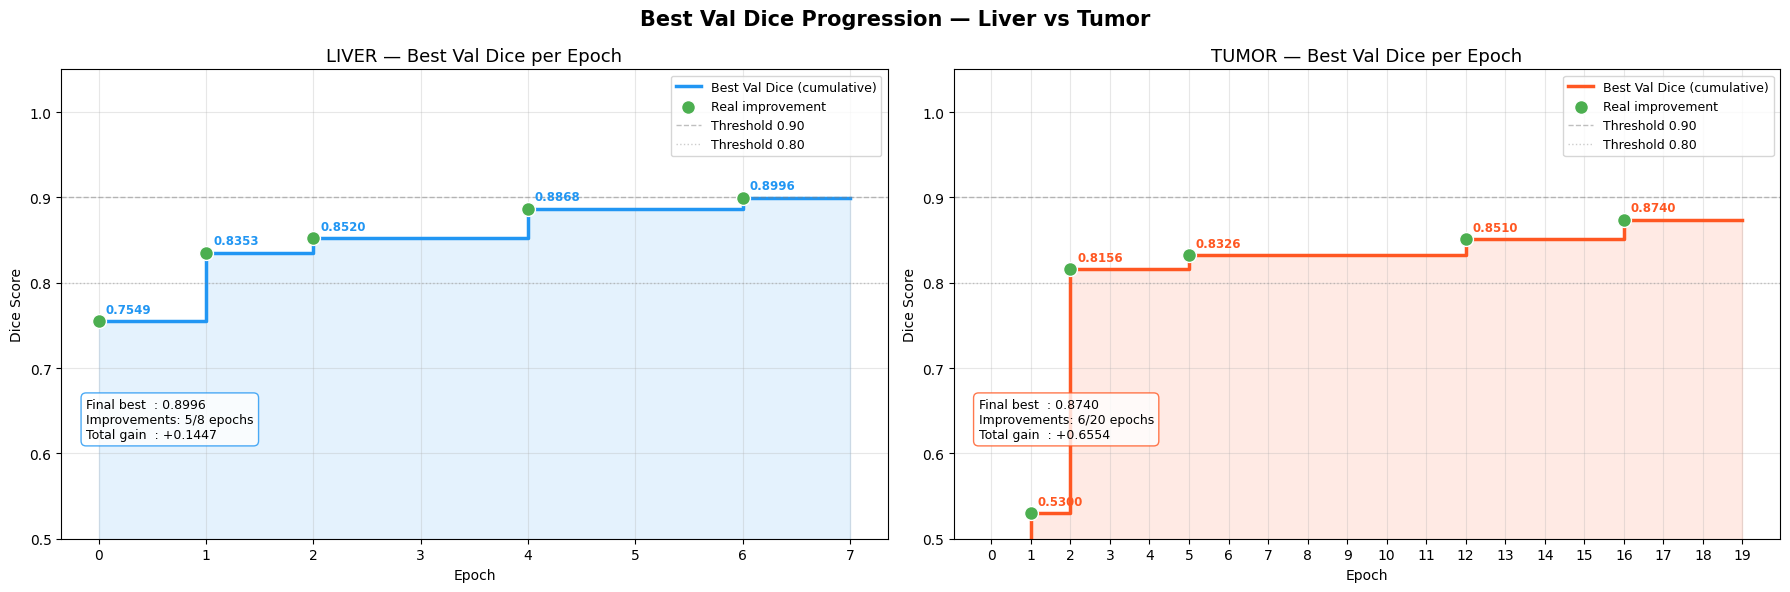

Saved: vis_01_best_dice.png


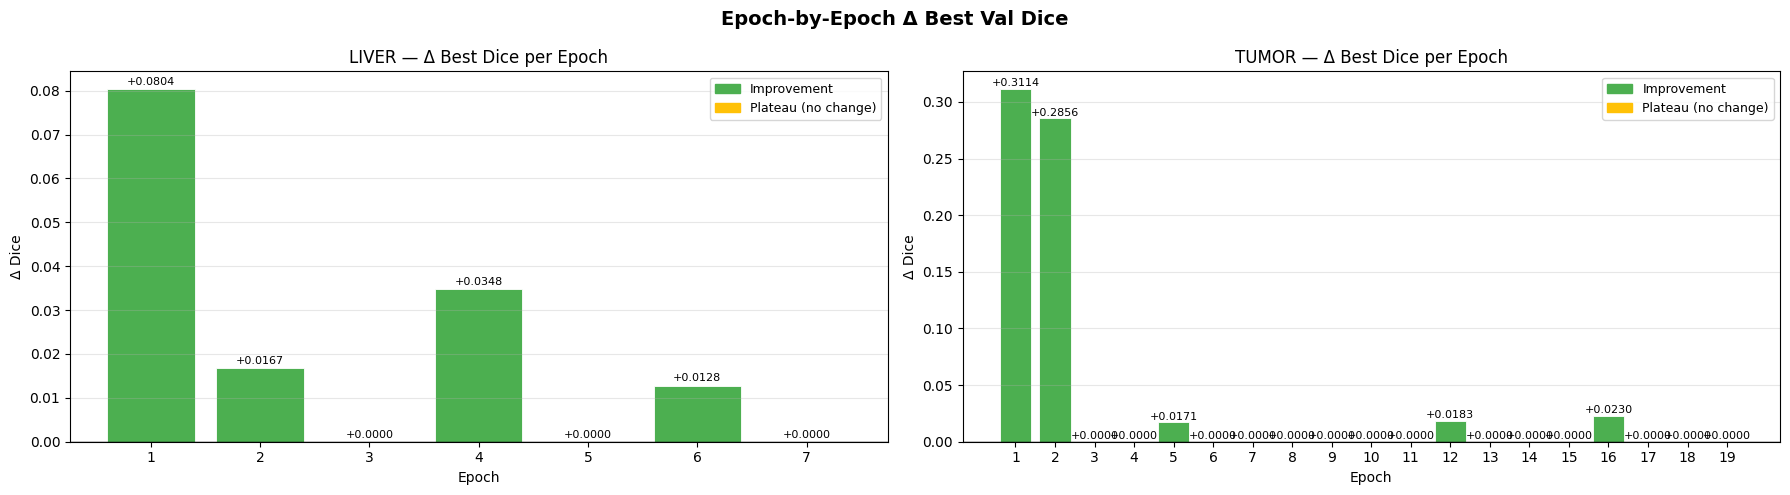

Saved: vis_02_delta_dice.png


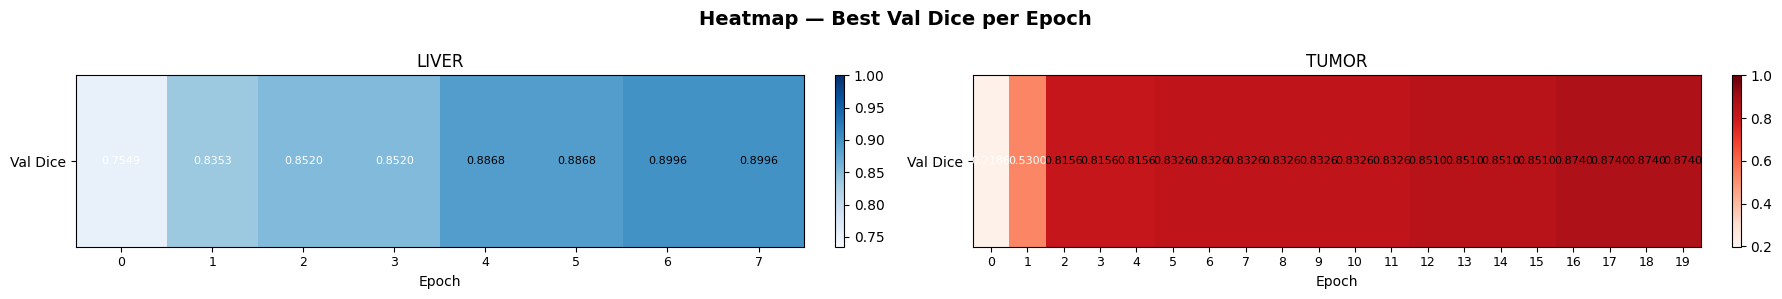

Saved: vis_03_heatmap.png


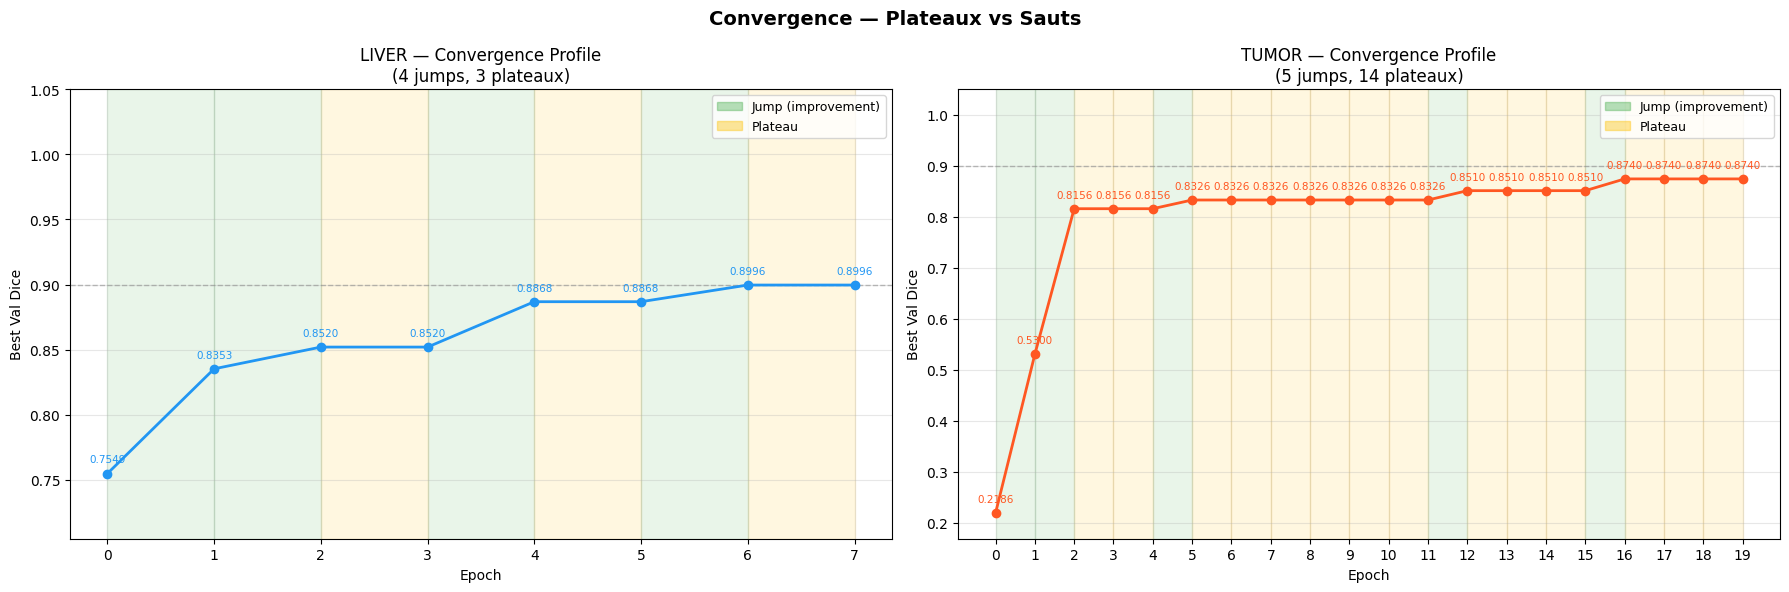

Saved: vis_04_convergence.png


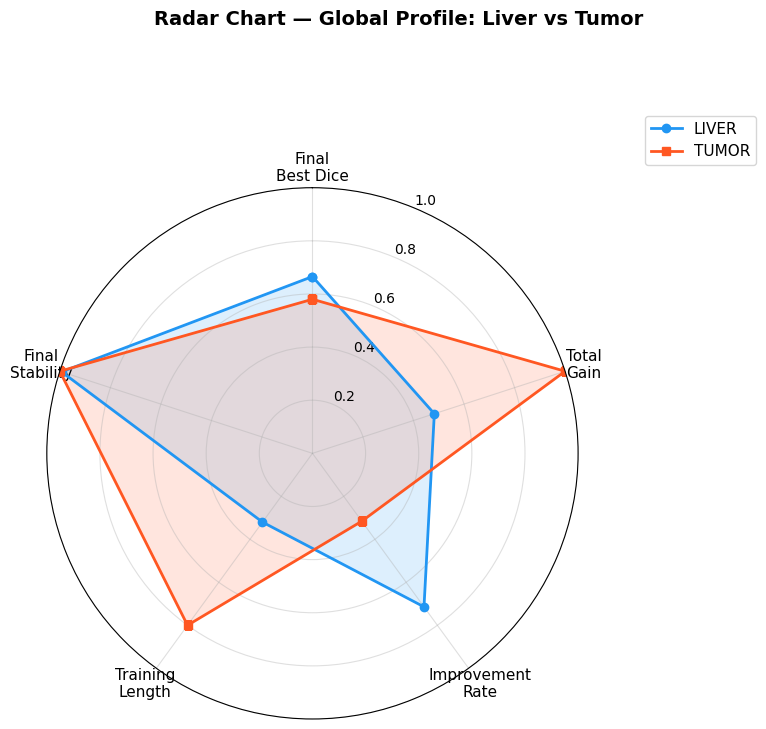

Saved: vis_05_radar.png


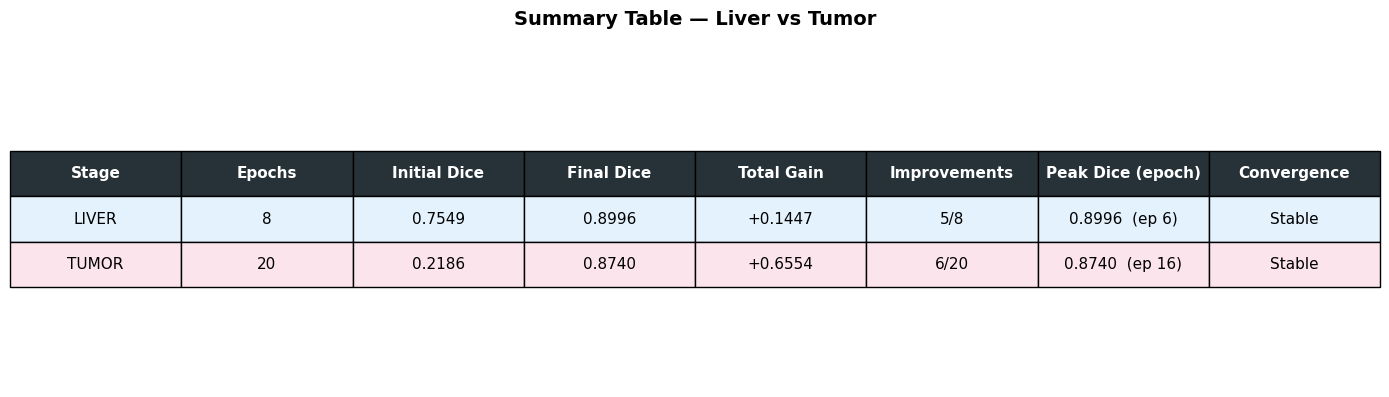

Saved: vis_06_summary_table.png

✅ All visualizations saved in outputs/


In [71]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import numpy as np
from pathlib import Path
import re

# ===== CONFIG =====
COLOR_LIVER       = "#2196F3"
COLOR_TUMOR       = "#FF5722"
COLOR_IMPROVEMENT = "#4CAF50"
COLOR_PLATEAU     = "#FFC107"
COLOR_BEST        = "#9C27B0"

def extract_epoch_num(p: Path) -> int:
    m = re.search(r"(\d+)", p.stem)
    return int(m.group(1)) if m else -1

def load_best_dice(ckpt_dir: Path):
    files = list(ckpt_dir.glob("checkpoint_epoch_*.pth")) + list(ckpt_dir.glob("epoch_*.pth"))
    files = sorted(files, key=extract_epoch_num)
    epochs, best_dices = [], []
    for f in files:
        try:
            ckpt = torch.load(f, map_location="cpu")
            ep = ckpt.get("epoch", extract_epoch_num(f))
            bd = ckpt.get("best_val_dice", None)
            if bd is not None:
                epochs.append(ep)
                best_dices.append(float(bd))
        except Exception as e:
            print(f"[WARN] {f.name}: {e}")
    return epochs, best_dices

def get_improvements(epochs, values):
    imp_ep, imp_val = [], []
    prev = -1
    for ep, val in zip(epochs, values):
        if val > prev:
            imp_ep.append(ep)
            imp_val.append(val)
            prev = val
    return imp_ep, imp_val

def compute_deltas(epochs, values):
    """Delta entre chaque epoch (0 si plateau, positif si amélioration)."""
    deltas, ep_d = [], []
    for i in range(1, len(values)):
        deltas.append(values[i] - values[i-1])
        ep_d.append(epochs[i])
    return ep_d, deltas

# ===== LOAD =====
LIVER_CKPT_DIR = Path("/no_finetuning/outputs/checkpoints_liver_attention")
TUMOR_CKPT_DIR = Path("/no_finetuning/outputs/checkpoints_tumor_attention")

liver_epochs, liver_best = load_best_dice(LIVER_CKPT_DIR)
tumor_epochs, tumor_best = load_best_dice(TUMOR_CKPT_DIR)

liver_imp_ep, liver_imp_val = get_improvements(liver_epochs, liver_best)
tumor_imp_ep, tumor_imp_val = get_improvements(tumor_epochs, tumor_best)

liver_dep, liver_deltas = compute_deltas(liver_epochs, liver_best)
tumor_dep, tumor_deltas = compute_deltas(tumor_epochs, tumor_best)

# ============================================================
# VIS 1 — COURBE PRINCIPALE (déjà existante, améliorée)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle("Best Val Dice Progression — Liver vs Tumor", fontsize=15, fontweight="bold")

for ax, epochs, values, imp_ep, imp_val, color, label in [
    (axes[0], liver_epochs, liver_best, liver_imp_ep, liver_imp_val, COLOR_LIVER, "LIVER"),
    (axes[1], tumor_epochs, tumor_best, tumor_imp_ep, tumor_imp_val, COLOR_TUMOR, "TUMOR"),
]:
    ax.step(epochs, values, where="post", color=color, lw=2.5, label="Best Val Dice (cumulative)")
    ax.fill_between(epochs, values, step="post", alpha=0.12, color=color)
    ax.scatter(imp_ep, imp_val, color=COLOR_IMPROVEMENT, zorder=5, s=100,
               label="Real improvement", edgecolors="white", lw=1)
    for ep, val in zip(imp_ep, imp_val):
        ax.annotate(f"{val:.4f}", xy=(ep, val),
                    xytext=(5, 6), textcoords="offset points",
                    fontsize=8.5, color=color, fontweight="bold")
    ax.axhline(0.90, color="gray", ls="--", lw=1, alpha=0.5, label="Threshold 0.90")
    ax.axhline(0.80, color="gray", ls=":",  lw=1, alpha=0.4, label="Threshold 0.80")
    ax.set_title(f"{label} — Best Val Dice per Epoch", fontsize=13)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Dice Score")
    ax.set_ylim(0.5, 1.05); ax.set_xticks(epochs)
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    stats = (f"Final best  : {values[-1]:.4f}\n"
             f"Improvements: {len(imp_ep)}/{len(epochs)} epochs\n"
             f"Total gain  : {values[-1] - values[0]:+.4f}")
    ax.text(0.03, 0.30, stats, transform=ax.transAxes, fontsize=9,
            verticalalignment="top",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.8, edgecolor=color))

plt.tight_layout()
plt.savefig("outputs/vis_01_best_dice.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved: vis_01_best_dice.png")


# ============================================================
# VIS 2 — DELTA DICE (barres par epoch)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
fig.suptitle("Epoch-by-Epoch Δ Best Val Dice", fontsize=14, fontweight="bold")

for ax, ep_d, deltas, color, label in [
    (axes[0], liver_dep, liver_deltas, COLOR_LIVER, "LIVER"),
    (axes[1], tumor_dep, tumor_deltas, COLOR_TUMOR, "TUMOR"),
]:
    bar_colors = [COLOR_IMPROVEMENT if d > 0 else COLOR_PLATEAU for d in deltas]
    bars = ax.bar(ep_d, deltas, color=bar_colors, edgecolor="white", linewidth=0.6)
    ax.axhline(0, color="black", lw=1)

    for bar, delta in zip(bars, deltas):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + (0.0005 if delta >= 0 else -0.002),
            f"{delta:+.4f}",
            ha="center", va="bottom" if delta >= 0 else "top",
            fontsize=8, color="black"
        )

    ax.set_title(f"{label} — Δ Best Dice per Epoch", fontsize=12)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Δ Dice")
    ax.set_xticks(ep_d)
    ax.grid(True, alpha=0.3, axis="y")

    imp_patch  = mpatches.Patch(color=COLOR_IMPROVEMENT, label="Improvement")
    plat_patch = mpatches.Patch(color=COLOR_PLATEAU,     label="Plateau (no change)")
    ax.legend(handles=[imp_patch, plat_patch], fontsize=9)

plt.tight_layout()
plt.savefig("outputs/vis_02_delta_dice.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: vis_02_delta_dice.png")


# ============================================================
# VIS 3 — HEATMAP epochs × best_val_dice
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 3))
fig.suptitle("Heatmap — Best Val Dice per Epoch", fontsize=14, fontweight="bold")

for ax, epochs, values, cmap, label in [
    (axes[0], liver_epochs, liver_best, "Blues", "LIVER"),
    (axes[1], tumor_epochs, tumor_best, "Reds",  "TUMOR"),
]:
    matrix = np.array(values).reshape(1, -1)
    im = ax.imshow(matrix, aspect="auto", cmap=cmap,
                   vmin=min(values) - 0.02, vmax=1.0, interpolation="nearest")
    ax.set_yticks([0]); ax.set_yticklabels(["Val Dice"], fontsize=10)
    ax.set_xticks(range(len(epochs)))
    ax.set_xticklabels([str(e) for e in epochs], fontsize=9)
    ax.set_xlabel("Epoch"); ax.set_title(f"{label}", fontsize=12)
    plt.colorbar(im, ax=ax, fraction=0.03, pad=0.04)

    thresh = np.mean(values)
    for j, val in enumerate(values):
        ax.text(j, 0, f"{val:.4f}", ha="center", va="center",
                fontsize=8, color="white" if val < thresh else "black")

plt.tight_layout()
plt.savefig("outputs/vis_03_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: vis_03_heatmap.png")


# ============================================================
# VIS 4 — CONVERGENCE : plateaux vs sauts
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle("Convergence — Plateaux vs Sauts", fontsize=14, fontweight="bold")

for ax, epochs, values, color, label in [
    (axes[0], liver_epochs, liver_best, COLOR_LIVER, "LIVER"),
    (axes[1], tumor_epochs, tumor_best, COLOR_TUMOR, "TUMOR"),
]:
    ax.plot(epochs, values, "o-", color=color, lw=2, ms=6, zorder=3)

    # Colorier les zones plateau vs amélioration
    prev = values[0]
    for i in range(1, len(values)):
        x_range = [epochs[i-1], epochs[i]]
        y_val   = values[i]
        is_plateau = (values[i] == prev)
        ax.axvspan(epochs[i-1], epochs[i],
                   alpha=0.12,
                   color=COLOR_PLATEAU if is_plateau else COLOR_IMPROVEMENT)
        prev = values[i]

    # Annoter chaque point
    for ep, val in zip(epochs, values):
        ax.annotate(f"{val:.4f}", xy=(ep, val),
                    xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=7.5, color=color)

    # Compter plateaux et sauts
    n_jumps    = sum(1 for i in range(1, len(values)) if values[i] > values[i-1])
    n_plateaux = len(values) - 1 - n_jumps

    ax.axhline(0.90, color="gray", ls="--", lw=1, alpha=0.5)
    ax.set_title(f"{label} — Convergence Profile\n"
                 f"({n_jumps} jumps, {n_plateaux} plateaux)", fontsize=12)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Best Val Dice")
    ax.set_ylim(min(values) - 0.05, 1.05)
    ax.set_xticks(epochs); ax.grid(True, alpha=0.3)

    imp_patch  = mpatches.Patch(color=COLOR_IMPROVEMENT, alpha=0.4, label="Jump (improvement)")
    plat_patch = mpatches.Patch(color=COLOR_PLATEAU,     alpha=0.4, label="Plateau")
    ax.legend(handles=[imp_patch, plat_patch], fontsize=9)

plt.tight_layout()
plt.savefig("outputs/vis_04_convergence.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: vis_04_convergence.png")


# ============================================================
# VIS 5 — RADAR CHART Liver vs Tumor
# ============================================================
def normalize(val, lo, hi):
    return max(0.0, min(1.0, (val - lo) / (hi - lo))) if hi > lo else 0.0

def build_radar_values(epochs, values, imp_val):
    if not values:
        return [0] * 5
    n_epochs    = len(epochs)
    n_imp       = len(imp_val)
    final_best  = values[-1]
    total_gain  = values[-1] - values[0]
    last3_var   = float(np.var(values[-3:])) if len(values) >= 3 else 0.0
    stability   = max(0.0, 1.0 - last3_var * 200)   # variance faible => stabilité haute
    improvement_rate = n_imp / (n_epochs - 1) if n_epochs > 1 else 0

    return [
        normalize(final_best,       0.70, 1.00),
        normalize(total_gain,       0.0,  0.30),
        normalize(improvement_rate, 0.0,  1.00),
        normalize(n_epochs,         0,    25),
        stability,
    ]

categories = [
    "Final\nBest Dice",
    "Total\nGain",
    "Improvement\nRate",
    "Training\nLength",
    "Final\nStability",
]

liver_radar = build_radar_values(liver_epochs, liver_best, liver_imp_val)
tumor_radar = build_radar_values(tumor_epochs, tumor_best, tumor_imp_val)

N      = len(categories)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]
liver_radar_plot = liver_radar + liver_radar[:1]
tumor_radar_plot = tumor_radar + tumor_radar[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
fig.suptitle("Radar Chart — Global Profile: Liver vs Tumor",
             fontsize=14, fontweight="bold")

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), categories, fontsize=11)

ax.plot(angles, liver_radar_plot, "o-", lw=2, color=COLOR_LIVER, label="LIVER")
ax.fill(angles, liver_radar_plot, alpha=0.15, color=COLOR_LIVER)

ax.plot(angles, tumor_radar_plot, "s-", lw=2, color=COLOR_TUMOR, label="TUMOR")
ax.fill(angles, tumor_radar_plot, alpha=0.15, color=COLOR_TUMOR)

ax.set_ylim(0, 1)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.15), fontsize=11)
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig("outputs/vis_05_radar.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved: vis_05_radar.png")


# ============================================================
# VIS 6 — TABLEAU RÉCAPITULATIF
# ============================================================
fig, ax = plt.subplots(figsize=(14, 4))
fig.suptitle("Summary Table — Liver vs Tumor", fontsize=14, fontweight="bold")
ax.axis("off")

def summary_row(label, epochs, values, imp_val):
    if not values:
        return [label] + ["N/A"] * 7
    last3_var = float(np.var(values[-3:])) if len(values) >= 3 else 0.0
    conv = "Stable" if last3_var < 0.0001 else ("Variable" if last3_var < 0.001 else "Not converged")
    return [
        label,
        str(len(epochs)),
        f"{values[0]:.4f}",
        f"{values[-1]:.4f}",
        f"{values[-1] - values[0]:+.4f}",
        f"{len(imp_val)}/{len(epochs)}",
        f"{max(values):.4f}  (ep {epochs[values.index(max(values))]})",
        conv,
    ]

col_labels = [
    "Stage", "Epochs",
    "Initial Dice", "Final Dice", "Total Gain",
    "Improvements", "Peak Dice (epoch)", "Convergence"
]

rows = [
    summary_row("LIVER", liver_epochs, liver_best, liver_imp_val),
    summary_row("TUMOR", tumor_epochs, tumor_best, tumor_imp_val),
]

table = ax.table(cellText=rows, colLabels=col_labels,
                 loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.0, 2.5)

for j in range(len(col_labels)):
    table[0, j].set_facecolor("#263238")
    table[0, j].set_text_props(color="white", fontweight="bold")

row_colors = ["#E3F2FD", "#FCE4EC"]
for i in range(len(rows)):
    for j in range(len(col_labels)):
        table[i+1, j].set_facecolor(row_colors[i])

plt.tight_layout()
plt.savefig("outputs/vis_06_summary_table.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved: vis_06_summary_table.png")

print("\n✅ All visualizations saved in outputs/")

In [74]:
ckpt = torch.load("/no_finetuning/outputs/checkpoints_liver_attention/checkpoint_epoch_001.pth", map_location="cpu")
print({k: v for k, v in ckpt.items() if not hasattr(v, 'shape') and k != 'model_state_dict' and k != 'optimizer_state_dict' and k != 'scaler_state_dict'})

{'epoch': 1, 'batch_idx': -1, 'best_val_dice': 0.8353269527430497}
